# NOTEBOOK 05 — MASS ANNOTATION AND DATASET BUILD

## 1. Mục tiêu

Notebook này thực hiện xây dựng bộ dữ liệu thực nghiệm phục vụ bài toán phát hiện và định vị tổn thương Mass trên ảnh X-quang tuyến vú thuộc bộ dữ liệu CBIS-DDSM.

Notebook tập trung vào việc chuẩn hóa quan hệ giữa bệnh nhân, ca bệnh, ảnh Full Image, annotation, lesion candidate, ROI Mask và Bounding Box trước khi triển khai mô hình học sâu.

## 2. Phạm vi dữ liệu

Phạm vi thực nghiệm ban đầu được lựa chọn là Mass theo kết quả đánh giá tại Notebook 04.

- Tổng annotation: 1.696.
- Số bệnh nhân: 892.
- Lesion candidates: 1.152.
- Annotation chưa có candidate: 122.
- Train: 713 bệnh nhân, 1.375 annotation.
- Test: 179 bệnh nhân, 321 annotation.
- Patient overlap giữa Train và Test: 0.

Calcification được giữ lại trong dữ liệu nguồn để phục vụ phân tích và mở rộng nghiên cứu khi phù hợp.

## 3. Nguyên tắc xây dựng dataset

1. Bảo toàn dữ liệu gốc và các định danh từ Notebook trước.
2. Phân biệt rõ annotation-level, image-level, lesion candidate-level và patient-level.
3. Không mặc định một annotation tương ứng với một ảnh Full Image duy nhất.
4. Không tự động loại bỏ annotation chưa có lesion candidate.
5. Không xem lesion candidate hoặc review group là xác nhận lâm sàng.
6. Chỉ sử dụng Bounding Box trong đúng hệ tọa độ đã được xác minh.
7. Không mặc định Bounding Box của ROI Mask có thể chuyển trực tiếp sang Full Image.
8. Kế thừa patient-level Train/Test split đã được kiểm tra.
9. Thiết kế Validation từ nhóm Train, không sử dụng Test trong quá trình lựa chọn mô hình.
10. Ghi nhận riêng các trường hợp chưa đủ bằng chứng để sử dụng làm Ground Truth Localization.

## 4. Giới hạn của dữ liệu định vị

Kết quả Notebook 04 cho thấy:

- 1.696 annotation Mass.
- 1.618 ROI Mask có kích thước trùng với Full Image.
- 78 ROI Mask có kích thước khác Full Image.
- Bounding Box hợp lệ và khớp vùng foreground trong ROI Mask.
- Tọa độ Bounding Box hiện được xác định trong hệ tọa độ ROI Mask.

Sự trùng khớp về kích thước không tự động chứng minh sự căn chỉnh không gian. Việc sử dụng Bounding Box trên Full Image cần có bằng chứng về quan hệ tọa độ hoặc phép biến đổi phù hợp.

## 5. Phạm vi xử lý

Notebook này thực hiện:
- Lọc dữ liệu Mass.
- Chuẩn hóa các bảng annotation và image mapping.
- Kiểm tra quan hệ bệnh nhân, ca bệnh, ảnh và tổn thương.
- Đánh giá khả năng sử dụng ROI Mask và Bounding Box.
- Kế thừa patient-level split và thiết kế Validation.
- Kiểm tra tính toàn vẹn và xuất bộ dữ liệu thực nghiệm.

In [ ]:
# 5.2 — CẤU HÌNH ĐƯỜNG DẪN, NẠP VÀ KIỂM TRA DỮ LIỆU ĐẦU VÀO

from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

# 1. XÁC ĐỊNH PROJECT ROOT.

root_candidates = []

for variable_name in ["PROJECT_ROOT", "project_root"]:

    candidate_value = globals().get(variable_name)

    if candidate_value is not None:

        try:
            root_candidates.append(Path(candidate_value).expanduser())
        except (TypeError, ValueError):
            pass

current_directory = Path.cwd()

root_candidates.append(current_directory)
root_candidates.extend(list(current_directory.parents)[:5])

PROJECT_ROOT = None

for candidate in root_candidates:
    if not candidate.is_dir():
        continue
    required_directory = (
        candidate
        / "Data"
        / "processed"
        / "nb03_lesion_dataset"
    )
    if required_directory.is_dir():
        PROJECT_ROOT = candidate.resolve()
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Không xác định được PROJECT_ROOT.\n"
        "Hãy kiểm tra thư mục Data/processed/nb03_lesion_dataset "
    )

# 2. KHAI BÁO CÁC ĐƯỜNG DẪN

DATA_DIR = PROJECT_ROOT / "Data"
METADATA_DIR = DATA_DIR / "metadata"
RAWDATA_DIR = DATA_DIR / "rawdata"
PROCESSED_DIR = DATA_DIR / "processed"

NB02_OUTPUT_DIR = (
    PROCESSED_DIR
    / "nb02_data_quality_linkage"
)

NB03_OUTPUT_DIR = (
    PROCESSED_DIR
    / "nb03_lesion_dataset"
)

NB04_OUTPUT_DIR = (
    PROCESSED_DIR
    / "nb04_eda_scope"
)

NB05_OUTPUT_DIR = (
    PROCESSED_DIR
    / "nb05_mass_annotation_dataset"
)

# Tạo thư mục đầu ra nếu chưa tồn tại.
NB05_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 60)
print("NOTEBOOK 05 — KIỂM TRA CẤU HÌNH ĐƯỜNG DẪN")
print("=" * 60)
print(f"Project root: {PROJECT_ROOT}")
print(f"Metadata directory: {METADATA_DIR}")
print(f"Rawdata directory: {RAWDATA_DIR}")
print(f"Processed directory: {PROCESSED_DIR}")

print(f"\nNotebook 02 output: {NB02_OUTPUT_DIR}")
print(f"Notebook 03 output: {NB03_OUTPUT_DIR}")
print(f"Notebook 04 output: {NB04_OUTPUT_DIR}")
print(f"Notebook 05 output: {NB05_OUTPUT_DIR}")

print(
    "\nNB03 directory exists:",
    NB03_OUTPUT_DIR.exists()
)

print(
    "NB05 output directory exists:",
    NB05_OUTPUT_DIR.exists()
)

# Kiểm tra sự tồn tại của thư mục đầu vào quan trọng.

required_directories = {
    "project": PROJECT_ROOT,
    "data": DATA_DIR,
    "processed": PROCESSED_DIR,
    "nb03_output": NB03_OUTPUT_DIR,
}

missing_directories = [
    name
    for name, directory in required_directories.items()
    if not directory.is_dir()
]

if missing_directories:

    raise FileNotFoundError(
        "Thiếu các thư mục đầu vào:\n"
        + "\n".join(missing_directories)
    )

print("\n[ĐẠT] Các thư mục đầu vào chính đều tồn tại.")

# 3. KHAI BÁO CÁC FILE ĐẦU VÀO TỪ NOTEBOOK 03

nb03_input_files = {
    "annotation_mapping": (
        NB03_OUTPUT_DIR / "lesion_annotation_mapping.csv"
    ),

    "image_mapping": (
        NB03_OUTPUT_DIR / "lesion_image_mapping.csv"
    ),

    "lesion_master": (
        NB03_OUTPUT_DIR / "lesion_master.csv"
    ),

    "review_groups": (
        NB03_OUTPUT_DIR / "lesion_review_groups.csv"
    ),

    "roi_mapping": (
        NB03_OUTPUT_DIR / "lesion_roi_mapping.csv"
    ),

    "image_path_catalog": (
        NB03_OUTPUT_DIR / "image_path_catalog.csv"
    ),
}

# Kiểm tra file trước khi đọc.

missing_input_files = [
    str(file_path)
    for file_path in nb03_input_files.values()
    if not file_path.is_file()
]

if missing_input_files:

    raise FileNotFoundError(
        "Không tìm thấy các file đầu vào Notebook 03:\n"
        + "\n".join(missing_input_files)
    )

print("\n[ĐẠT] Tìm thấy đầy đủ 6 file đầu vào Notebook 03.")

# 4. NẠP CÁC BẢNG DỮ LIỆU

loaded_tables = {}
for table_name, file_path in nb03_input_files.items():

    loaded_tables[table_name] = pd.read_csv(
        file_path,
        encoding="utf-8-sig",
        low_memory=False,
    )

# Gán tên DataFrame rõ ràng để sử dụng trong các phần tiếp theo.

nb03_annotation_mapping_df = (
    loaded_tables["annotation_mapping"]
)

nb03_image_mapping_df = (
    loaded_tables["image_mapping"]
)

nb03_lesion_master_df = (
    loaded_tables["lesion_master"]
)

nb03_review_groups_df = (
    loaded_tables["review_groups"]
)

nb03_roi_mapping_df = (
    loaded_tables["roi_mapping"]
)

nb03_image_path_catalog_df = (
    loaded_tables["image_path_catalog"]
)

# 5. KIỂM TRA SCHEMA CÁC BẢNG

required_columns = {

    "annotation_mapping": [
        "annotation_id",
        "patient_id",
        "lesion_type",
    ],

    "image_mapping": [
        "annotation_id",
        "patient_id",
        "image_view",
    ],

    "lesion_master": [
        "lesion_candidate_id",
    ],

    "review_groups": [
        "review_group_id",
    ],

    "roi_mapping": [
        "annotation_id",
        "mask_quality_status",
        "roi_mask_file_path",
        "full_image_file_path",
    ],

    "image_path_catalog": [],
}


schema_check_records = []

for table_name, df in loaded_tables.items():

    missing_columns = [
        column
        for column in required_columns[table_name]
        if column not in df.columns
    ]

    schema_check_records.append({

        "table_name": table_name,

        "row_count": len(df),

        "column_count": len(df.columns),

        "missing_required_columns": ", ".join(
            missing_columns
        ),

        "schema_status": (
            "valid"
            if not missing_columns
            else "missing_required_columns"
        ),

        "columns": ", ".join(map(str, df.columns)),
    })

input_schema_check_df = pd.DataFrame(
    schema_check_records
)

print("\n" + "=" * 60)
print("KIỂM TRA SCHEMA CÁC BẢNG ĐẦU VÀO")
print("=" * 60)

display(
    input_schema_check_df[
        [
            "table_name",
            "row_count",
            "column_count",
            "schema_status",
            "missing_required_columns",
        ]
    ]
)

schema_errors = input_schema_check_df.loc[
    input_schema_check_df["schema_status"] != "valid"
]

if not schema_errors.empty:

    display(
        schema_errors[
            [
                "table_name",
                "missing_required_columns",
                "columns",
            ]
        ]
    )

    raise ValueError(
        "Schema dữ liệu đầu vào không đáp ứng các cột định danh cần thiết."
    )

print("[ĐẠT] Các bảng có đầy đủ cột định danh cần thiết.")


# 6. KIỂM TRA SỐ DÒNG VÀ KHÓA ĐỊNH DANH

expected_row_counts = {

    "annotation_mapping": 3568,

    "image_mapping": 7136,

    "lesion_master": 1989,

    "review_groups": 140,

    "roi_mapping": 3568,

    "image_path_catalog": 6671,
}


key_columns = {

    "annotation_mapping": "annotation_id",

    "image_mapping": "annotation_id",

    "lesion_master": "lesion_candidate_id",

    "review_groups": "review_group_id",

    "roi_mapping": "annotation_id",

    "image_path_catalog": None,
}


key_check_records = []

for table_name, df in loaded_tables.items():

    key_column = key_columns[table_name]

    if key_column is None:
        continue

    key_series = df[key_column].astype("string")

    null_key_count = int(key_series.isna().sum())

    duplicated_key_count = int(
        key_series.dropna().duplicated().sum()
    )

    expected_unique = (
        table_name != "image_mapping"
    )

    if expected_unique:

        key_status = (
            "valid"
            if null_key_count == 0
            and duplicated_key_count == 0
            else "needs_review"
        )

    else:
        key_status = (
            "valid"
            if null_key_count == 0
            else "needs_review"
        )

    key_check_records.append({
        "table_name": table_name,
        "key_column": key_column,
        "null_key_count": null_key_count,
        "duplicated_key_count": duplicated_key_count,
        "key_status": key_status,
    })

input_key_check_df = pd.DataFrame(
    key_check_records
)

print("\n" + "=" * 60)
print("KIỂM TRA KHÓA ĐỊNH DANH")
print("=" * 60)
display(input_key_check_df)

key_errors = input_key_check_df.loc[
    input_key_check_df["key_status"] != "valid"
]

if not key_errors.empty:
    raise ValueError("Phát hiện vấn đề về khóa định danh trong dữ liệu đầu vào.")
print("[ĐẠT] Các khóa định danh đáp ứng quy tắc kiểm tra.")

# 7. ĐỐI CHIẾU QUY MÔ DỮ LIỆU MASS
mass_type = (
    nb03_annotation_mapping_df["lesion_type"]
    .astype("string")
    .str.strip()
    .str.lower()
)

mass_annotation_mask = mass_type.eq("mass")
mass_annotation_count = int(
    mass_annotation_mask.sum()
)

mass_patient_count = int(
    nb03_annotation_mapping_df.loc[
        mass_annotation_mask,
        "patient_id",
    ]
    .nunique()
)


print("\n" + "=" * 80)
print("ĐỐI CHIẾU PHẠM VI MASS")
print("=" * 80)

print(
    f"Tổng annotation trong bảng nguồn: "
    f"{len(nb03_annotation_mapping_df):,}"
)

print(
    f"Annotation Mass thực tế: "
    f"{mass_annotation_count:,}"
)

print(
    f"Bệnh nhân Mass thực tế: "
    f"{mass_patient_count:,}"
)

if mass_annotation_count != 1696:
    print("[CẢNH BÁO] Số annotation Mass khác kết quả Notebook 04.")

else:
    print("[ĐẠT] Số annotation Mass khớp kết quả Notebook 04.")

if mass_patient_count != 892:
    print("[CẢNH BÁO] Số bệnh nhân Mass khác kết quả Notebook 04.")

else:
    print("[ĐẠT] Số bệnh nhân Mass khớp kết quả Notebook 04.")

# 8. KIỂM TRA FILE SPLIT ĐÃ LƯU TỪ NOTEBOOK 04

patient_split_file = (
    NB04_OUTPUT_DIR / "patient_level_assignment.csv"
)

annotation_split_file = (
    NB04_OUTPUT_DIR / "annotation_split.csv"
)

patient_level_assignment_df = None
annotation_split_df = None

print("\n" + "=" * 60)
print("KIỂM TRA KẾT QUẢ PATIENT-LEVEL SPLIT")
print("=" * 60)

if patient_split_file.is_file():
    patient_level_assignment_df = pd.read_csv(
        patient_split_file,
        encoding="utf-8-sig",
        low_memory=False,
    )

    print("Đã nạp patient_level_assignment.csv:",
        f"{len(patient_level_assignment_df):,} dòng"
    )

else:
    print("[CHƯA CÓ] patient_level_assignment.csv")

if annotation_split_file.is_file():
    annotation_split_df = pd.read_csv(
        annotation_split_file,
        encoding="utf-8-sig",
        low_memory=False,
    )
    print("Đã nạp annotation_split.csv:",
        f"{len(annotation_split_df):,} dòng"
    )

else:
    print("[CHƯA CÓ] annotation_split.csv"
    )

# Kiểm tra schema khi file split đã tồn tại.

if patient_level_assignment_df is not None:

    required_patient_split_columns = {
        "patient_id",
        "experiment_split",
    }

    missing_columns = (
        required_patient_split_columns
        - set(patient_level_assignment_df.columns)
    )

    if missing_columns:

        raise ValueError(
            "Patient-level split thiếu cột: "
            f"{sorted(missing_columns)}"
        )

    if patient_level_assignment_df["patient_id"].duplicated().any():

        raise ValueError(
            "patient_level_assignment.csv có patient_id bị trùng."
        )

if annotation_split_df is not None:

    required_annotation_split_columns = {
        "annotation_id",
        "experiment_split",
    }

    missing_columns = (
        required_annotation_split_columns
        - set(annotation_split_df.columns)
    )

    if missing_columns:

        raise ValueError(
            "Annotation split thiếu cột: "
            f"{sorted(missing_columns)}"
        )

    if annotation_split_df["annotation_id"].duplicated().any():

        raise ValueError(
            "annotation_split.csv có annotation_id bị trùng."
        )

if (
    patient_level_assignment_df is not None
    and annotation_split_df is not None
):

    split_patient_ids = (
        patient_level_assignment_df["patient_id"]
        .astype("string")
    )

    split_values = (
        patient_level_assignment_df["experiment_split"]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    train_patient_ids = set(
        split_patient_ids[split_values == "train"].dropna()
    )

    test_patient_ids = set(
        split_patient_ids[split_values == "test"].dropna()
    )

    patient_overlap = (
        train_patient_ids
        & test_patient_ids
    )

    print(
        "\nSố bệnh nhân trong patient-level assignment:",
        patient_level_assignment_df["patient_id"].nunique()
    )

    print(
        "Số bệnh nhân Train:",
        len(train_patient_ids)
    )

    print(
        "Số bệnh nhân Test:",
        len(test_patient_ids)
    )

    print(
        "Patient overlap:",
        len(patient_overlap)
    )

    if patient_overlap:

        raise ValueError(
            "Phát hiện bệnh nhân xuất hiện đồng thời trong Train và Test."
        )

    print("[ĐẠT] Không phát hiện patient overlap trong split đã lưu.")

else:
    print("\n[LƯU Ý] Cần lưu hai file split từ Notebook 04 ")

# 9. KIỂM TRA ĐƯỜNG DẪN ROI MASK VÀ FULL IMAGE

path_audit_records = []
path_columns = [
    "roi_mask_file_path",
    "full_image_file_path",
]

for column in path_columns:

    if column not in nb03_roi_mapping_df.columns:
        continue

    path_series = (
        nb03_roi_mapping_df[column]
        .dropna()
        .astype("string")
        .str.strip()
    )

    unique_paths = path_series[
        path_series.ne("")
    ].drop_duplicates()

    existing_count = 0
    missing_count = 0

    for path_value in unique_paths:
        file_path = Path(str(path_value))
        if file_path.is_file():
            existing_count += 1
        else:
            missing_count += 1

    path_audit_records.append({

        "path_column": column,
        "non_null_records": len(path_series),
        "unique_path_count": len(unique_paths),
        "existing_unique_files": existing_count,
        "missing_unique_files": missing_count,
    })

input_path_audit_df = pd.DataFrame(
    path_audit_records
)

print("\n" + "=" * 60)
print("KIỂM TRA ĐƯỜNG DẪN ROI MASK VÀ FULL IMAGE")
print("=" * 60)

display(input_path_audit_df)

# 10. TỔNG HỢP KIỂM TRA ĐẦU VÀO
input_file_audit_df = pd.DataFrame([

    {
        "table_name": table_name,
        "file_name": file_path.name,
        "file_exists": file_path.is_file(),
        "row_count": len(loaded_tables[table_name]),
        "column_count": len(loaded_tables[table_name].columns),
        "file_size_mb": round(
            file_path.stat().st_size / (1024 ** 2),
            4
        ),
    }

    for table_name, file_path in nb03_input_files.items()
])

print("\n" + "=" * 60)
print("TỔNG HỢP KẾT QUẢ KIỂM TRA ĐẦU VÀO")
print("=" * 60)

display(input_file_audit_df)

input_file_audit_df.to_csv(
    NB05_OUTPUT_DIR / "nb05_input_file_audit.csv",
    index=False,
    encoding="utf-8-sig",
)

input_schema_check_df.to_csv(
    NB05_OUTPUT_DIR / "nb05_input_schema_check.csv",
    index=False,
    encoding="utf-8-sig",
)

input_key_check_df.to_csv(
    NB05_OUTPUT_DIR / "nb05_input_key_check.csv",
    index=False,
    encoding="utf-8-sig",
)

input_path_audit_df.to_csv(
    NB05_OUTPUT_DIR / "nb05_input_path_audit.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\n" + "=" * 60)
print("HOÀN THÀNH PHẦN 05.2")
print("=" * 60)

print(f"Project root: {PROJECT_ROOT}")
print(f"Mass annotations: {mass_annotation_count:,}")
print(f"Mass patients: {mass_patient_count:,}")
print(f"Output directory: {NB05_OUTPUT_DIR}")

print("\nCác DataFrame đầu vào chính:")
print("- nb03_annotation_mapping_df")
print("- nb03_image_mapping_df")
print("- nb03_lesion_master_df")
print("- nb03_review_groups_df")
print("- nb03_roi_mapping_df")
print("- nb03_image_path_catalog_df")

print("\nCác bảng kiểm tra đầu vào:")

print("- input_file_audit_df")
print("- input_schema_check_df")
print("- input_key_check_df")
print("- input_path_audit_df")

NOTEBOOK 05 — KIỂM TRA CẤU HÌNH ĐƯỜNG DẪN
Project root: C:\Breast-Cancer-CBIS-DDSM
Metadata directory: C:\Breast-Cancer-CBIS-DDSM\Data\metadata
Rawdata directory: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata
Processed directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed

Notebook 02 output: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb02_data_quality_linkage
Notebook 03 output: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb03_lesion_dataset
Notebook 04 output: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb04_eda_scope
Notebook 05 output: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset

NB03 directory exists: True
NB05 output directory exists: True

[ĐẠT] Các thư mục đầu vào chính đều tồn tại.

[ĐẠT] Tìm thấy đầy đủ 6 file đầu vào Notebook 03.

KIỂM TRA SCHEMA CÁC BẢNG ĐẦU VÀO


,table_name,row_count,column_count,schema_status,missing_required_columns
0,annotation_mapping,3568,51,valid,
1,image_mapping,7136,17,valid,
2,lesion_master,1989,42,valid,
3,review_groups,140,36,valid,
4,roi_mapping,3568,87,valid,
5,image_path_catalog,6671,4,valid,


[ĐẠT] Các bảng có đầy đủ cột định danh cần thiết.

KIỂM TRA KHÓA ĐỊNH DANH


,table_name,key_column,null_key_count,duplicated_key_count,key_status
0,annotation_mapping,annotation_id,0,0,valid
1,image_mapping,annotation_id,0,3568,valid
2,lesion_master,lesion_candidate_id,0,0,valid
3,review_groups,review_group_id,0,0,valid
4,roi_mapping,annotation_id,0,0,valid


[ĐẠT] Các khóa định danh đáp ứng quy tắc kiểm tra.

ĐỐI CHIẾU PHẠM VI MASS
Tổng annotation trong bảng nguồn: 3,568
Annotation Mass thực tế: 1,696
Bệnh nhân Mass thực tế: 892
[ĐẠT] Số annotation Mass khớp kết quả Notebook 04.
[ĐẠT] Số bệnh nhân Mass khớp kết quả Notebook 04.

KIỂM TRA KẾT QUẢ PATIENT-LEVEL SPLIT
[CHƯA CÓ] patient_level_assignment.csv
[CHƯA CÓ] annotation_split.csv

[LƯU Ý] Cần lưu hai file split từ Notebook 04 trước khi thực hiện phần 05.8.

KIỂM TRA ĐƯỜNG DẪN ROI MASK VÀ FULL IMAGE


,path_column,non_null_records,unique_path_count,existing_unique_files,missing_unique_files
0,roi_mask_file_path,3568,3568,3568,0
1,full_image_file_path,3568,3103,3103,0



TỔNG HỢP KẾT QUẢ KIỂM TRA ĐẦU VÀO


,table_name,file_name,file_exists,row_count,column_count,file_size_mb
0,annotation_mapping,lesion_annotation_mapping.csv,True,3568,51,4.9504
1,image_mapping,lesion_image_mapping.csv,True,7136,17,3.4318
2,lesion_master,lesion_master.csv,True,1989,42,1.2137
3,review_groups,lesion_review_groups.csv,True,140,36,0.0856
4,roi_mapping,lesion_roi_mapping.csv,True,3568,87,7.3921
5,image_path_catalog,image_path_catalog.csv,True,6671,4,2.3794



HOÀN THÀNH PHẦN 05.2
Project root: C:\Breast-Cancer-CBIS-DDSM
Mass annotations: 1,696
Mass patients: 892
Output directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset

Các DataFrame đầu vào chính:
- nb03_annotation_mapping_df
- nb03_image_mapping_df
- nb03_lesion_master_df
- nb03_review_groups_df
- nb03_roi_mapping_df
- nb03_image_path_catalog_df

Các bảng kiểm tra đầu vào:
- input_file_audit_df
- input_schema_check_df
- input_key_check_df
- input_path_audit_df


In [2]:
# PHẦN 05.3 — LỌC VÀ XÂY DỰNG BẢNG ANNOTATION MASS

# 1. KIỂM TRA DỮ LIỆU NGUỒN
if "nb03_annotation_mapping_df" not in globals():
    raise NameError(
        "Không tìm thấy nb03_annotation_mapping_df. "
        "Hãy thực hiện lại phần 05.2."
    )

annotation_source_df = nb03_annotation_mapping_df.copy()
required_columns = [
    "annotation_id",
    "patient_id",
    "lesion_type",
]

missing_columns = [
    column
    for column in required_columns
    if column not in annotation_source_df.columns
]
if missing_columns:
    raise ValueError(
        f"Thiếu các cột cần thiết: {missing_columns}"
    )

# 2. KIỂM TRA PHÂN BỐ LOẠI TỔN THƯƠNG NGUỒN

annotation_source_df["_lesion_type_normalized"] = (
    annotation_source_df["lesion_type"]
    .astype("string")
    .str.strip()
    .str.lower()
)

source_lesion_distribution_df = (
    annotation_source_df["_lesion_type_normalized"]
    .value_counts(dropna=False)
    .rename_axis("lesion_type")
    .reset_index(name="annotation_count")
)

print("=" * 60)
print("PHÂN BỐ LOẠI TỔN THƯƠNG TRONG DỮ LIỆU NGUỒN")
print("=" * 60)

display(source_lesion_distribution_df)

unexpected_lesion_types = (
    set(annotation_source_df["_lesion_type_normalized"].dropna().unique())
    - {"mass", "calcification"}
)
if unexpected_lesion_types:
    print(
        "[LƯU Ý] Phát hiện giá trị lesion_type ngoài hai nhóm dự kiến:",
        unexpected_lesion_types
    )

# 3. LỌC ANNOTATION MASS

mass_annotation_df = (
    annotation_source_df.loc[
        annotation_source_df["_lesion_type_normalized"].eq("mass")
    ]
    .copy()
)

# Bảo toàn giá trị lesion_type ban đầu.Thêm cột chuẩn hóa để thuận tiện cho các bước xử lý tiếp theo.

mass_annotation_df["lesion_type_normalized"] = (
    mass_annotation_df["_lesion_type_normalized"]
)

# 4. KIỂM TRA TÍNH TOÀN VẸN ANNOTATION

annotation_id_series = (
    mass_annotation_df["annotation_id"]
    .astype("string")
    .str.strip()
)

patient_id_series = (
    mass_annotation_df["patient_id"]
    .astype("string")
    .str.strip()
)

missing_annotation_id_count = int(
    (
        annotation_id_series.isna()
        | annotation_id_series.eq("").fillna(False)
    ).sum()
)

duplicated_annotation_id_count = int(
    annotation_id_series.dropna().duplicated().sum()
)

missing_patient_id_count = int(
    (
        patient_id_series.isna()
        | patient_id_series.eq("").fillna(False)
    ).sum()
)

mass_patient_count = int(
    patient_id_series[
        patient_id_series.notna()
        & patient_id_series.ne("")
    ].nunique()
)

print("\n" + "=" * 60)
print("KIỂM TRA TÍNH TOÀN VẸN ANNOTATION MASS")
print("=" * 60)

print(
    f"Tổng annotation Mass: "
    f"{len(mass_annotation_df):,}"
)

print(
    f"Unique annotation_id: "
    f"{annotation_id_series.nunique():,}"
)

print(
    f"Annotation_id thiếu: "
    f"{missing_annotation_id_count:,}"
)

print(
    f"Annotation_id trùng: "
    f"{duplicated_annotation_id_count:,}"
)

print(
    f"Patient_id thiếu: "
    f"{missing_patient_id_count:,}"
)

print(
    f"Unique patients: "
    f"{mass_patient_count:,}"
)


if missing_annotation_id_count != 0:
    raise ValueError("Phát hiện annotation_id bị thiếu.")
if duplicated_annotation_id_count != 0:
    raise ValueError("Phát hiện annotation_id bị trùng.")
if missing_patient_id_count != 0:
    raise ValueError("Phát hiện patient_id bị thiếu.")
if len(mass_annotation_df) != 1696:
    raise ValueError(
        f"Số annotation Mass không khớp: "
        f"{len(mass_annotation_df):,} thay vì 1,696."
    )
if mass_patient_count != 892:
    raise ValueError(
        f"Số bệnh nhân Mass không khớp: "
        f"{mass_patient_count:,} thay vì 892."
    )

print("[ĐẠT] Bảng annotation Mass bảo toàn 1.696 annotation và 892 bệnh nhân.")

# 5. XÁC ĐỊNH CÁC CỘT PATHOLOGY VÀ DESCRIPTOR

def find_source_column(dataframe, target_name):

    target_normalized = target_name.strip().lower()

    # Ưu tiên cột có tên chính xác.
    if target_name in dataframe.columns:
        return target_name
    # Ưu tiên cột raw__ tương ứng.
    raw_name = f"raw__{target_name}"
    if raw_name in dataframe.columns:
        return raw_name

    # Tìm theo tên đã loại bỏ tiền tố raw__.
    for column in dataframe.columns:

        normalized_name = str(column).strip().lower()
        if normalized_name.startswith("raw__"):
            normalized_name = normalized_name[5:]
        if normalized_name == target_normalized:
            return column

    return None

field_mapping = {
    field: find_source_column(
        mass_annotation_df,
        field
    )
    for field in [
        "pathology",
        "assessment",
        "subtlety",
        "mass_shape",
        "mass_margins",
    ]
}

field_mapping_df = pd.DataFrame([
    {
        "field": field,
        "source_column": source_column,
        "available": source_column is not None,
    }
    for field, source_column in field_mapping.items()
])

print("\n" + "=" * 60)
print("KIỂM TRA NGUỒN PATHOLOGY VÀ DESCRIPTOR")
print("=" * 60)
display(field_mapping_df)

# 6. THỐNG KÊ PHÂN BỐ PATHOLOGY

pathology_column = field_mapping["pathology"]
mass_pathology_summary_df = pd.DataFrame()
if pathology_column is not None:
    pathology_values = (
        mass_annotation_df[pathology_column]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    mass_pathology_summary_df = (
        pathology_values
        .value_counts(dropna=False)
        .rename_axis("pathology")
        .reset_index(name="annotation_count")
    )

    mass_pathology_summary_df["percentage"] = (
        mass_pathology_summary_df["annotation_count"]
        / len(mass_annotation_df)
        * 100
    ).round(2)

    print("\n" + "=" * 60)
    print("PHÂN BỐ PATHOLOGY — MASS")
    print("=" * 60)
    display(mass_pathology_summary_df)

else:
    print("[LƯU Ý] Không tìm thấy cột pathology trong bảng nguồn.")

# Không gộp BENIGN_WITHOUT_CALLBACK vào BENIGN. Giữ nguyên ba trạng thái pathology riêng biệt nếu có.

# 7. KIỂM TRA MỨC ĐỘ ĐẦY ĐỦ DESCRIPTOR MASS

descriptor_fields = [
    "assessment",
    "subtlety",
    "mass_shape",
    "mass_margins",
]

descriptor_records = []

for field in descriptor_fields:
    source_column = field_mapping[field]
    if source_column is None:
        continue
    values = mass_annotation_df[source_column]
    missing_mask = (
        values.isna()
        | values.astype("string").str.strip().eq("").fillna(False)
    )

    available_count = int((~missing_mask).sum())
    missing_count = int(missing_mask.sum())
    descriptor_records.append({

        "descriptor": field,
        "source_column": source_column,
        "total_annotations": len(mass_annotation_df),
        "available_count": available_count,
        "missing_count": missing_count,
        "completeness_percentage": round(
            available_count / len(mass_annotation_df) * 100,
            2
        ),

        "missing_percentage": round(
            missing_count / len(mass_annotation_df) * 100,
            2
        ),
    })

mass_descriptor_summary_df = pd.DataFrame(descriptor_records)

print("\n" + "=" * 60)
print("MỨC ĐỘ ĐẦY ĐỦ LESION DESCRIPTORS — MASS")
print("=" * 60)
display(mass_descriptor_summary_df)

# 8. KIỂM TRA THÔNG TIN LESION CANDIDATE VÀ REVIEW GROUP

candidate_column = find_source_column(
    mass_annotation_df,
    "lesion_candidate_id"
)
review_group_column = find_source_column(
    mass_annotation_df,
    "review_group_id"
)

candidate_annotation_count = None
candidate_missing_count = None
review_group_annotation_count = None
review_group_missing_count = None

if candidate_column is not None:
    candidate_values = (
        mass_annotation_df[candidate_column]
        .astype("string")
        .str.strip()
    )
    candidate_missing_mask = (
        candidate_values.isna()
        | candidate_values.eq("").fillna(False)
    )
    candidate_annotation_count = int(
        (~candidate_missing_mask).sum()
    )
    candidate_missing_count = int(
        candidate_missing_mask.sum()
    )

if review_group_column is not None:
    review_group_values = (
        mass_annotation_df[review_group_column]
        .astype("string")
        .str.strip()
    )
    review_group_missing_mask = (
        review_group_values.isna()
        | review_group_values.eq("").fillna(False)
    )
    review_group_annotation_count = int(
        (~review_group_missing_mask).sum()
    )
    review_group_missing_count = int(
        review_group_missing_mask.sum()
    )

print("\n" + "=" * 60)
print("KIỂM TRA THÔNG TIN CANDIDATE VÀ REVIEW GROUP")
print("=" * 60)

print(
    "Candidate source column:",
    candidate_column
)

print(
    "Review group source column:",
    review_group_column
)

print(
    "Annotation có candidate:",
    candidate_annotation_count
)

print(
    "Annotation chưa có candidate:",
    candidate_missing_count
)

print(
    "Annotation có review group:",
    review_group_annotation_count
)

print(
    "Annotation chưa có review group:",
    review_group_missing_count
)

print("\nLưu ý: Không loại bỏ annotation chưa có candidate hoặc review group ở phần này.")

# 9. LƯU BẢNG ANNOTATION MASS

mass_annotation_output_path = (
    NB05_OUTPUT_DIR
    / "mass_annotation_table.csv"
)

mass_annotation_df.to_csv(
    mass_annotation_output_path,
    index=False,
    encoding="utf-8-sig",
)

mass_pathology_summary_df.to_csv(
    NB05_OUTPUT_DIR / "nb05_mass_pathology_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

mass_descriptor_summary_df.to_csv(
    NB05_OUTPUT_DIR / "nb05_mass_descriptor_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

# 10. KIỂM TRA BẢO TOÀN DỮ LIỆU SAU KHI LƯU

mass_annotation_saved_df = pd.read_csv(
    mass_annotation_output_path,
    encoding="utf-8-sig",
    low_memory=False,
)

if len(mass_annotation_saved_df) != len(mass_annotation_df):
    raise ValueError(
        "Số dòng sau khi đọc lại file không khớp bảng nguồn."
    )

if (
    mass_annotation_saved_df["annotation_id"].astype("string").tolist()
    != mass_annotation_df["annotation_id"].astype("string").tolist()
):
    raise ValueError(
        "Thứ tự hoặc định danh annotation thay đổi sau khi lưu."
    )

print("\n" + "=" * 60)
print("HOÀN THÀNH 05.3 — XÂY DỰNG BẢNG ANNOTATION MASS")
print("=" * 60)

print(f"Tổng annotation Mass: {len(mass_annotation_df):,}")
print(f"Số bệnh nhân: {mass_patient_count:,}")
print(f"Annotation chưa có candidate: {candidate_missing_count}")
print(f"Annotation chưa có review group: {review_group_missing_count}")
print(f"File đầu ra: {mass_annotation_output_path}")
print("\nCác DataFrame kết quả:")
print("- mass_annotation_df")
print("- mass_pathology_summary_df")
print("- mass_descriptor_summary_df")
print("- field_mapping_df")
print("\n[ĐẠT] Bảng annotation Mass đã được lưu và kiểm tra bảo toàn dữ liệu.")

PHÂN BỐ LOẠI TỔN THƯƠNG TRONG DỮ LIỆU NGUỒN


,lesion_type,annotation_count
0,calcification,1872
1,mass,1696



KIỂM TRA TÍNH TOÀN VẸN ANNOTATION MASS
Tổng annotation Mass: 1,696
Unique annotation_id: 1,696
Annotation_id thiếu: 0
Annotation_id trùng: 0
Patient_id thiếu: 0
Unique patients: 892
[ĐẠT] Bảng annotation Mass bảo toàn 1.696 annotation và 892 bệnh nhân.

KIỂM TRA NGUỒN PATHOLOGY VÀ DESCRIPTOR


,field,source_column,available
0,pathology,pathology,True
1,assessment,assessment,True
2,subtlety,subtlety,True
3,mass_shape,mass_shape,True
4,mass_margins,mass_margins,True



PHÂN BỐ PATHOLOGY — MASS


,pathology,annotation_count,percentage
0,MALIGNANT,784,46.23
1,BENIGN,771,45.46
2,BENIGN_WITHOUT_CALLBACK,141,8.31



MỨC ĐỘ ĐẦY ĐỦ LESION DESCRIPTORS — MASS


,descriptor,source_column,total_annotations,available_count,missing_count,completeness_percentage,missing_percentage
0,assessment,assessment,1696,1696,0,100.00,0.00
1,subtlety,subtlety,1696,1696,0,100.00,0.00
2,mass_shape,mass_shape,1696,1692,4,99.76,0.24
3,mass_margins,mass_margins,1696,1636,60,96.46,3.54



KIỂM TRA THÔNG TIN CANDIDATE VÀ REVIEW GROUP
Candidate source column: lesion_candidate_id
Review group source column: review_group_id
Annotation có candidate: 1574
Annotation chưa có candidate: 122
Annotation có review group: 122
Annotation chưa có review group: 1574

Lưu ý: Không loại bỏ annotation chưa có candidate hoặc review group ở phần này.

HOÀN THÀNH 05.3 — XÂY DỰNG BẢNG ANNOTATION MASS
Tổng annotation Mass: 1,696
Số bệnh nhân: 892
Annotation chưa có candidate: 122
Annotation chưa có review group: 1574
File đầu ra: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\mass_annotation_table.csv

Các DataFrame kết quả:
- mass_annotation_df
- mass_pathology_summary_df
- mass_descriptor_summary_df
- field_mapping_df

[ĐẠT] Bảng annotation Mass đã được lưu và kiểm tra bảo toàn dữ liệu.


In [3]:
# 5.4 — XÂY DỰNG QUAN HỆ BỆNH NHÂN - CA BỆNH - ẢNH - ANNOTATION


# 1. KIỂM TRA CÁC BẢNG ĐẦU VÀO

required_objects = [
    "mass_annotation_df",
    "nb03_image_mapping_df",
    "nb03_image_path_catalog_df",
]

for object_name in required_objects:

    if object_name not in globals():
        raise NameError(
            f"Không tìm thấy {object_name}. "
            "Hãy kiểm tra các phần trước."
        )

image_mapping_source_df = (
    nb03_image_mapping_df.copy())

image_catalog_source_df = (
    nb03_image_path_catalog_df.copy())

mass_annotation_source_df = (
    mass_annotation_df.copy())

# 2. KHẢO SÁT SCHEMA IMAGE MAPPING VÀ IMAGE PATH CATALOG

print("=" * 60)
print("SCHEMA — IMAGE MAPPING")
print("=" * 60)

image_mapping_schema_df = pd.DataFrame({

    "column_name": image_mapping_source_df.columns,
    "data_type": [
        str(image_mapping_source_df[column].dtype)
        for column in image_mapping_source_df.columns
    ],
    "non_null_count": [
        int(image_mapping_source_df[column].notna().sum())
        for column in image_mapping_source_df.columns
    ],
    "unique_count": [
        int(image_mapping_source_df[column].nunique(dropna=True))
        for column in image_mapping_source_df.columns
    ],
})
display(image_mapping_schema_df)


print("\n" + "=" * 60)
print("SCHEMA — IMAGE PATH CATALOG")
print("=" * 60)

image_catalog_schema_df = pd.DataFrame({
    "column_name": image_catalog_source_df.columns,
    "data_type": [
        str(image_catalog_source_df[column].dtype)
        for column in image_catalog_source_df.columns
    ],
    "non_null_count": [
        int(image_catalog_source_df[column].notna().sum())
        for column in image_catalog_source_df.columns
    ],
    "unique_count": [
        int(image_catalog_source_df[column].nunique(dropna=True))
        for column in image_catalog_source_df.columns
    ],
})
display(image_catalog_schema_df)


# 3. KIỂM TRA CÁC CỘT LIÊN KẾT

if "annotation_id" not in image_mapping_source_df.columns:
    raise ValueError(
        "Image mapping không có annotation_id."
    )
if "annotation_id" not in mass_annotation_source_df.columns:
    raise ValueError(
        "Mass annotation không có annotation_id."
    )

if "patient_id" not in mass_annotation_source_df.columns:
    raise ValueError(
        "Mass annotation không có patient_id."
    )

# Xác định các cột trùng tên giữa image mapping và image catalog.

common_columns = sorted(
    set(image_mapping_source_df.columns)
    & set(image_catalog_source_df.columns)
)

print("\n" + "=" * 60)
print("CÁC CỘT CHUNG GIỮA IMAGE MAPPING VÀ IMAGE CATALOG")
print("=" * 60)
print(common_columns)

# 4. LỌC CÁC QUAN HỆ ẢNH THUỘC MASS

mass_annotation_ids = set(
    mass_annotation_source_df["annotation_id"]
    .astype("string")
    .str.strip()
    .dropna()
)

image_mapping_source_df["_annotation_id_key"] = (
    image_mapping_source_df["annotation_id"]
    .astype("string")
    .str.strip()
)

mass_image_mapping_df = (
    image_mapping_source_df.loc[
        image_mapping_source_df["_annotation_id_key"].isin(
            mass_annotation_ids
        )
    ]
    .copy()
)

print("\n" + "=" * 60)
print("KẾT QUẢ LỌC IMAGE MAPPING MASS")
print("=" * 60)
print(
    "Tổng bản ghi image mapping nguồn:",
    f"{len(image_mapping_source_df):,}"
)

print(
    "Số bản ghi image mapping Mass:",
    f"{len(mass_image_mapping_df):,}"
)

print(
    "Số annotation Mass được ánh xạ ảnh:",
    f"{mass_image_mapping_df['_annotation_id_key'].nunique():,}"
)

# 5. KIỂM TRA ANNOTATION KHÔNG CÓ QUAN HỆ ẢNH

mapped_annotation_ids = set(
    mass_image_mapping_df["_annotation_id_key"].dropna()
)
annotation_ids_without_image = (
    mass_annotation_ids
    - mapped_annotation_ids
)
image_annotation_ids_without_mass = (
    set(
        image_mapping_source_df["_annotation_id_key"].dropna()
    )
    - mass_annotation_ids
)

print("\n" + "=" * 80)
print("KIỂM TRA MỨC ĐỘ ĐẦY ĐỦ QUAN HỆ ANNOTATION - IMAGE")
print("=" * 80)
print(
    "Annotation Mass không có quan hệ ảnh:",
    f"{len(annotation_ids_without_image):,}"
)

print(
    "Annotation không thuộc Mass trong bảng đã lọc:",
    f"{len(image_annotation_ids_without_mass):,}"
)

if annotation_ids_without_image:

    display(
        mass_annotation_source_df.loc[
            mass_annotation_source_df["annotation_id"]
            .astype("string")
            .str.strip()
            .isin(annotation_ids_without_image)
        ].head(20)
    )

else:

    print("[ĐẠT] Tất cả annotation Mass có ít nhất một bản ghi ảnh.")

# 6. THỐNG KÊ SỐ BẢN GHI ẢNH TRÊN MỖI ANNOTATION

mass_annotation_image_count_df = (
    mass_image_mapping_df
    .groupby("_annotation_id_key", dropna=False)
    .size()
    .rename("image_relation_count")
    .reset_index()
    .rename(
        columns={
            "_annotation_id_key": "annotation_id"
        }
    )
)

mass_image_relation_distribution_df = (
    mass_annotation_image_count_df[
        "image_relation_count"
    ]
    .value_counts()
    .sort_index()
    .rename_axis("image_relation_count")
    .reset_index(name="annotation_count")
)


print("\n" + "=" * 60)
print("PHÂN BỐ SỐ BẢN GHI ẢNH TRÊN MỖI ANNOTATION MASS")
print("=" * 60)

display(mass_image_relation_distribution_df)
print(
    "\nSố annotation có quan hệ ảnh:",
    f"{len(mass_annotation_image_count_df):,}"
)
print(
    "Tổng bản ghi quan hệ ảnh:",
    f"{len(mass_image_mapping_df):,}"
)

# 7. KIỂM TRA TÍNH NHẤT QUÁN PATIENT ID
 
if "patient_id" in mass_image_mapping_df.columns:

    annotation_patient_reference_df = (
        mass_annotation_source_df[
            [
                "annotation_id",
                "patient_id",
            ]
        ]
        .copy()
    )

    annotation_patient_reference_df["annotation_id"] = (
        annotation_patient_reference_df["annotation_id"]
        .astype("string")
        .str.strip()
    )

    mass_image_mapping_df["_patient_id_key"] = (
        mass_image_mapping_df["patient_id"]
        .astype("string")
        .str.strip()
    )

    annotation_patient_reference_df["_patient_id_reference"] = (
        annotation_patient_reference_df["patient_id"]
        .astype("string")
        .str.strip()
    )

    patient_relation_check_df = (
        mass_image_mapping_df[
            [
                "_annotation_id_key",
                "_patient_id_key",
            ]
        ]
        .merge(
            annotation_patient_reference_df[
                [
                    "annotation_id",
                    "_patient_id_reference",
                ]
            ],
            left_on="_annotation_id_key",
            right_on="annotation_id",
            how="left",
            validate="many_to_one",
            indicator=True,
        )
    )

    patient_relation_check_df["patient_id_match"] = (
        patient_relation_check_df["_merge"].eq("both")
        & patient_relation_check_df["_patient_id_key"].notna()
        & patient_relation_check_df["_patient_id_reference"].notna()
        & (
            patient_relation_check_df["_patient_id_key"]
            == patient_relation_check_df["_patient_id_reference"]
        )
    )

    patient_mismatch_rows_df = (
        patient_relation_check_df.loc[
            ~patient_relation_check_df["patient_id_match"]
        ]
        .copy()
    )

    patient_relation_summary_df = pd.DataFrame([{

        "image_relation_count": len(patient_relation_check_df),

        "patient_id_match_count": int(
            patient_relation_check_df["patient_id_match"].sum()
        ),

        "patient_id_mismatch_count": len(
            patient_mismatch_rows_df
        ),

        "unique_patients_in_annotation": (
            mass_annotation_source_df["patient_id"].nunique()
        ),

        "unique_patients_in_image_mapping": (
            mass_image_mapping_df["patient_id"].nunique()
        ),
    }])

    print("\n" + "=" * 60)
    print("ĐỐI CHIẾU PATIENT ID GIỮA ANNOTATION VÀ IMAGE MAPPING")
    print("=" * 60)

    display(patient_relation_summary_df)
    if not patient_mismatch_rows_df.empty:

        print("[CẢNH BÁO] Phát hiện các quan hệ patient_id cần rà soát.")

        display(
            patient_mismatch_rows_df.head(20)
        )

    else:

        print(
            "[ĐẠT] Patient ID nhất quán giữa annotation và image mapping."
        )

else:

    patient_relation_check_df = pd.DataFrame()
    patient_mismatch_rows_df = pd.DataFrame()
    patient_relation_summary_df = pd.DataFrame()

    print(
        "\n[CHƯA ĐỦ THÔNG TIN] Image mapping không có patient_id."
    )

# 8. KIỂM TRA CÁC TRƯỜNG HỢP ẢNH ĐƯỢC CHIA SẺ

path_like_columns = [
    column
    for column in mass_image_mapping_df.columns
    if any(
        keyword in str(column).lower()
        for keyword in [
            "path",
            "file",
            "image",
            "uri",
        ]
    )
]

print("\n" + "=" * 60)
print("CÁC CỘT CÓ KHẢ NĂNG CHỨA THÔNG TIN ẢNH")
print("=" * 60)
print(path_like_columns)

shared_image_candidate_records = []
for column in path_like_columns:

    values = (
        mass_image_mapping_df[column]
        .astype("string")
        .str.strip()
    )
    temporary_df = pd.DataFrame({
        "image_identifier": values,
        "annotation_id": (
            mass_image_mapping_df["_annotation_id_key"]
        ),
    })

    temporary_df = temporary_df.loc[
        temporary_df["image_identifier"].notna()
        & temporary_df["image_identifier"].ne("")
    ]

    if temporary_df.empty:
        continue
    image_annotation_counts = (
        temporary_df
        .groupby("image_identifier")["annotation_id"]
        .nunique()
    )

    shared_image_count = int(
        (image_annotation_counts > 1).sum()
    )

    shared_image_candidate_records.append({
        "column_name": column,
        "unique_non_null_values": (
            temporary_df["image_identifier"].nunique()),
        "values_linked_to_multiple_annotations": (
            shared_image_count),"maximum_annotations_per_value": (
            int(image_annotation_counts.max())
        ),
    })

shared_image_candidate_summary_df = pd.DataFrame(
    shared_image_candidate_records
)
display(shared_image_candidate_summary_df)

# 9. XEM TRƯỚC IMAGE MAPPING MASS

print("\n" + "=" * 60)
print("XEM TRƯỚC IMAGE MAPPING MASS")
print("=" * 60)

with pd.option_context(
    "display.max_columns", None,
    "display.max_colwidth", 80,
    "display.width", 200,
):

    display(
        mass_image_mapping_df.head(10)
    )


print("\n" + "=" * 60)
print("XEM TRƯỚC IMAGE PATH CATALOG")
print("=" * 60)

with pd.option_context(
    "display.max_columns", None,
    "display.max_colwidth", 100,
    "display.width", 200,
):

    display(
        image_catalog_source_df.head(10)
    )

# 10. LƯU BẢNG QUAN HỆ ẢNH MASS

mass_image_mapping_df.to_csv(
    NB05_OUTPUT_DIR / "mass_image_mapping_source.csv",
    index=False,
    encoding="utf-8-sig",
)

mass_annotation_image_count_df.to_csv(
    NB05_OUTPUT_DIR / "mass_annotation_image_count.csv",
    index=False,
    encoding="utf-8-sig",
)

mass_image_relation_distribution_df.to_csv(
    NB05_OUTPUT_DIR / "mass_image_relation_distribution.csv",
    index=False,
    encoding="utf-8-sig",
)

patient_relation_summary_df.to_csv(
    NB05_OUTPUT_DIR / "mass_patient_relation_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

shared_image_candidate_summary_df.to_csv(
    NB05_OUTPUT_DIR / "mass_shared_image_candidate_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\n" + "=" * 80)
print("HOÀN THÀNH KIỂM TRA BAN ĐẦU PHẦN 05.4")
print("=" * 80)

print(
    "Mass annotations:",
    f"{len(mass_annotation_source_df):,}"
)

print(
    "Mass image relations:",
    f"{len(mass_image_mapping_df):,}"
)

print(
    "Annotations without image relation:",
    f"{len(annotation_ids_without_image):,}"
)

print(
    "Output directory:",
    NB05_OUTPUT_DIR
)

print("\nCác DataFrame kết quả:")
print("- image_mapping_schema_df")
print("- image_catalog_schema_df")
print("- mass_image_mapping_df")
print("- mass_annotation_image_count_df")
print("- mass_image_relation_distribution_df")
print("- patient_relation_check_df")
print("- patient_relation_summary_df")
print("- shared_image_candidate_summary_df")

SCHEMA — IMAGE MAPPING


,column_name,data_type,non_null_count,unique_count
0,annotation_id,str,7136,3568
1,lesion_candidate_id,str,5890,1989
2,review_group_id,str,1246,140
3,patient_id,str,7136,1566
4,laterality,str,7136,2
5,lesion_type,str,7136,2
6,image_view,str,7136,2
7,pathology,str,7136,3
8,source_split,str,7136,2
9,source_table,str,7136,4



SCHEMA — IMAGE PATH CATALOG


,column_name,data_type,non_null_count,unique_count
0,image_role,str,6671,2
1,image_path_key,str,6671,6671
2,image_csv_path,str,6671,6671
3,image_path_id,str,6671,6671



CÁC CỘT CHUNG GIỮA IMAGE MAPPING VÀ IMAGE CATALOG
['image_csv_path', 'image_path_id', 'image_path_key', 'image_role']

KẾT QUẢ LỌC IMAGE MAPPING MASS
Tổng bản ghi image mapping nguồn: 7,136
Số bản ghi image mapping Mass: 3,392
Số annotation Mass được ánh xạ ảnh: 1,696

KIỂM TRA MỨC ĐỘ ĐẦY ĐỦ QUAN HỆ ANNOTATION - IMAGE
Annotation Mass không có quan hệ ảnh: 0
Annotation không thuộc Mass trong bảng đã lọc: 1,872
[ĐẠT] Tất cả annotation Mass có ít nhất một bản ghi ảnh.

PHÂN BỐ SỐ BẢN GHI ẢNH TRÊN MỖI ANNOTATION MASS


,image_relation_count,annotation_count
0,2,1696


... (5 outputs left out)

,annotation_id,lesion_candidate_id,review_group_id,patient_id,laterality,lesion_type,image_view,pathology,source_split,source_table,source_csv,source_row_index,source_row_number,image_csv_path,image_role,image_path_key,image_path_id,_annotation_id_key,_patient_id_key
1872,mass_train__00001,LCAND_000001,NaN,P_00001,LEFT,mass,CC,MALIGNANT,train,mass_train,mass_case_description_train_set.csv,0,1,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807...,full_image,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807...,IMG_FULL_001873,mass_train__00001,P_00001
1873,mass_train__00002,LCAND_000001,NaN,P_00001,LEFT,mass,MLO,MALIGNANT,train,mass_train,mass_case_description_train_set.csv,1,2,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.31947899931197144242...,full_image,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.31947899931197144242...,IMG_FULL_001874,mass_train__00002,P_00001
1874,mass_train__00003,LCAND_000002,NaN,P_00004,LEFT,mass,CC,BENIGN,train,mass_train,mass_case_description_train_set.csv,2,3,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.347107867812656628709...,full_image,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.347107867812656628709...,IMG_FULL_001875,mass_train__00003,P_00004
1875,mass_train__00004,LCAND_000002,NaN,P_00004,LEFT,mass,MLO,BENIGN,train,mass_train,mass_case_description_train_set.csv,3,4,Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.27260028651181740280...,full_image,Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.27260028651181740280...,IMG_FULL_001876,mass_train__00004,P_00004
1876,mass_train__00005,LCAND_000003,NaN,P_00004,RIGHT,mass,MLO,BENIGN,train,mass_train,mass_case_description_train_set.csv,4,5,Mass-Training_P_00004_RIGHT_MLO/1.3.6.1.4.1.9590.100.1.2.1740473087121691950...,full_image,Mass-Training_P_00004_RIGHT_MLO/1.3.6.1.4.1.9590.100.1.2.1740473087121691950...,IMG_FULL_001877,mass_train__00005,P_00004
1877,mass_train__00006,LCAND_000006,NaN,P_00009,RIGHT,mass,CC,MALIGNANT,train,mass_train,mass_case_description_train_set.csv,5,6,Mass-Training_P_00009_RIGHT_CC/1.3.6.1.4.1.9590.100.1.2.34809443621298076231...,full_image,Mass-Training_P_00009_RIGHT_CC/1.3.6.1.4.1.9590.100.1.2.34809443621298076231...,IMG_FULL_001878,mass_train__00006,P_00009
1878,mass_train__00007,LCAND_000006,NaN,P_00009,RIGHT,mass,MLO,MALIGNANT,train,mass_train,mass_case_description_train_set.csv,6,7,Mass-Training_P_00009_RIGHT_MLO/1.3.6.1.4.1.9590.100.1.2.2558806681123359526...,full_image,Mass-Training_P_00009_RIGHT_MLO/1.3.6.1.4.1.9590.100.1.2.2558806681123359526...,IMG_FULL_001879,mass_train__00007,P_00009
1879,mass_train__00008,LCAND_000013,NaN,P_00015,LEFT,mass,MLO,MALIGNANT,train,mass_train,mass_case_description_train_set.csv,7,8,Mass-Training_P_00015_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.40177203641396415112...,full_image,Mass-Training_P_00015_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.40177203641396415112...,IMG_FULL_001880,mass_train__00008,P_00015
1880,mass_train__00009,LCAND_000018,NaN,P_00018,RIGHT,mass,CC,BENIGN,train,mass_train,mass_case_description_train_set.csv,8,9,Mass-Training_P_00018_RIGHT_CC/1.3.6.1.4.1.9590.100.1.2.95984463413128864010...,full_image,Mass-Training_P_00018_RIGHT_CC/1.3.6.1.4.1.9590.100.1.2.95984463413128864010...,IMG_FULL_001881,mass_train__00009,P_00018
1881,mass_train__00010,LCAND_000018,NaN,P_00018,RIGHT,mass,MLO,BENIGN,train,mass_train,mass_case_description_train_set.csv,9,10,Mass-Training_P_00018_RIGHT_MLO/1.3.6.1.4.1.9590.100.1.2.1853806828103375288...,full_image,Mass-Training_P_00018_RIGHT_MLO/1.3.6.1.4.1.9590.100.1.2.1853806828103375288...,IMG_FULL_001882,mass_train__00010,P_00018



XEM TRƯỚC IMAGE PATH CATALOG


,image_role,image_path_key,image_csv_path,image_path_id
0,cropped_image,Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.161465562211359959230647609981488894942/1.3...,Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.161465562211359959230647609981488894942/1.3...,IMG_CROP_000001
1,cropped_image,Calc-Test_P_00038_LEFT_MLO_1/1.3.6.1.4.1.9590.100.1.2.29112199613143138535387754440942211739/1.3...,Calc-Test_P_00038_LEFT_MLO_1/1.3.6.1.4.1.9590.100.1.2.29112199613143138535387754440942211739/1.3...,IMG_CROP_000002
2,cropped_image,Calc-Test_P_00038_RIGHT_CC_1/1.3.6.1.4.1.9590.100.1.2.200764632211227648028305709420627883105/1....,Calc-Test_P_00038_RIGHT_CC_1/1.3.6.1.4.1.9590.100.1.2.200764632211227648028305709420627883105/1....,IMG_CROP_000003
3,cropped_image,Calc-Test_P_00038_RIGHT_CC_2/1.3.6.1.4.1.9590.100.1.2.248538452013626298441249276382187367143/1....,Calc-Test_P_00038_RIGHT_CC_2/1.3.6.1.4.1.9590.100.1.2.248538452013626298441249276382187367143/1....,IMG_CROP_000004
4,cropped_image,Calc-Test_P_00038_RIGHT_MLO_1/1.3.6.1.4.1.9590.100.1.2.348569460311013218440657632223354965172/1...,Calc-Test_P_00038_RIGHT_MLO_1/1.3.6.1.4.1.9590.100.1.2.348569460311013218440657632223354965172/1...,IMG_CROP_000005
5,cropped_image,Calc-Test_P_00038_RIGHT_MLO_2/1.3.6.1.4.1.9590.100.1.2.57362695012780927721008884783926968463/1....,Calc-Test_P_00038_RIGHT_MLO_2/1.3.6.1.4.1.9590.100.1.2.57362695012780927721008884783926968463/1....,IMG_CROP_000006
6,cropped_image,Calc-Test_P_00041_LEFT_CC_2/1.3.6.1.4.1.9590.100.1.2.261142802012312819739743387111814412775/1.3...,Calc-Test_P_00041_LEFT_CC_2/1.3.6.1.4.1.9590.100.1.2.261142802012312819739743387111814412775/1.3...,IMG_CROP_000007
7,cropped_image,Calc-Test_P_00041_LEFT_MLO_2/1.3.6.1.4.1.9590.100.1.2.372962290011068589008332414733650487987/1....,Calc-Test_P_00041_LEFT_MLO_2/1.3.6.1.4.1.9590.100.1.2.372962290011068589008332414733650487987/1....,IMG_CROP_000008
8,cropped_image,Calc-Test_P_00077_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.169810086012222817116620676350914651179/1.3...,Calc-Test_P_00077_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.169810086012222817116620676350914651179/1.3...,IMG_CROP_000009
9,cropped_image,Calc-Test_P_00077_LEFT_MLO_1/1.3.6.1.4.1.9590.100.1.2.73175700011214399933783883971096330370/1.3...,Calc-Test_P_00077_LEFT_MLO_1/1.3.6.1.4.1.9590.100.1.2.73175700011214399933783883971096330370/1.3...,IMG_CROP_000010



HOÀN THÀNH KIỂM TRA BAN ĐẦU PHẦN 05.4
Mass annotations: 1,696
Mass image relations: 3,392
Annotations without image relation: 0
Output directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset

Các DataFrame kết quả:
- image_mapping_schema_df
- image_catalog_schema_df
- mass_image_mapping_df
- mass_annotation_image_count_df
- mass_image_relation_distribution_df
- patient_relation_check_df
- patient_relation_summary_df
- shared_image_candidate_summary_df


In [ ]:
# 5.4 — XÁC MINH VAI TRÒ VÀ QUAN HỆ GIỮA CÁC ẢNH

# 1. CHUẨN BỊ DỮ LIỆU

required_columns = [
    "annotation_id",
    "lesion_candidate_id",
    "patient_id",
    "laterality",
    "image_view",
    "image_role",
    "image_path_id",
    "image_path_key",
    "image_csv_path",
]

catalog_required_columns = [
    "image_role",
    "image_path_id",
    "image_path_key",
    "image_csv_path",
]

missing_mapping_columns = [
    column for column in required_columns
    if column not in mass_image_mapping_df.columns
]

missing_catalog_columns = [
    column for column in catalog_required_columns
    if column not in image_catalog_source_df.columns
]

if missing_mapping_columns or missing_catalog_columns:
    raise ValueError(
        f"Thiếu cột Image Mapping: {missing_mapping_columns}\n"
        f"Thiếu cột Image Catalog: {missing_catalog_columns}"
    )

mass_image_role_audit_source_df = (
    mass_image_mapping_df[required_columns].copy()
)

mass_image_catalog_audit_source_df = (
    image_catalog_source_df[catalog_required_columns].copy()
)

# Chuẩn hóa các khóa phục vụ đối chiếu.
for column in [
    "annotation_id",
    "patient_id",
    "image_role",
    "image_path_id",
    "image_path_key",
    "image_csv_path",
]:

    mass_image_role_audit_source_df[column] = (
        mass_image_role_audit_source_df[column]
        .astype("string")
        .str.strip()
    )

    if column in mass_image_catalog_audit_source_df.columns:

        mass_image_catalog_audit_source_df[column] = (
            mass_image_catalog_audit_source_df[column]
            .astype("string")
            .str.strip()
        )

# 2. KIỂM TRA KHÓA CỦA IMAGE PATH CATALOG

catalog_duplicate_id_count = int(
    mass_image_catalog_audit_source_df[
        "image_path_id"
    ].duplicated().sum()
)

catalog_missing_id_count = int(
    mass_image_catalog_audit_source_df[
        "image_path_id"
    ].isna().sum()
)

print("=" * 60)
print("KIỂM TRA KHÓA IMAGE PATH CATALOG")
print("=" * 60)
print("Số dòng catalog:", len(mass_image_catalog_audit_source_df))
print("image_path_id bị thiếu:", catalog_missing_id_count)
print("image_path_id bị trùng:", catalog_duplicate_id_count)

if catalog_duplicate_id_count > 0 or catalog_missing_id_count > 0:
    raise ValueError(
        "Image Path Catalog không có khóa image_path_id duy nhất hợp lệ."
    )

print("[ĐẠT] image_path_id trong catalog là duy nhất.")

# 3. KIỂM TRA PHÂN BỐ VAI TRÒ ẢNH

mass_image_role_summary_df = (
    mass_image_role_audit_source_df
    .groupby("image_role", dropna=False)
    .agg(
        relation_count=("image_path_id", "size"),
        unique_image_count=("image_path_id", "nunique"),
        unique_annotation_count=("annotation_id", "nunique"),
        unique_patient_count=("patient_id", "nunique"),
        unique_candidate_count=("lesion_candidate_id", "nunique"),
    )
    .reset_index()
)

mass_image_role_summary_df["extra_relations"] = (
    mass_image_role_summary_df["relation_count"]
    - mass_image_role_summary_df["unique_image_count"]
)

print("\n" + "=" * 80)
print("PHÂN BỐ VAI TRÒ ẢNH MASS")
print("=" * 80)

display(mass_image_role_summary_df)

# 4. KIỂM TRA MỖI ANNOTATION CÓ ĐỦ CÁC VAI TRÒ ẢNH

annotation_role_count_df = (
    mass_image_role_audit_source_df
    .groupby(
        ["annotation_id", "image_role"],
        dropna=False
    )
    .size()
    .unstack(fill_value=0)
)

annotation_role_count_df = (
    annotation_role_count_df
    .reset_index()
)

available_roles = [
    column
    for column in annotation_role_count_df.columns
    if column != "annotation_id"
]

expected_roles = {
    "full_image",
    "cropped_image",
}

annotation_role_count_df["total_image_relations"] = (
    annotation_role_count_df[available_roles].sum(axis=1)
)

annotation_role_count_df["role_structure_valid"] = (
    annotation_role_count_df["total_image_relations"].eq(2)
    & annotation_role_count_df.reindex(
        columns=list(expected_roles),
        fill_value=0
    ).eq(1).all(axis=1)
)

invalid_annotation_role_df = (
    annotation_role_count_df.loc[
        ~annotation_role_count_df["role_structure_valid"]
    ].copy()
)

print("\n" + "=" * 80)
print("KIỂM TRA VAI TRÒ ẢNH TRÊN TỪNG ANNOTATION")
print("=" * 80)

print("Tổng annotation Mass:", len(annotation_role_count_df))
print(
    "Annotation có đúng một Full Image và một Cropped Image:",
    int(annotation_role_count_df["role_structure_valid"].sum())
)
print(
    "Annotation có cấu trúc vai trò khác dự kiến:",
    len(invalid_annotation_role_df)
)

if not invalid_annotation_role_df.empty:
    display(invalid_annotation_role_df.head(20))

else:
    print(
        "[ĐẠT] Mỗi annotation có đúng một quan hệ Full Image "
        "và một quan hệ Cropped Image."
    )

# 5. ĐỐI CHIẾU IMAGE MAPPING VỚI IMAGE PATH CATALOG

mass_image_catalog_linkage_df = (
    mass_image_role_audit_source_df
    .merge(
        mass_image_catalog_audit_source_df.rename(
            columns={
                "image_role": "catalog_image_role",
                "image_path_key": "catalog_image_path_key",
                "image_csv_path": "catalog_image_csv_path",
            }
        ),
        on="image_path_id",
        how="left",
        validate="many_to_one",
        indicator="_catalog_merge_status",
    )
)

mass_image_catalog_linkage_df["catalog_id_found"] = (
    mass_image_catalog_linkage_df["_catalog_merge_status"]
    .eq("both")
)

mass_image_catalog_linkage_df["role_match"] = (
    mass_image_catalog_linkage_df["image_role"]
    == mass_image_catalog_linkage_df["catalog_image_role"]
)

mass_image_catalog_linkage_df["path_key_match"] = (
    mass_image_catalog_linkage_df["image_path_key"]
    == mass_image_catalog_linkage_df["catalog_image_path_key"]
)

mass_image_catalog_linkage_df["csv_path_match"] = (
    mass_image_catalog_linkage_df["image_csv_path"]
    == mass_image_catalog_linkage_df["catalog_image_csv_path"]
)

mass_image_catalog_linkage_df["catalog_link_valid"] = (
    mass_image_catalog_linkage_df["catalog_id_found"]
    & mass_image_catalog_linkage_df["role_match"]
    & mass_image_catalog_linkage_df["path_key_match"]
    & mass_image_catalog_linkage_df["csv_path_match"]
)

mass_image_catalog_linkage_summary_df = pd.DataFrame([{

    "total_image_relations": len(mass_image_catalog_linkage_df),

    "catalog_id_found": int(
        mass_image_catalog_linkage_df["catalog_id_found"].sum()
    ),

    "role_match_count": int(
        mass_image_catalog_linkage_df["role_match"].sum()
    ),

    "path_key_match_count": int(
        mass_image_catalog_linkage_df["path_key_match"].sum()
    ),

    "csv_path_match_count": int(
        mass_image_catalog_linkage_df["csv_path_match"].sum()
    ),

    "valid_catalog_relations": int(
        mass_image_catalog_linkage_df["catalog_link_valid"].sum()
    ),

    "invalid_catalog_relations": int(
        (~mass_image_catalog_linkage_df["catalog_link_valid"]).sum()
    ),
}])

print("\n" + "=" * 60)
print("ĐỐI CHIẾU IMAGE MAPPING VỚI IMAGE PATH CATALOG")
print("=" * 60)

display(mass_image_catalog_linkage_summary_df)
invalid_catalog_relations_df = (
    mass_image_catalog_linkage_df.loc[
        ~mass_image_catalog_linkage_df["catalog_link_valid"]
    ].copy()
)

if not invalid_catalog_relations_df.empty:

    display(invalid_catalog_relations_df.head(20))

    raise ValueError("Một số quan hệ ảnh không khớp Image Path Catalog")

print("[ĐẠT] Các quan hệ ảnh Mass khớp Image Path Catalog.")

# 6. KIỂM TRA ẢNH ĐƯỢC CHIA SẺ GIỮA NHIỀU ANNOTATION

shared_image_records = []

for role in sorted(
    mass_image_role_audit_source_df["image_role"]
    .dropna()
    .unique()
):

    role_df = mass_image_role_audit_source_df.loc[
        mass_image_role_audit_source_df["image_role"] == role
    ].copy()

    image_sharing_df = (
        role_df
        .groupby("image_path_id")
        .agg(
            annotation_count=("annotation_id", "nunique"),
            patient_count=("patient_id", "nunique"),
            candidate_count=("lesion_candidate_id", "nunique"),
            laterality_count=("laterality", "nunique"),
            image_view_count=("image_view", "nunique"),
        )
        .reset_index()
    )

    shared_image_df = image_sharing_df.loc[
        image_sharing_df["annotation_count"] > 1
    ].copy()

    shared_image_records.append({

        "image_role": role,
        "unique_physical_images": len(image_sharing_df),
        "shared_images": len(shared_image_df),
        "additional_annotation_relations": int(
            (shared_image_df["annotation_count"] - 1).sum()
        ),

        "maximum_annotations_per_image": int(
            image_sharing_df["annotation_count"].max()
        ),

        "images_linked_to_multiple_patients": int(
            (image_sharing_df["patient_count"] > 1).sum()
        ),
    })

mass_shared_image_role_summary_df = pd.DataFrame(
    shared_image_records
)

print("\n" + "=" * 60)
print("THỐNG KÊ ẢNH ĐƯỢC CHIA SẺ GIỮA NHIỀU ANNOTATION")
print("=" * 60)

display(mass_shared_image_role_summary_df)

# Lưu danh sách Full Image được liên kết với nhiều annotation.

full_image_rows_df = (
    mass_image_role_audit_source_df.loc[
        mass_image_role_audit_source_df["image_role"].eq("full_image")
    ].copy()
)

mass_shared_full_image_df = (
    full_image_rows_df
    .groupby("image_path_id")
    .agg(
        image_csv_path=("image_csv_path", "first"),
        patient_count=("patient_id", "nunique"),
        annotation_count=("annotation_id", "nunique"),
        candidate_count=("lesion_candidate_id", "nunique"),
        annotation_ids=(
            "annotation_id",
            lambda values: " | ".join(sorted(set(values.dropna())))
        ),
        candidate_ids=(
            "lesion_candidate_id",
            lambda values: " | ".join(sorted(set(values.dropna())))
        ),
    )
    .reset_index()
    .loc[lambda df: df["annotation_count"] > 1]
    .sort_values(
        ["annotation_count", "image_path_id"],
        ascending=[False, True]
    )
)

print(
    "\nSố Full Image được chia sẻ:",
    len(mass_shared_full_image_df)
)

display(mass_shared_full_image_df.head(20))

# 7. THỐNG KÊ SỐ ẢNH THEO BỆNH NHÂN

mass_patient_image_count_df = (
    mass_image_role_audit_source_df
    .groupby(["patient_id", "image_role"])
    .agg(
        unique_image_count=("image_path_id", "nunique"),
        annotation_count=("annotation_id", "nunique"),
    )
    .reset_index()
    .pivot(
        index="patient_id",
        columns="image_role",
        values="unique_image_count"
    )
    .fillna(0)
    .reset_index()
)

mass_patient_image_count_df.columns.name = None

role_columns = [
    column
    for column in mass_patient_image_count_df.columns
    if column != "patient_id"
]

print("\n" + "=" * 80)
print("THỐNG KÊ ẢNH DUY NHẤT THEO BỆNH NHÂN MASS")
print("=" * 80)

for column in role_columns:

    print(f"\nVai trò: {column}")

    summary = (
        mass_patient_image_count_df[column]
        .value_counts()
        .sort_index()
        .rename_axis("unique_image_count")
        .reset_index(name="patient_count")
    )

    display(summary)

# 8. KIỂM TRA KHÁC BIỆT PATIENT ID TRÊN CÙNG ẢNH

mass_image_patient_consistency_df = (
    mass_image_role_audit_source_df
    .groupby(["image_role", "image_path_id"])
    .agg(
        patient_count=("patient_id", "nunique"),
        annotation_count=("annotation_id", "nunique"),
    )
    .reset_index()
)

images_with_multiple_patients_df = (
    mass_image_patient_consistency_df.loc[
        mass_image_patient_consistency_df["patient_count"] > 1
    ].copy()
)

print("\n" + "=" * 60)
print("KIỂM TRA PATIENT ID TRÊN CÙNG ẢNH")
print("=" * 60)

print(
    "Số ảnh được gán cho nhiều patient_id:",
    len(images_with_multiple_patients_df)
)

if not images_with_multiple_patients_df.empty:

    display(images_with_multiple_patients_df.head(20))

else:

    print("[ĐẠT] Không phát hiện một image_path_id liên kết với nhiều patient_id.")

# 9. LƯU CÁC BẢNG KẾT QUẢ

mass_image_role_summary_df.to_csv(
    NB05_OUTPUT_DIR / "mass_image_role_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

annotation_role_count_df.to_csv(
    NB05_OUTPUT_DIR / "mass_annotation_image_role_check.csv",
    index=False,
    encoding="utf-8-sig",
)

mass_image_catalog_linkage_summary_df.to_csv(
    NB05_OUTPUT_DIR / "mass_image_catalog_linkage_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

mass_shared_image_role_summary_df.to_csv(
    NB05_OUTPUT_DIR / "mass_shared_image_role_summary.csv",
    index=False,
    encoding="utf-8-sig",
)

mass_shared_full_image_df.to_csv(
    NB05_OUTPUT_DIR / "mass_shared_full_image.csv",
    index=False,
    encoding="utf-8-sig",
)

mass_patient_image_count_df.to_csv(
    NB05_OUTPUT_DIR / "mass_patient_image_count.csv",
    index=False,
    encoding="utf-8-sig",
)

images_with_multiple_patients_df.to_csv(
    NB05_OUTPUT_DIR / "mass_image_patient_conflicts.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\n" + "=" * 60)
print("HOÀN THÀNH KIỂM TRA VAI TRÒ VÀ QUAN HỆ ẢNH MASS")
print("=" * 60)

print("Tổng annotation:", len(mass_annotation_df))
print("Tổng image relations:", len(mass_image_role_audit_source_df))
print("Số Full Image duy nhất:",
      int(mass_image_role_summary_df.loc[
          mass_image_role_summary_df["image_role"] == "full_image",
          "unique_image_count"
      ].sum()))

print("Số Cropped Image duy nhất:",
      int(mass_image_role_summary_df.loc[
          mass_image_role_summary_df["image_role"] == "cropped_image",
          "unique_image_count"
      ].sum()))

print("Thư mục kết quả:", NB05_OUTPUT_DIR)

print("\nCác DataFrame kết quả:")
print("- mass_image_role_summary_df")
print("- annotation_role_count_df")
print("- mass_image_catalog_linkage_summary_df")
print("- mass_shared_image_role_summary_df")
print("- mass_shared_full_image_df")
print("- mass_patient_image_count_df")
print("- images_with_multiple_patients_df")

KIỂM TRA KHÓA IMAGE PATH CATALOG
Số dòng catalog: 6671
image_path_id bị thiếu: 0
image_path_id bị trùng: 0
[ĐẠT] image_path_id trong catalog là duy nhất.

PHÂN BỐ VAI TRÒ ẢNH MASS


,image_role,relation_count,unique_image_count,unique_annotation_count,unique_patient_count,unique_candidate_count,extra_relations
0,cropped_image,1696,1696,1696,892,1152,0
1,full_image,1696,1592,1696,892,1152,104



KIỂM TRA VAI TRÒ ẢNH TRÊN TỪNG ANNOTATION
Tổng annotation Mass: 1696
Annotation có đúng một Full Image và một Cropped Image: 1696
Annotation có cấu trúc vai trò khác dự kiến: 0
[ĐẠT] Mỗi annotation có đúng một quan hệ Full Image và một quan hệ Cropped Image.

ĐỐI CHIẾU IMAGE MAPPING VỚI IMAGE PATH CATALOG


,total_image_relations,catalog_id_found,role_match_count,path_key_match_count,csv_path_match_count,valid_catalog_relations,invalid_catalog_relations
0,3392,3392,3392,3392,3392,3392,0


[ĐẠT] Các quan hệ ảnh Mass khớp Image Path Catalog.

THỐNG KÊ ẢNH ĐƯỢC CHIA SẺ GIỮA NHIỀU ANNOTATION


,image_role,unique_physical_images,shared_images,additional_annotation_relations,maximum_annotations_per_image,images_linked_to_multiple_patients
0,cropped_image,1696,0,0,1,0
1,full_image,1592,71,104,6,0


... (3 outputs left out)

,unique_image_count,patient_count
0,1,251
1,2,578
2,3,16
3,4,25
4,5,7
5,6,12
6,8,1
7,12,1
8,14,1



Vai trò: full_image


,unique_image_count,patient_count
0,1,255
1,2,598
2,3,15
3,4,24



KIỂM TRA PATIENT ID TRÊN CÙNG ẢNH
Số ảnh được gán cho nhiều patient_id: 0
[ĐẠT] Không phát hiện một image_path_id liên kết với nhiều patient_id.

HOÀN THÀNH KIỂM TRA VAI TRÒ VÀ QUAN HỆ ẢNH MASS
Tổng annotation: 1696
Tổng image relations: 3392
Số Full Image duy nhất: 1592
Số Cropped Image duy nhất: 1696
Thư mục kết quả: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset

Các DataFrame kết quả:
- mass_image_role_summary_df
- annotation_role_count_df
- mass_image_catalog_linkage_summary_df
- mass_shared_image_role_summary_df
- mass_shared_full_image_df
- mass_patient_image_count_df
- images_with_multiple_patients_df


In [14]:
# 5.5. KIỂM TRA CANDIDATE, REVIEW GROUP VÀ TÍNH NHẤT QUÁN PATIENT ID

# 1. Kiểm tra đầu vào
required_objects = [
    "mass_annotation_df",
    "nb03_lesion_master_df",
    "nb03_review_groups_df",
    "mass_image_mapping_df",
]

missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise NameError(f"Thiếu DataFrame đầu vào: {missing_objects}")

annotation = mass_annotation_df.copy()
master = nb03_lesion_master_df.copy()
review_groups = nb03_review_groups_df.copy()
image_mapping = mass_image_mapping_df.copy()

required_annotation_cols = [
    "annotation_id", "patient_id", "lesion_candidate_id", "review_group_id", "pathology"
]
required_master_cols = ["lesion_candidate_id", "_patient_key"]

for col in required_annotation_cols:
    if col not in annotation.columns:
        raise KeyError(f"mass_annotation_df thiếu cột: {col}")

for col in required_master_cols:
    if col not in master.columns:
        raise KeyError(f"nb03_lesion_master_df thiếu cột: {col}")

if "annotation_id" not in image_mapping.columns:
    raise KeyError("mass_image_mapping_df thiếu cột annotation_id")

# 2. Chuẩn hóa khóa để đối chiếu, không thay đổi dữ liệu gốc
def normalize_key(series):
    result = series.astype("string").str.strip()
    result = result.replace("", pd.NA)
    return result

annotation["_candidate_key"] = normalize_key(annotation["lesion_candidate_id"])
annotation["_patient_key_check"] = normalize_key(annotation["patient_id"])
annotation["_review_group_key"] = normalize_key(annotation["review_group_id"])

master["_candidate_key"] = normalize_key(master["lesion_candidate_id"])
master["_patient_key_check"] = normalize_key(master["_patient_key"])

# 3. Kiểm tra tính duy nhất của Candidate ID trong Lesion Master
master_candidate_duplicates = (
    master.loc[master["_candidate_key"].notna()]
    .groupby("_candidate_key")
    .size()
    .rename("master_row_count")
    .reset_index()
    .query("master_row_count > 1")
)

if not master_candidate_duplicates.empty:
    print("[WARNING] Lesion Master có Candidate ID trùng lặp.")
    display(master_candidate_duplicates.head(20))
else:
    print("[OK] Candidate ID trong Lesion Master không bị trùng.")

# 4. Đối chiếu Annotation với Lesion Master

master_patient_lookup = (
    master[["_candidate_key", "_patient_key_check"]]
    .drop_duplicates()
    .rename(columns={"_patient_key_check": "master_patient_key"})
)

mass_candidate_master_check_df = annotation[
    [
        "annotation_id",
        "patient_id",
        "lesion_candidate_id",
        "review_group_id",
        "pathology",
        "_candidate_key",
        "_patient_key_check",
        "_review_group_key",
    ]
].merge(
    master_patient_lookup,
    on="_candidate_key",
    how="left",
    indicator=True,
    validate="many_to_one",
)

# Khởi tạo trạng thái bằng object để tránh lỗi kiểu dữ liệu nullable
mass_candidate_master_check_df["patient_match_status"] = "mismatch"

condition_no_candidate = (
    mass_candidate_master_check_df["_candidate_key"].isna()
    .fillna(False)
    .to_numpy(dtype=bool)
)

condition_not_found = (
    mass_candidate_master_check_df["_merge"].eq("left_only")
    .fillna(False)
    .to_numpy(dtype=bool)
)

condition_annotation_missing = (
    mass_candidate_master_check_df["_patient_key_check"].isna()
    .fillna(False)
    .to_numpy(dtype=bool)
)

condition_master_missing = (
    mass_candidate_master_check_df["master_patient_key"].isna()
    .fillna(False)
    .to_numpy(dtype=bool)
)

condition_matched = (
    mass_candidate_master_check_df["_patient_key_check"]
    .eq(mass_candidate_master_check_df["master_patient_key"])
    .fillna(False)
    .to_numpy(dtype=bool)
)

mass_candidate_master_check_df.loc[
    condition_no_candidate, "patient_match_status"
] = "no_candidate_id"

mass_candidate_master_check_df.loc[
    ~condition_no_candidate & condition_not_found,
    "patient_match_status"
] = "candidate_not_found_in_master"

mass_candidate_master_check_df.loc[
    ~condition_no_candidate
    & ~condition_not_found
    & condition_annotation_missing,
    "patient_match_status"
] = "annotation_patient_missing"

mass_candidate_master_check_df.loc[
    ~condition_no_candidate
    & ~condition_not_found
    & ~condition_annotation_missing
    & condition_master_missing,
    "patient_match_status"
] = "master_patient_key_missing"

mass_candidate_master_check_df.loc[
    condition_matched,
    "patient_match_status"
] = "matched"

# 5. Tổng hợp kết quả đối chiếu Patient ID

mass_patient_id_check_summary_df = (
    mass_candidate_master_check_df["patient_match_status"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .reset_index(name="annotation_count")
)

candidate_linked_check_df = mass_candidate_master_check_df[
    mass_candidate_master_check_df["_candidate_key"].notna()
].copy()

candidate_patient_mismatch_df = candidate_linked_check_df[
    candidate_linked_check_df["patient_match_status"].eq("mismatch")
].copy()

candidate_patient_unverifiable_df = candidate_linked_check_df[
    ~candidate_linked_check_df["patient_match_status"].isin(
        ["matched", "mismatch"]
    )
].copy()

candidate_patient_match_count = int(
    candidate_linked_check_df["patient_match_status"].eq("matched").sum()
)

candidate_patient_mismatch_count = len(candidate_patient_mismatch_df)
candidate_linked_count = len(candidate_linked_check_df)
no_candidate_count = int(annotation["_candidate_key"].isna().sum())

print("=== PATIENT ID MATCH SUMMARY ===")
display(mass_patient_id_check_summary_df)

print(f"Tổng annotation: {len(annotation):,}")
print(f"Có Candidate ID: {candidate_linked_count:,}")
print(f"Patient ID khớp _patient_key: {candidate_patient_match_count:,}")
print(f"Patient ID sai lệch: {candidate_patient_mismatch_count:,}")
print(f"Chưa có Candidate ID: {no_candidate_count:,}")

# 6. Kiểm tra một Candidate có liên kết với nhiều Patient ID hay không
mass_candidate_patient_cardinality_df = (
    annotation.loc[
        annotation["_candidate_key"].notna()
        & annotation["_patient_key_check"].notna()
    ]
    .groupby("_candidate_key")["_patient_key_check"]
    .nunique()
    .rename("patient_id_count")
    .reset_index()
)

mass_candidate_multiple_patient_df = (
    mass_candidate_patient_cardinality_df.query("patient_id_count > 1")
    .copy()
)

# 7. Kiểm tra Candidate có nhiều nhãn Pathology hay không
mass_candidate_pathology_audit_df = (
    annotation.loc[
        annotation["_candidate_key"].notna()
        & annotation["pathology"].notna()
    ]
    .groupby("_candidate_key")
    .agg(
        annotation_count=("annotation_id", "nunique"),
        pathology_count=("pathology", "nunique"),
        pathology_values=(
            "pathology",
            lambda x: " | ".join(sorted(x.astype(str).unique()))
        ),
    )
    .reset_index()
)

mass_candidate_pathology_conflict_df = (
    mass_candidate_pathology_audit_df.query("pathology_count > 1")
    .copy()
)

# 8. Kiểm tra Review Group
review_group_column_candidates = [
    "review_group_id", "group_id", "lesion_review_group_id"
]
review_group_key_col = next(
    (c for c in review_group_column_candidates if c in review_groups.columns),
    None,
)

if review_group_key_col is not None:
    review_groups["_review_group_key"] = normalize_key(
        review_groups[review_group_key_col]
    )
    valid_review_group_keys = set(
        review_groups["_review_group_key"].dropna().unique()
    )
    annotation_review_keys = set(
        annotation["_review_group_key"].dropna().unique()
    )

    mass_review_group_check_df = annotation[
        ["annotation_id", "patient_id", "lesion_candidate_id", "review_group_id",
         "_review_group_key"]
    ].copy()

    mass_review_group_check_df["review_group_exists_in_master"] = (
        mass_review_group_check_df["_review_group_key"].isin(valid_review_group_keys)
    )

    review_group_not_found_count = int(
        (
            mass_review_group_check_df["_review_group_key"].notna()
            & ~mass_review_group_check_df["review_group_exists_in_master"]
        ).sum()
    )
else:
    mass_review_group_check_df = annotation[
        ["annotation_id", "patient_id", "lesion_candidate_id", "review_group_id"]
    ].copy()
    mass_review_group_check_df["review_group_exists_in_master"] = pd.NA
    review_group_not_found_count = pd.NA
    print(
        "[WARNING] Không xác định được tên khóa Review Group trong "
        "nb03_review_groups_df; không thực hiện kết luận về liên kết Review Group."
    )

# 9. Phân vùng annotation theo Candidate và Review Group
mass_annotation_partition_df = annotation[
    ["annotation_id", "lesion_candidate_id", "review_group_id"]
].copy()

mass_annotation_partition_df["_candidate_key"] = normalize_key(
    mass_annotation_partition_df["lesion_candidate_id"]
)
mass_annotation_partition_df["_review_group_key"] = normalize_key(
    mass_annotation_partition_df["review_group_id"]
)

mass_annotation_partition_df["partition_status"] = np.select(
    [
        mass_annotation_partition_df["_candidate_key"].notna()
        & mass_annotation_partition_df["_review_group_key"].notna(),
        mass_annotation_partition_df["_candidate_key"].notna()
        & mass_annotation_partition_df["_review_group_key"].isna(),
        mass_annotation_partition_df["_candidate_key"].isna()
        & mass_annotation_partition_df["_review_group_key"].notna(),
    ],
    [
        "both_candidate_and_review_group",
        "candidate_linked_only",
        "review_group_only",
    ],
    default="neither_candidate_nor_review_group",
)

mass_annotation_partition_summary_df = (
    mass_annotation_partition_df["partition_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="annotation_count")
)

# 10. Kiểm tra liên kết Full Image và các annotation dùng chung ảnh
if "image_role" not in image_mapping.columns:
    raise KeyError("mass_image_mapping_df thiếu cột image_role")

if "image_csv_path" not in image_mapping.columns:
    raise KeyError("mass_image_mapping_df thiếu cột image_csv_path")

image_mapping["_image_path_key"] = normalize_key(
    image_mapping["image_csv_path"]
)
image_mapping["_annotation_key"] = normalize_key(
    image_mapping["annotation_id"]
)

full_image_mapping = image_mapping[
    image_mapping["image_role"].astype(str).str.lower().eq("full_image")
].copy()

mass_shared_full_image_annotation_audit_df = (
    full_image_mapping.loc[full_image_mapping["_image_path_key"].notna()]
    .groupby("_image_path_key")
    .agg(
        annotation_count=("_annotation_key", "nunique"),
        annotation_ids=(
            "_annotation_key",
            lambda x: " | ".join(sorted(x.dropna().unique()))
        ),
        patient_count=(
            "annotation_id",
            lambda x: annotation.loc[
                annotation["annotation_id"].isin(x), "patient_id"
            ].nunique()
        ),
    )
    .reset_index()
)

mass_shared_full_image_annotation_audit_df = (
    mass_shared_full_image_annotation_audit_df.query("annotation_count > 1")
    .sort_values(["annotation_count", "_image_path_key"], ascending=[False, True])
    .reset_index(drop=True)
)

# 11. Kiểm tra pathology conflict đã biết và các trường hợp phát sinh
known_conflict_candidate = "LCAND_001662"

known_conflict_check_df = mass_candidate_pathology_audit_df[
    mass_candidate_pathology_audit_df["_candidate_key"].eq(known_conflict_candidate)
].copy()

# 12. Bảng tổng hợp tính toàn vẹn
mass_candidate_integrity_summary_df = pd.DataFrame(
    [
        ["total_annotations", len(annotation)],
        ["candidate_linked_annotations", candidate_linked_count],
        ["annotations_without_candidate_id", no_candidate_count],
        ["candidate_patient_matched", candidate_patient_match_count],
        ["candidate_patient_mismatch", candidate_patient_mismatch_count],
        ["candidate_patient_unverifiable", len(candidate_patient_unverifiable_df)],
        ["candidates_with_multiple_patient_ids", len(mass_candidate_multiple_patient_df)],
        ["unique_candidate_ids_in_annotation", annotation["_candidate_key"].nunique()],
        ["unique_review_group_ids_in_annotation", annotation["_review_group_key"].nunique()],
        ["review_group_not_found_in_master", review_group_not_found_count],
        ["candidate_pathology_conflicts", len(mass_candidate_pathology_conflict_df)],
        ["shared_full_image_count", len(mass_shared_full_image_annotation_audit_df)],
    ],
    columns=["metric", "value"],
)

# 13. Xuất kết quả
NB05_OUTPUT_DIR = Path(
    r"C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset"
)
NB05_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_tables = {
    "mass_candidate_master_check.csv": mass_candidate_master_check_df,
    "mass_patient_id_check_summary.csv": mass_patient_id_check_summary_df,
    "mass_candidate_patient_mismatch.csv": candidate_patient_mismatch_df,
    "mass_candidate_patient_unverifiable.csv": candidate_patient_unverifiable_df,
    "mass_candidate_patient_cardinality.csv": mass_candidate_patient_cardinality_df,
    "mass_candidate_multiple_patient.csv": mass_candidate_multiple_patient_df,
    "mass_candidate_pathology_audit.csv": mass_candidate_pathology_audit_df,
    "mass_candidate_pathology_conflicts.csv": mass_candidate_pathology_conflict_df,
    "mass_review_group_check.csv": mass_review_group_check_df,
    "mass_annotation_partition.csv": mass_annotation_partition_df,
    "mass_annotation_partition_summary.csv": mass_annotation_partition_summary_df,
    "mass_shared_full_image_annotation_audit.csv": mass_shared_full_image_annotation_audit_df,
    "mass_candidate_integrity_summary.csv": mass_candidate_integrity_summary_df,
}

for filename, dataframe in output_tables.items():
    dataframe.to_csv(NB05_OUTPUT_DIR / filename, index=False, encoding="utf-8-sig")

print("\n=== ANNOTATION PARTITION ===")
display(mass_annotation_partition_summary_df)

print("\n=== PATIENT ID CHECK ===")
display(mass_patient_id_check_summary_df)

print("\n=== CANDIDATE PATHOLOGY CONFLICTS ===")
display(mass_candidate_pathology_conflict_df)

print("\n=== SHARED FULL IMAGE AUDIT ===")
print(f"Số Full Image được dùng chung: {len(mass_shared_full_image_annotation_audit_df)}")
display(mass_shared_full_image_annotation_audit_df.head(10))

print("\n=== INTEGRITY SUMMARY ===")
display(mass_candidate_integrity_summary_df)

print(f"\n[OK] Đã xuất {len(output_tables)} bảng vào:")
print(NB05_OUTPUT_DIR)

[OK] Candidate ID trong Lesion Master không bị trùng.
=== PATIENT ID MATCH SUMMARY ===


,status,annotation_count
0,matched,1574
1,no_candidate_id,122


Tổng annotation: 1,696
Có Candidate ID: 1,574
Patient ID khớp _patient_key: 1,574
Patient ID sai lệch: 0
Chưa có Candidate ID: 122

=== ANNOTATION PARTITION ===


,status,annotation_count
0,candidate_linked_only,1574
1,review_group_only,122



=== PATIENT ID CHECK ===


,status,annotation_count
0,matched,1574
1,no_candidate_id,122


... (3 outputs left out)

,_image_path_key,annotation_count,annotation_ids,patient_count
0,Mass-Training_P_01039_RIGHT_MLO/1.3.6.1.4.1.95...,6,mass_train__00717 | mass_train__00718 | mass_t...,1
1,Mass-Training_P_00106_LEFT_MLO/1.3.6.1.4.1.959...,5,mass_train__00082 | mass_train__00083 | mass_t...,1
2,Mass-Training_P_01039_RIGHT_CC/1.3.6.1.4.1.959...,5,mass_train__00712 | mass_train__00713 | mass_t...,1
3,Mass-Test_P_01090_LEFT_MLO/1.3.6.1.4.1.9590.10...,4,mass_test__00226 | mass_test__00227 | mass_tes...,1
4,Mass-Training_P_00044_RIGHT_CC/1.3.6.1.4.1.959...,4,mass_train__00027 | mass_train__00028 | mass_t...,1
5,Mass-Training_P_00376_RIGHT_MLO/1.3.6.1.4.1.95...,4,mass_train__00253 | mass_train__00254 | mass_t...,1
6,Mass-Test_P_01090_LEFT_CC/1.3.6.1.4.1.9590.100...,3,mass_test__00223 | mass_test__00224 | mass_tes...,1
7,Mass-Test_P_01566_RIGHT_MLO/1.3.6.1.4.1.9590.1...,3,mass_test__00315 | mass_test__00316 | mass_tes...,1
8,Mass-Training_P_00106_LEFT_CC/1.3.6.1.4.1.9590...,3,mass_train__00079 | mass_train__00080 | mass_t...,1
9,Mass-Training_P_00106_RIGHT_CC/1.3.6.1.4.1.959...,3,mass_train__00087 | mass_train__00088 | mass_t...,1



=== INTEGRITY SUMMARY ===


,metric,value
0,total_annotations,1696
1,candidate_linked_annotations,1574
2,annotations_without_candidate_id,122
3,candidate_patient_matched,1574
4,candidate_patient_mismatch,0
5,candidate_patient_unverifiable,0
6,candidates_with_multiple_patient_ids,0
7,unique_candidate_ids_in_annotation,1152
8,unique_review_group_ids_in_annotation,32
9,review_group_not_found_in_master,0



[OK] Đã xuất 13 bảng vào:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset


In [ ]:
# 5.6. GROUND TRUTH & BOUNDING BOX COORDINATE SYSTEM

# 1. Kiểm tra đầu vào
required_objects = ["mass_annotation_df", "mass_image_mapping_df"]

missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise NameError(f"Thiếu DataFrame đầu vào: {missing_objects}")

annotation = mass_annotation_df.copy()
image_mapping = mass_image_mapping_df.copy()

if "annotation_id" not in annotation.columns:
    raise KeyError("mass_annotation_df thiếu annotation_id")

if "annotation_id" not in image_mapping.columns:
    raise KeyError("mass_image_mapping_df thiếu annotation_id")

if "image_role" not in image_mapping.columns:
    raise KeyError("mass_image_mapping_df thiếu image_role")

# 2. Xác định các DataFrame nguồn đang có trong Notebook
source_frames = {
    "mass_annotation_df": annotation,
    "mass_image_mapping_df": image_mapping,
}

optional_source_names = [
    "mass_image_role_audit_source_df",
    "mass_roi_mapping_df",
    "lesion_roi_mapping_df",
    "mass_shared_full_image_annotation_audit_df",
]

for name in optional_source_names:
    if name in globals() and isinstance(globals()[name], pd.DataFrame):
        source_frames[name] = globals()[name].copy()

print("\n=== SOURCE DATAFRAME INVENTORY ===")
for name, dataframe in source_frames.items():
    print(f"{name}: {dataframe.shape}")

# 3. Kiểm kê các cột có khả năng liên quan đến Ground Truth và tọa độ
coordinate_keywords = [
    "coord", "bbox", "bounding", "box",
    "xmin", "xmax", "ymin", "ymax",
    "x_min", "x_max", "y_min", "y_max",
    "pixel", "roi", "mask",
]

schema_records = []

for source_name, dataframe in source_frames.items():
    for column in dataframe.columns:
        column_lower = str(column).lower()

        if any(keyword in column_lower for keyword in coordinate_keywords):
            values = dataframe[column].dropna()

            schema_records.append({
                "source_dataframe": source_name,
                "column_name": column,
                "dtype": str(dataframe[column].dtype),
                "non_null_count": int(dataframe[column].notna().sum()),
                "null_count": int(dataframe[column].isna().sum()),
                "unique_count": int(dataframe[column].nunique(dropna=True)),
                "sample_values": " | ".join(
                    values.astype(str).drop_duplicates().head(5).tolist()
                ),
            })

mass_coordinate_schema_df = pd.DataFrame(schema_records)

if mass_coordinate_schema_df.empty:
    mass_coordinate_schema_df = pd.DataFrame(
        columns=[
            "source_dataframe", "column_name", "dtype",
            "non_null_count", "null_count", "unique_count", "sample_values",
        ]
    )

print("\n=== COORDINATE / ROI / MASK SCHEMA ===")
display(mass_coordinate_schema_df)

# 4. Kiểm tra giá trị các cột tọa độ và Bounding Box
coordinate_value_records = []

for source_name, dataframe in source_frames.items():
    for column in dataframe.columns:
        column_lower = str(column).lower()

        if not any(
            keyword in column_lower
            for keyword in ["coord", "bbox", "bounding", "xmin", "xmax",
                            "ymin", "ymax", "x_min", "x_max", "y_min", "y_max"]
        ):
            continue

        series = dataframe[column]
        numeric_values = pd.to_numeric(series, errors="coerce")
        non_null = series.notna()

        coordinate_value_records.append({
            "source_dataframe": source_name,
            "column_name": column,
            "non_null_count": int(non_null.sum()),
            "numeric_value_count": int(numeric_values.notna().sum()),
            "non_numeric_value_count": int(
                (non_null & numeric_values.isna()).sum()
            ),
            "minimum": numeric_values.min(),
            "maximum": numeric_values.max(),
            "sample_values": " | ".join(
                series.dropna().astype(str).drop_duplicates().head(5).tolist()
            ),
        })

mass_coordinate_value_audit_df = pd.DataFrame(coordinate_value_records)

if mass_coordinate_value_audit_df.empty:
    mass_coordinate_value_audit_df = pd.DataFrame(
        columns=[
            "source_dataframe", "column_name", "non_null_count",
            "numeric_value_count", "non_numeric_value_count",
            "minimum", "maximum", "sample_values",
        ]
    )

print("\n=== COORDINATE VALUE AUDIT ===")
display(mass_coordinate_value_audit_df)

# 5. Kiểm tra các trường liên quan đến nguồn Ground Truth
ground_truth_keywords = [
    "pathology", "assessment", "subtlety",
    "mass_shape", "mass_margins",
    "roi_mask", "mask_file", "full_image",
    "crop_image", "cropped_image",
    "bbox", "coordinate_space",
]

ground_truth_records = []

for source_name, dataframe in source_frames.items():
    for column in dataframe.columns:
        column_lower = str(column).lower()

        if any(keyword in column_lower for keyword in ground_truth_keywords):
            ground_truth_records.append({
                "source_dataframe": source_name,
                "column_name": column,
                "dtype": str(dataframe[column].dtype),
                "non_null_count": int(dataframe[column].notna().sum()),
                "null_count": int(dataframe[column].isna().sum()),
                "unique_count": int(dataframe[column].nunique(dropna=True)),
            })

mass_ground_truth_source_schema_df = pd.DataFrame(ground_truth_records)

if mass_ground_truth_source_schema_df.empty:
    mass_ground_truth_source_schema_df = pd.DataFrame(
        columns=[
            "source_dataframe", "column_name", "dtype",
            "non_null_count", "null_count", "unique_count",
        ]
    )

print("\n=== GROUND TRUTH SOURCE SCHEMA ===")
display(mass_ground_truth_source_schema_df)

# 6. Kiểm tra kích thước ảnh trong Image Mapping
dimension_keywords = [
    "width", "height", "rows", "columns",
    "dimension", "size", "pixel",
]

dimension_columns = [
    column
    for column in image_mapping.columns
    if any(keyword in str(column).lower() for keyword in dimension_keywords)
]

print("\n=== IMAGE DIMENSION COLUMNS ===")
print(dimension_columns if dimension_columns else "Không tìm thấy cột kích thước ảnh.")

dimension_records = []

for column in dimension_columns:
    numeric_values = pd.to_numeric(image_mapping[column], errors="coerce")

    dimension_records.append({
        "column_name": column,
        "dtype": str(image_mapping[column].dtype),
        "non_null_count": int(image_mapping[column].notna().sum()),
        "numeric_value_count": int(numeric_values.notna().sum()),
        "minimum": numeric_values.min(),
        "maximum": numeric_values.max(),
        "unique_count": int(numeric_values.nunique(dropna=True)),
    })

mass_image_dimension_audit_df = pd.DataFrame(dimension_records)

print("\n=== IMAGE DIMENSION AUDIT ===")
display(mass_image_dimension_audit_df)

# 7. Kiểm tra số lượng ảnh theo vai trò
image_mapping["_annotation_key"] = (
    image_mapping["annotation_id"].astype("string").str.strip()
)
image_mapping["_image_role_key"] = (
    image_mapping["image_role"].astype("string").str.strip().str.lower()
)

mass_image_role_audit_df = (
    image_mapping.groupby("_image_role_key", dropna=False)
    .agg(
        mapping_rows=("annotation_id", "size"),
        unique_annotations=("_annotation_key", "nunique"),
    )
    .reset_index()
    .rename(columns={"_image_role_key": "image_role"})
)

print("\n=== IMAGE ROLE DISTRIBUTION ===")
display(mass_image_role_audit_df)

# 8. Kiểm tra mức độ đầy đủ vai trò ảnh theo từng annotation
mass_image_role_pivot_df = (
    image_mapping.pivot_table(
        index="_annotation_key",
        columns="_image_role_key",
        values="annotation_id",
        aggfunc="count",
        fill_value=0,
    )
    .reset_index()
    .rename(columns={"_annotation_key": "annotation_id"})
)

for expected_role in ["full_image", "cropped_image"]:
    if expected_role not in mass_image_role_pivot_df.columns:
        mass_image_role_pivot_df[expected_role] = 0

mass_image_role_completeness_df = mass_image_role_pivot_df.copy()

mass_image_role_completeness_df["has_full_image"] = (
    mass_image_role_completeness_df["full_image"] > 0
)
mass_image_role_completeness_df["has_cropped_image"] = (
    mass_image_role_completeness_df["cropped_image"] > 0
)

mass_image_role_completeness_df["role_completeness_status"] = np.select(
    [
        mass_image_role_completeness_df["has_full_image"]
        & mass_image_role_completeness_df["has_cropped_image"],
        mass_image_role_completeness_df["has_full_image"],
        mass_image_role_completeness_df["has_cropped_image"],
    ],
    [
        "full_and_cropped_available",
        "full_image_only",
        "cropped_image_only",
    ],
    default="neither_role_available",
)

print("\n=== IMAGE ROLE COMPLETENESS ===")
display(
    mass_image_role_completeness_df["role_completeness_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="annotation_count")
)

# 9. Kiểm tra đường dẫn ROI Mask và Full Image nếu có trong các nguồn
path_keywords = [
    "roi_mask_file_path",
    "full_image_file_path",
    "crop_image_file_path",
    "image_csv_path",
]

path_records = []

for source_name, dataframe in source_frames.items():
    for column in dataframe.columns:
        if not any(keyword in str(column).lower() for keyword in path_keywords):
            continue

        values = dataframe[column].dropna().astype(str).str.strip()

        path_records.append({
            "source_dataframe": source_name,
            "column_name": column,
            "non_null_count": int(dataframe[column].notna().sum()),
            "unique_path_count": int(values.nunique()),
            "sample_paths": " | ".join(values.drop_duplicates().head(3).tolist()),
        })

mass_ground_truth_path_audit_df = pd.DataFrame(path_records)

if mass_ground_truth_path_audit_df.empty:
    mass_ground_truth_path_audit_df = pd.DataFrame(
        columns=[
            "source_dataframe", "column_name", "non_null_count",
            "unique_path_count", "sample_paths",
        ]
    )

print("\n=== GROUND TRUTH PATH AUDIT ===")
display(mass_ground_truth_path_audit_df)


# 10. TỔNG HỢP MỨC ĐỘ SẴN SÀNG CỦA GROUND TRUTH

def find_columns_by_keywords(dataframes, keywords):
    matches = []

    for source_name, dataframe in dataframes.items():
        for column in dataframe.columns:
            column_lower = str(column).lower()

            if any(keyword in column_lower for keyword in keywords):
                matches.append((source_name, column))

    return matches


bbox_columns = find_columns_by_keywords(
    source_frames,
    ["bbox", "bounding_box", "xmin", "xmax", "ymin", "ymax"]
)

coordinate_space_columns = find_columns_by_keywords(
    source_frames,
    ["coordinate_space", "coord_space"]
)

roi_path_columns = find_columns_by_keywords(
    source_frames,
    ["roi_mask_csv_path", "roi_mask_file_path"]
)

full_image_path_columns = find_columns_by_keywords(
    source_frames,
    ["full_image_csv_path", "full_image_file_path"]
)

crop_image_path_columns = find_columns_by_keywords(
    source_frames,
    ["crop_image_csv_path", "cropped_image_file_path"]
)

mass_ground_truth_readiness_df = pd.DataFrame([
    {
        "criterion": "Pathology label available",
        "observed": "pathology" in annotation.columns,
        "status": "available" if "pathology" in annotation.columns else "not_found",
        "interpretation": "Có nhãn bệnh lý phục vụ tác vụ phân loại.",
    },
    {
        "criterion": "Bounding Box coordinates found",
        "observed": len(bbox_columns) > 0,
        "status": "found" if bbox_columns else "not_found",
        "interpretation": "Kiểm tra các cột tọa độ Bounding Box trong DataFrame.",
    },
    {
        "criterion": "Coordinate space explicitly recorded",
        "observed": len(coordinate_space_columns) > 0,
        "status": "found" if coordinate_space_columns else "not_found",
        "interpretation": "Kiểm tra thông tin hệ tọa độ được ghi nhận.",
    },
    {
        "criterion": "ROI Mask file path found",
        "observed": len(roi_path_columns) > 0,
        "status": "found" if roi_path_columns else "not_found",
        "interpretation": "Có trường đường dẫn ROI Mask.",
    },
    {
        "criterion": "Full Image file path found",
        "observed": len(full_image_path_columns) > 0,
        "status": "found" if full_image_path_columns else "not_found",
        "interpretation": "Có trường đường dẫn Full Image.",
    },
    {
        "criterion": "Cropped Image file path found",
        "observed": len(crop_image_path_columns) > 0,
        "status": "found" if crop_image_path_columns else "not_found",
        "interpretation": "Có trường đường dẫn Cropped Image.",
    },
    {
        "criterion": "ROI Mask to Full Image spatial alignment",
        "observed": False,
        "status": "not_verified",
        "interpretation": "Chưa xác minh được ánh xạ không gian ROI Mask sang Full Image.",
    },
    {
        "criterion": "Full Image Bounding Box coordinates verified",
        "observed": False,
        "status": "not_verified",
        "interpretation": "Chưa xác minh được tọa độ Bounding Box trên Full Image.",
    },
])

print("=== GROUND TRUTH READINESS ===")
display(mass_ground_truth_readiness_df)

print("\n=== DETECTED SOURCE COLUMNS ===")
print("ROI Mask:", roi_path_columns)
print("Full Image:", full_image_path_columns)
print("Cropped Image:", crop_image_path_columns)
print("Bounding Box:", bbox_columns)
print("Coordinate Space:", coordinate_space_columns)

mass_ground_truth_readiness_df.to_csv(
    NB05_OUTPUT_DIR / "mass_ground_truth_readiness.csv",
    index=False,
    encoding="utf-8-sig"
)

# 11. Kết luận kiểm tra theo nguyên tắc bảo toàn dữ liệu
mass_ground_truth_conclusion_df = pd.DataFrame(
    [
        [
            "Classification Ground Truth",
            "pathology",
            "Có thể tiếp tục kiểm tra nhãn benign/malignant.",
        ],
        [
            "Localization Ground Truth",
            "Bounding Box",
            "Chưa xác nhận hệ tọa độ Full Image.",
        ],
        [
            "ROI Mask",
            "roi_mask_file_path",
            "Là nguồn annotation vùng ROI; không tự suy ra tọa độ Full Image.",
        ],
        [
            "ROI Mask to Full Image",
            "Spatial alignment",
            "Chưa xác minh; không chuyển tọa độ tự động.",
        ],
        [
            "Image dimension",
            "Width / Height",
            "Kích thước bằng nhau không chứng minh ảnh cùng hệ tọa độ.",
        ],
    ],
    columns=["component", "source_or_concept", "conclusion"],
)

print("\n=== GROUND TRUTH CONCLUSION ===")
display(mass_ground_truth_conclusion_df)

# 12. Xuất kết quả
NB05_OUTPUT_DIR = Path(
    r"C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset"
)
NB05_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_tables = {
    "mass_coordinate_schema.csv": mass_coordinate_schema_df,
    "mass_coordinate_value_audit.csv": mass_coordinate_value_audit_df,
    "mass_ground_truth_source_schema.csv": mass_ground_truth_source_schema_df,
    "mass_image_dimension_audit.csv": mass_image_dimension_audit_df,
    "mass_image_role_audit.csv": mass_image_role_audit_df,
    "mass_image_role_pivot.csv": mass_image_role_pivot_df,
    "mass_image_role_completeness.csv": mass_image_role_completeness_df,
    "mass_ground_truth_path_audit.csv": mass_ground_truth_path_audit_df,
    "mass_ground_truth_readiness.csv": mass_ground_truth_readiness_df,
    "mass_ground_truth_conclusion.csv": mass_ground_truth_conclusion_df,
}

for filename, dataframe in output_tables.items():
    dataframe.to_csv(NB05_OUTPUT_DIR / filename, index=False, encoding="utf-8-sig")

print(f"\n[OK] Đã xuất {len(output_tables)} bảng vào:")
print(NB05_OUTPUT_DIR)

print("\n[IMPORTANT]")
print("Cell này chỉ kiểm tra schema, giá trị, nguồn ảnh và mức độ sẵn sàng")


=== SOURCE DATAFRAME INVENTORY ===
mass_annotation_df: (1696, 53)
mass_image_mapping_df: (3392, 19)
mass_image_role_audit_source_df: (3392, 9)
mass_shared_full_image_annotation_audit_df: (71, 4)

=== COORDINATE / ROI / MASK SCHEMA ===


,source_dataframe,column_name,dtype,non_null_count,null_count,unique_count,sample_values
0,mass_annotation_df,roi_mask_csv_path,str,1696,0,1696,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...
1,mass_annotation_df,raw__ROI mask file path,str,1696,0,1696,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...



=== COORDINATE VALUE AUDIT ===


,source_dataframe,column_name,non_null_count,numeric_value_count,non_numeric_value_count,minimum,maximum,sample_values



=== GROUND TRUTH SOURCE SCHEMA ===


,source_dataframe,column_name,dtype,non_null_count,null_count,unique_count
0,mass_annotation_df,assessment,int64,1696,0,6
1,mass_annotation_df,pathology,str,1696,0,3
2,mass_annotation_df,subtlety,int64,1696,0,6
3,mass_annotation_df,full_image_csv_path,str,1696,0,1592
4,mass_annotation_df,crop_image_csv_path,str,1696,0,1696
5,mass_annotation_df,roi_mask_csv_path,str,1696,0,1696
6,mass_annotation_df,raw__assessment,int64,1696,0,6
7,mass_annotation_df,raw__pathology,str,1696,0,3
8,mass_annotation_df,raw__subtlety,int64,1696,0,6
9,mass_annotation_df,mass_shape,str,1692,4,20


... (9 outputs left out)

,criterion,observed,status,interpretation
0,Pathology label available,True,available,Có nhãn bệnh lý phục vụ tác vụ phân loại.
1,Bounding Box coordinates found,False,not_found,Kiểm tra các cột tọa độ Bounding Box trong Dat...
2,Coordinate space explicitly recorded,False,not_found,Kiểm tra thông tin hệ tọa độ được ghi nhận.
3,ROI Mask file path found,True,found,Có trường đường dẫn ROI Mask.
4,Full Image file path found,True,found,Có trường đường dẫn Full Image.
5,Cropped Image file path found,True,found,Có trường đường dẫn Cropped Image.
6,ROI Mask to Full Image spatial alignment,False,not_verified,Chưa xác minh được ánh xạ không gian ROI Mask ...
7,Full Image Bounding Box coordinates verified,False,not_verified,Chưa xác minh được tọa độ Bounding Box trên Fu...



=== DETECTED SOURCE COLUMNS ===
ROI Mask: [('mass_annotation_df', 'roi_mask_csv_path')]
Full Image: [('mass_annotation_df', 'full_image_csv_path')]
Cropped Image: [('mass_annotation_df', 'crop_image_csv_path')]
Bounding Box: []
Coordinate Space: []

=== GROUND TRUTH CONCLUSION ===


,component,source_or_concept,conclusion
0,Classification Ground Truth,pathology,Có thể tiếp tục kiểm tra nhãn benign/malignant.
1,Localization Ground Truth,Bounding Box,Chưa xác nhận hệ tọa độ Full Image.
2,ROI Mask,roi_mask_file_path,Là nguồn annotation vùng ROI; không tự suy ra ...
3,ROI Mask to Full Image,Spatial alignment,Chưa xác minh; không chuyển tọa độ tự động.
4,Image dimension,Width / Height,Kích thước bằng nhau không chứng minh ảnh cùng...



[OK] Đã xuất 10 bảng vào:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset

[IMPORTANT]
Cell này chỉ kiểm tra schema, giá trị, nguồn ảnh và mức độ sẵn sàng


In [24]:
# 05.7.1 — NẠP MAPPING ẢNH ĐÃ XÁC MINH

from pathlib import Path
import pandas as pd
import numpy as np
import pydicom
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
PROCESSED_DIR = PROJECT_ROOT / "Data" / "processed"

NB04_AUDIT_DIR = (
    PROCESSED_DIR /
    "supplementary_image_role_audit_20261105_002929_370953"
)

NB05_OUTPUT_DIR = (
    PROCESSED_DIR / "nb05_mass_annotation_dataset"
)

VISUAL_IMAGE_MAPPING_PATH = (
    NB04_AUDIT_DIR / "visual_image_mapping.csv"
)

VISUAL_ROI_MAPPING_PATH = (
    NB04_AUDIT_DIR / "visual_roi_mapping.csv"
)

for path in [
    VISUAL_IMAGE_MAPPING_PATH,
    VISUAL_ROI_MAPPING_PATH,
]:
    if not path.is_file():
        raise FileNotFoundError(path)

if "mass_annotation_df" not in globals():
    raise NameError(
        "Cần chạy các phần Notebook 05.1–05.6 trước."
    )

visual_image_mapping_df = pd.read_csv(
    VISUAL_IMAGE_MAPPING_PATH,
    low_memory=False
)

visual_roi_mapping_df = pd.read_csv(
    VISUAL_ROI_MAPPING_PATH,
    low_memory=False
)

required_image_columns = {
    "annotation_id",
    "image_role",
    "_image_path",
}

required_roi_columns = {
    "annotation_id",
    "_image_path",
}

if not required_image_columns.issubset(
    visual_image_mapping_df.columns
):
    raise ValueError(
        "Schema visual_image_mapping.csv không đúng."
    )

if not required_roi_columns.issubset(
    visual_roi_mapping_df.columns
):
    raise ValueError(
        "Schema visual_roi_mapping.csv không đúng."
    )

mass_annotation_ids = set(
    mass_annotation_df["annotation_id"]
    .dropna()
    .astype(str)
)

visual_image_mapping_df["annotation_id"] = (
    visual_image_mapping_df["annotation_id"].astype(str)
)

visual_roi_mapping_df["annotation_id"] = (
    visual_roi_mapping_df["annotation_id"].astype(str)
)

mass_visual_image_mapping_df = (
    visual_image_mapping_df[
        visual_image_mapping_df["annotation_id"].isin(
            mass_annotation_ids
        )
    ].copy()
)

mass_visual_roi_mapping_df = (
    visual_roi_mapping_df[
        visual_roi_mapping_df["annotation_id"].isin(
            mass_annotation_ids
        )
    ].copy()
)

mass_visual_image_mapping_df["_image_path"] = (
    mass_visual_image_mapping_df["_image_path"]
    .fillna("")
    .astype(str)
    .str.strip()
)

mass_visual_roi_mapping_df["_image_path"] = (
    mass_visual_roi_mapping_df["_image_path"]
    .fillna("")
    .astype(str)
    .str.strip()
)

print("=== NOTEBOOK 05.7 — INPUT SUMMARY ===")
print("Mass annotations:", len(mass_annotation_ids))
print("Image mapping rows:", len(mass_visual_image_mapping_df))
print("ROI mapping rows:", len(mass_visual_roi_mapping_df))

print("\nImage role distribution:")
display(
    mass_visual_image_mapping_df["image_role"]
    .value_counts(dropna=False)
    .rename_axis("image_role")
    .to_frame("count")
)

print("\nMapping files:")
print(VISUAL_IMAGE_MAPPING_PATH)
print(VISUAL_ROI_MAPPING_PATH)

=== NOTEBOOK 05.7 — INPUT SUMMARY ===
Mass annotations: 1696
Image mapping rows: 3392
ROI mapping rows: 1696

Image role distribution:


,count
image_role,
full_image,1696
cropped_image,1696



Mapping files:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\supplementary_image_role_audit_20261105_002929_370953\visual_image_mapping.csv
C:\Breast-Cancer-CBIS-DDSM\Data\processed\supplementary_image_role_audit_20261105_002929_370953\visual_roi_mapping.csv


In [25]:
# 05.7.2 — XÂY DỰNG BẢNG ROI VÀ FULL IMAGE

def resolve_unique_path(df, annotation_id, role=None):

    matched = df[
        df["annotation_id"].eq(annotation_id)
    ].copy()

    if role is not None:
        matched = matched[
            matched["image_role"].eq(role)
        ]

    paths = (
        matched["_image_path"]
        .dropna()
        .astype(str)
        .str.strip()
    )

    paths = paths[paths.ne("")].drop_duplicates()

    if len(paths) == 0:
        return None, "not_mapped"

    if len(paths) > 1:
        return None, "multiple_paths"

    path = Path(paths.iloc[0])

    if not path.is_file():
        return str(path), "file_not_found"

    return str(path), "unique_file"


spatial_records = []

for annotation_id in sorted(mass_annotation_ids):

    full_path, full_status = resolve_unique_path(
        mass_visual_image_mapping_df,
        annotation_id,
        "full_image"
    )

    crop_path, crop_status = resolve_unique_path(
        mass_visual_image_mapping_df,
        annotation_id,
        "cropped_image"
    )

    roi_path, roi_status = resolve_unique_path(
        mass_visual_roi_mapping_df,
        annotation_id
    )

    spatial_records.append({
        "annotation_id": annotation_id,
        "full_image_file_path": full_path,
        "full_image_path_status": full_status,
        "crop_image_file_path": crop_path,
        "crop_image_path_status": crop_status,
        "roi_mask_file_path": roi_path,
        "roi_mask_path_status": roi_status,
    })

spatial_mapping_df = pd.DataFrame(spatial_records)

assert len(spatial_mapping_df) == len(mass_annotation_ids)
assert spatial_mapping_df["annotation_id"].nunique() == len(
    mass_annotation_ids
)

print("=== PATH RESOLUTION SUMMARY ===")

for column in [
    "full_image_path_status",
    "crop_image_path_status",
    "roi_mask_path_status",
]:
    print(f"\n{column}")
    display(
        spatial_mapping_df[column]
        .value_counts(dropna=False)
        .rename("annotation_count")
        .to_frame()
    )

display(spatial_mapping_df.head())

=== PATH RESOLUTION SUMMARY ===

full_image_path_status


,annotation_count
full_image_path_status,
unique_file,1696



crop_image_path_status


,annotation_count
crop_image_path_status,
unique_file,1696



roi_mask_path_status


,annotation_count
roi_mask_path_status,
unique_file,1696


,annotation_id,full_image_file_path,full_image_path_status,crop_image_file_path,crop_image_path_status,roi_mask_file_path,roi_mask_path_status
0,mass_test__00001,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file
1,mass_test__00002,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file
2,mass_test__00003,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file
3,mass_test__00004,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file
4,mass_test__00005,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file


In [26]:
# 05.7.3 — KIỂM TRA DICOM VÀ ROI MASK

def read_dicom_header(path):

    ds = pydicom.dcmread(
        str(path),
        stop_before_pixels=True
    )

    return {
        "rows": int(ds.Rows),
        "columns": int(ds.Columns),
        "sop_instance_uid": str(
            getattr(ds, "SOPInstanceUID", "")
        ),
        "series_instance_uid": str(
            getattr(ds, "SeriesInstanceUID", "")
        ),
        "study_instance_uid": str(
            getattr(ds, "StudyInstanceUID", "")
        ),
        "photometric": str(
            getattr(ds, "PhotometricInterpretation", "")
        ),
        "pixel_spacing": str(
            getattr(ds, "PixelSpacing", "")
        ),
        "image_position_patient": str(
            getattr(ds, "ImagePositionPatient", "")
        ),
        "image_orientation_patient": str(
            getattr(ds, "ImageOrientationPatient", "")
        ),
        "frame_of_reference_uid": str(
            getattr(ds, "FrameOfReferenceUID", "")
        ),
    }


def read_mask_array(path):

    ds = pydicom.dcmread(str(path))
    arr = ds.pixel_array

    if arr.ndim != 2:
        raise ValueError(
            f"ROI Mask không phải ảnh 2D: shape={arr.shape}"
        )

    return arr


spatial_audit_records = []

for _, row in spatial_mapping_df.iterrows():

    record = {
        "annotation_id": row["annotation_id"],
        "full_image_status": "not_checked",
        "roi_mask_status": "not_checked",
        "full_rows": np.nan,
        "full_columns": np.nan,
        "mask_rows": np.nan,
        "mask_columns": np.nan,
        "shape_match": False,
        "mask_unique_value_count": np.nan,
        "mask_foreground_pixels": np.nan,
        "mask_foreground_ratio": np.nan,
        "mask_x_min": np.nan,
        "mask_y_min": np.nan,
        "mask_x_max": np.nan,
        "mask_y_max": np.nan,
        "mask_bbox_width": np.nan,
        "mask_bbox_height": np.nan,
        "mask_centroid_x": np.nan,
        "mask_centroid_y": np.nan,
        "direct_coordinate_candidate": False,
        "error": None,
    }

    try:

        if row["full_image_path_status"] != "unique_file":
            raise ValueError("Full Image path chưa được xác định duy nhất.")

        if row["roi_mask_path_status"] != "unique_file":
            raise ValueError("ROI Mask path chưa được xác định duy nhất.")

        full_header = read_dicom_header(
            row["full_image_file_path"]
        )

        record["full_image_status"] = "success"
        record["full_rows"] = full_header["rows"]
        record["full_columns"] = full_header["columns"]

        mask_arr = read_mask_array(
            row["roi_mask_file_path"]
        )

        record["roi_mask_status"] = "success"
        record["mask_rows"] = mask_arr.shape[0]
        record["mask_columns"] = mask_arr.shape[1]

        foreground = mask_arr > 0

        unique_values = np.unique(mask_arr)

        record["mask_unique_value_count"] = len(unique_values)
        record["mask_foreground_pixels"] = int(
            foreground.sum()
        )

        record["mask_foreground_ratio"] = (
            float(foreground.mean())
        )

        record["shape_match"] = (
            full_header["rows"] == mask_arr.shape[0]
            and
            full_header["columns"] == mask_arr.shape[1]
        )

        if foreground.any():

            ys, xs = np.where(foreground)

            record["mask_x_min"] = int(xs.min())
            record["mask_y_min"] = int(ys.min())
            record["mask_x_max"] = int(xs.max())
            record["mask_y_max"] = int(ys.max())

            record["mask_bbox_width"] = int(
                xs.max() - xs.min() + 1
            )

            record["mask_bbox_height"] = int(
                ys.max() - ys.min() + 1
            )

            record["mask_centroid_x"] = float(xs.mean())
            record["mask_centroid_y"] = float(ys.mean())

        record["direct_coordinate_candidate"] = (
            record["shape_match"]
            and record["mask_foreground_pixels"] > 0
        )

    except Exception as e:

        record["error"] = (
            f"{type(e).__name__}: {e}"
        )

    spatial_audit_records.append(record)

roi_full_spatial_audit_df = pd.DataFrame(
    spatial_audit_records
)

print("=== ROI MASK TO FULL IMAGE AUDIT ===")

display(
    roi_full_spatial_audit_df[
        [
            "annotation_id",
            "full_rows",
            "full_columns",
            "mask_rows",
            "mask_columns",
            "shape_match",
            "mask_unique_value_count",
            "mask_foreground_pixels",
            "mask_bbox_width",
            "mask_bbox_height",
            "direct_coordinate_candidate",
            "error",
        ]
    ].head(10)
)

print("\n=== SHAPE MATCH SUMMARY ===")

display(
    roi_full_spatial_audit_df["shape_match"]
    .value_counts(dropna=False)
    .rename_axis("shape_match")
    .to_frame("annotation_count")
)

print("\n=== DIRECT COORDINATE CANDIDATE SUMMARY ===")

display(
    roi_full_spatial_audit_df[
        "direct_coordinate_candidate"
    ]
    .value_counts(dropna=False)
    .rename_axis("direct_coordinate_candidate")
    .to_frame("annotation_count")
)

=== ROI MASK TO FULL IMAGE AUDIT ===


,annotation_id,full_rows,full_columns,mask_rows,mask_columns,shape_match,mask_unique_value_count,mask_foreground_pixels,mask_bbox_width,mask_bbox_height,direct_coordinate_candidate,error
0,mass_test__00001,4006,1846,4006,1846,True,2,74597,345,344,True,None
1,mass_test__00002,5491,2011,5491,2011,True,2,54023,288,329,True,None
2,mass_test__00003,5904,3200,5904,3200,True,2,18046,155,174,True,None
3,mass_test__00004,5952,3352,5952,3352,True,2,20833,185,180,True,None
4,mass_test__00005,5116,2641,5116,2641,True,2,71313,336,365,True,None
5,mass_test__00006,5206,2671,5206,2671,True,2,98578,421,370,True,None
6,mass_test__00007,4608,2936,4608,2936,True,2,78747,323,389,True,None
7,mass_test__00008,4640,2928,4640,2928,True,2,132925,442,437,True,None
8,mass_test__00009,4296,2936,4296,2936,True,2,42977,294,236,True,None
9,mass_test__00010,4351,2131,4351,2131,True,2,31944,260,229,True,None



=== SHAPE MATCH SUMMARY ===


,annotation_count
shape_match,
True,1618
False,78



=== DIRECT COORDINATE CANDIDATE SUMMARY ===


,annotation_count
direct_coordinate_candidate,
True,1618
False,78


In [27]:
# 05.7.4 — TẠO BOUNDING BOX ỨNG VIÊN

roi_bbox_candidate_df = (
    roi_full_spatial_audit_df[
        [
            "annotation_id",
            "mask_x_min",
            "mask_y_min",
            "mask_x_max",
            "mask_y_max",
            "mask_bbox_width",
            "mask_bbox_height",
            "mask_centroid_x",
            "mask_centroid_y",
            "shape_match",
            "direct_coordinate_candidate",
        ]
    ].copy()
)

roi_bbox_candidate_df["bbox_coordinate_source"] = (
    "ROI_MASK_PIXEL_COORDINATES"
)

roi_bbox_candidate_df["bbox_full_image_status"] = np.where(
    roi_bbox_candidate_df["direct_coordinate_candidate"],
    "candidate_requires_overlay_validation",
    "not_verified"
)

print("=== BOUNDING BOX CANDIDATES ===")

display(
    roi_bbox_candidate_df.head(10)
)

print("\n=== BOUNDING BOX READINESS ===")

display(
    roi_bbox_candidate_df["bbox_full_image_status"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .to_frame("annotation_count")
)

=== BOUNDING BOX CANDIDATES ===


,annotation_id,mask_x_min,mask_y_min,mask_x_max,mask_y_max,mask_bbox_width,mask_bbox_height,mask_centroid_x,mask_centroid_y,shape_match,direct_coordinate_candidate,bbox_coordinate_source,bbox_full_image_status
0,mass_test__00001,1341,2588,1685,2931,345,344,1497.888213,2755.155355,True,True,ROI_MASK_PIXEL_COORDINATES,candidate_requires_overlay_validation
1,mass_test__00002,1624,3659,1911,3987,288,329,1784.821798,3820.187716,True,True,ROI_MASK_PIXEL_COORDINATES,candidate_requires_overlay_validation
2,mass_test__00003,251,3767,405,3940,155,174,332.067993,3846.295245,True,True,ROI_MASK_PIXEL_COORDINATES,candidate_requires_overlay_validation
3,mass_test__00004,207,3815,391,3994,185,180,292.979888,3910.750684,True,True,ROI_MASK_PIXEL_COORDINATES,candidate_requires_overlay_validation
4,mass_test__00005,1868,1786,2203,2150,336,365,2026.104890,1983.710698,True,True,ROI_MASK_PIXEL_COORDINATES,candidate_requires_overlay_validation
5,mass_test__00006,1369,2143,1789,2512,421,370,1577.477115,2336.683530,True,True,ROI_MASK_PIXEL_COORDINATES,candidate_requires_overlay_validation
6,mass_test__00007,1679,1366,2001,1754,323,389,1844.415546,1546.106455,True,True,ROI_MASK_PIXEL_COORDINATES,candidate_requires_overlay_validation
7,mass_test__00008,1314,2108,1755,2544,442,437,1538.736724,2339.629250,True,True,ROI_MASK_PIXEL_COORDINATES,candidate_requires_overlay_validation
8,mass_test__00009,382,2931,675,3166,294,236,536.765945,3055.348512,True,True,ROI_MASK_PIXEL_COORDINATES,candidate_requires_overlay_validation
9,mass_test__00010,1752,2299,2011,2527,260,229,1886.350301,2412.923115,True,True,ROI_MASK_PIXEL_COORDINATES,candidate_requires_overlay_validation



=== BOUNDING BOX READINESS ===


,annotation_count
status,
candidate_requires_overlay_validation,1618
not_verified,78


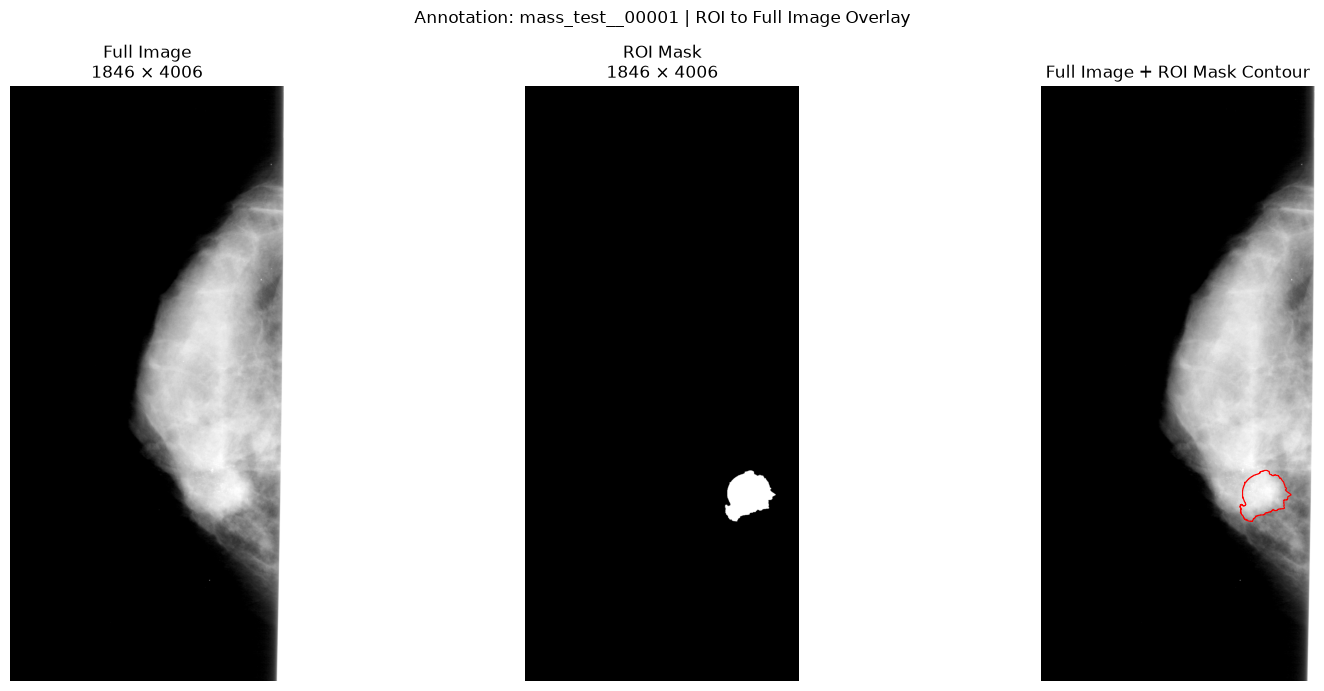

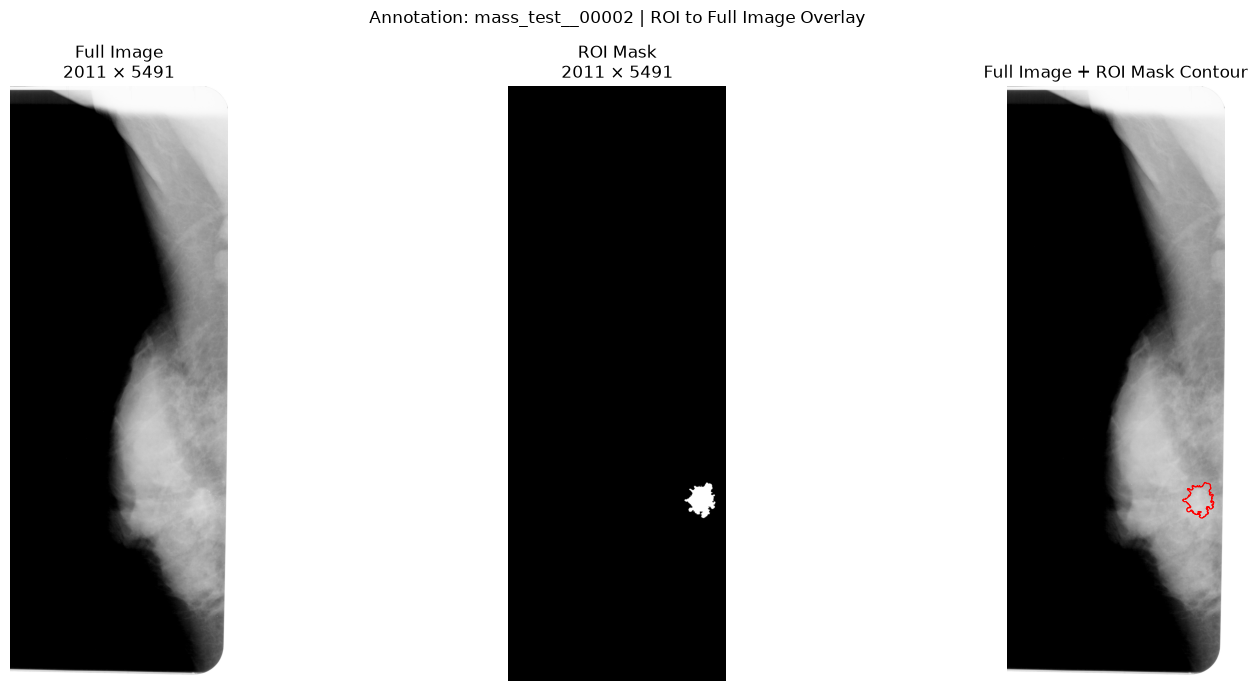

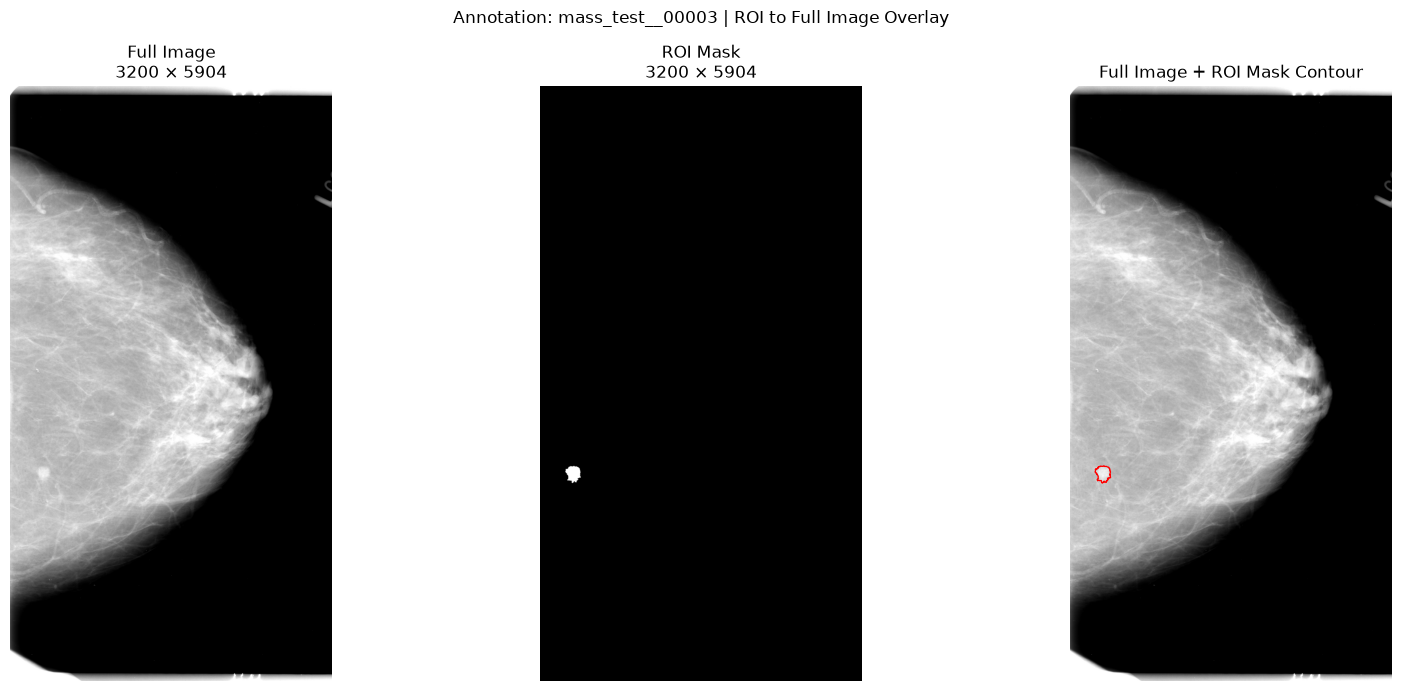

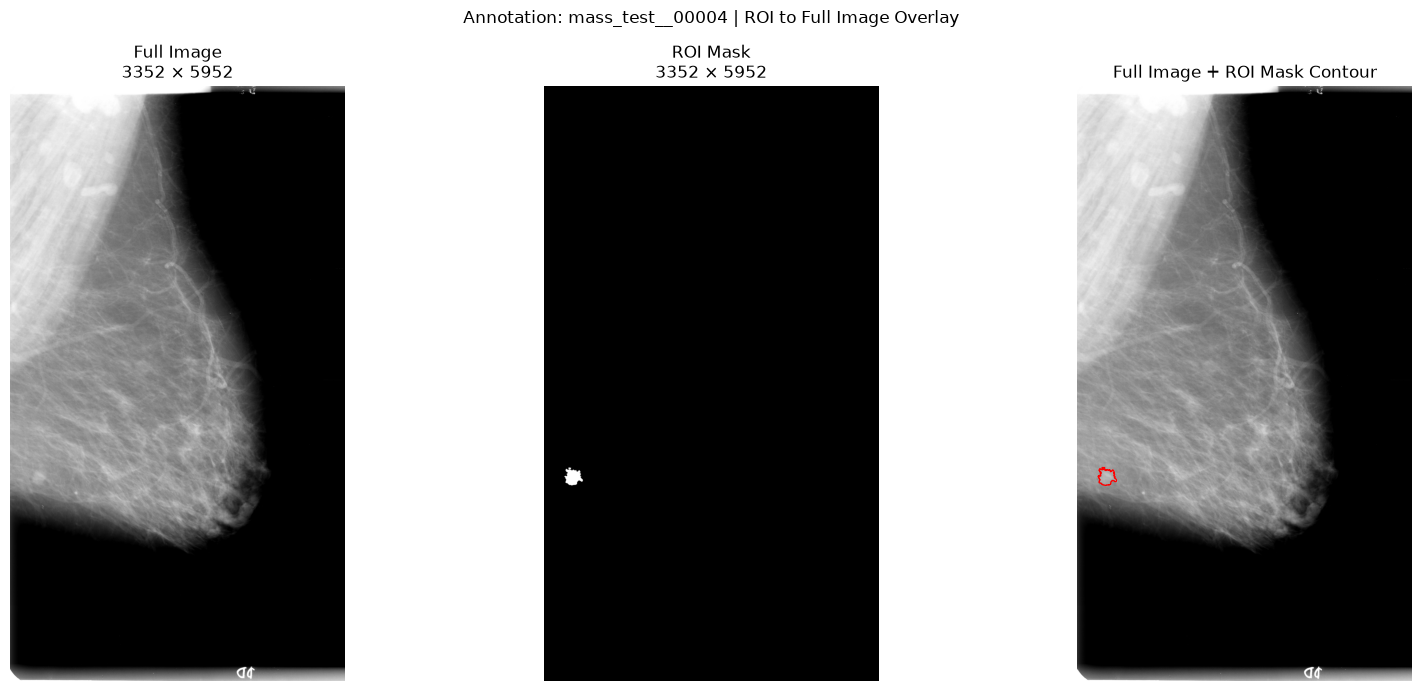

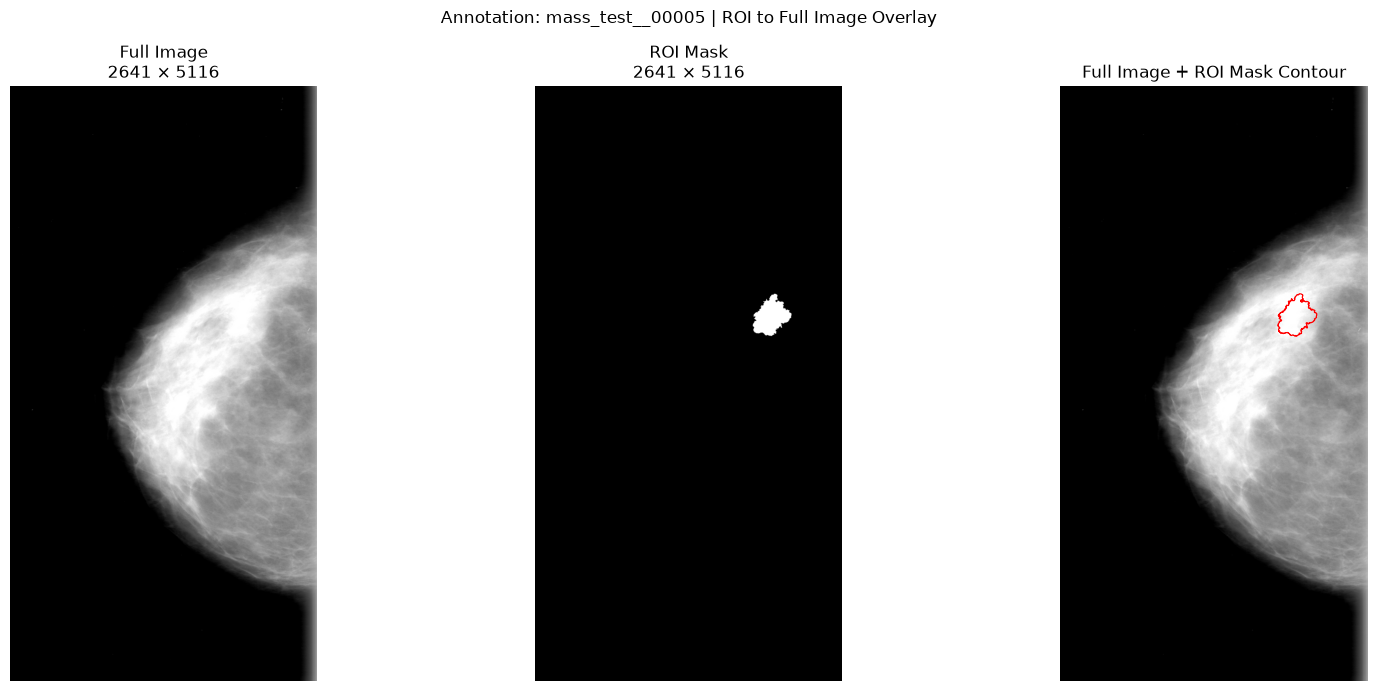

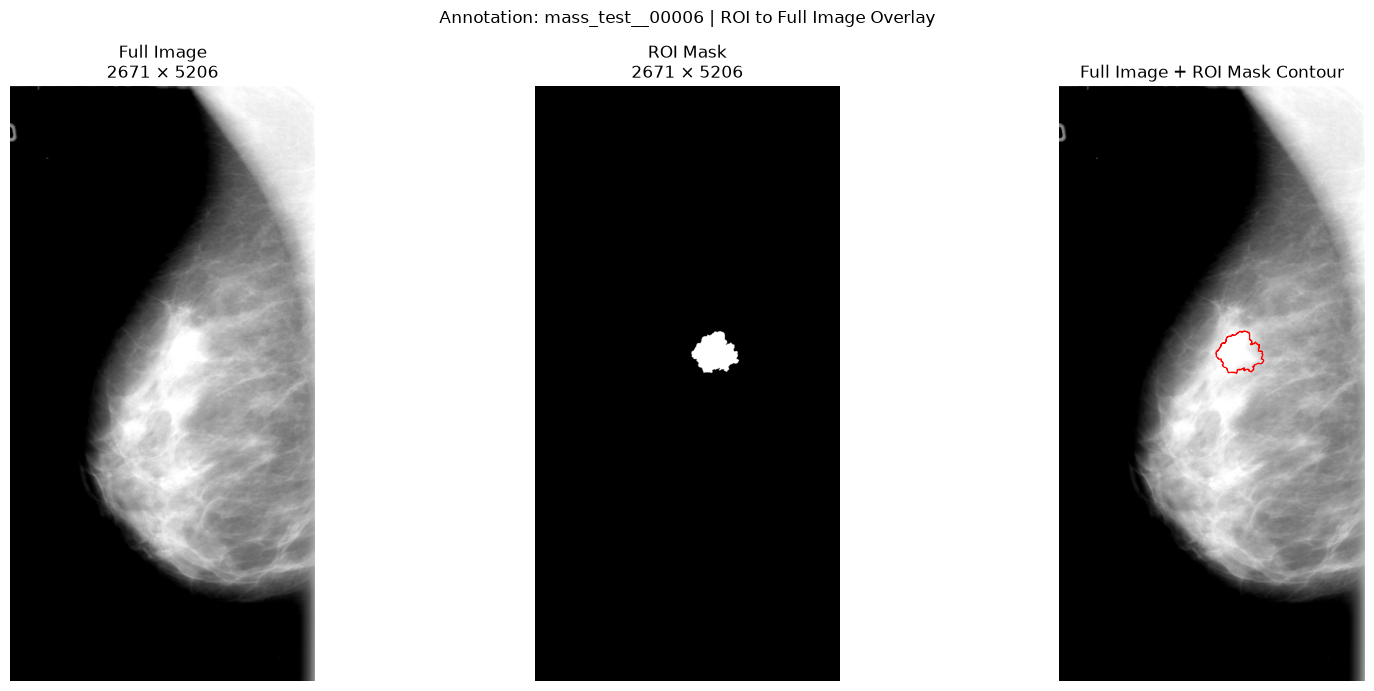

=== OVERLAY REVIEW RECORDS ===


,annotation_id,full_image_shape,roi_mask_shape,shape_match,foreground_pixels,overlay_review_status
0,mass_test__00001,"(4006, 1846)","(4006, 1846)",True,74597,pending_visual_review
1,mass_test__00002,"(5491, 2011)","(5491, 2011)",True,54023,pending_visual_review
2,mass_test__00003,"(5904, 3200)","(5904, 3200)",True,18046,pending_visual_review
3,mass_test__00004,"(5952, 3352)","(5952, 3352)",True,20833,pending_visual_review
4,mass_test__00005,"(5116, 2641)","(5116, 2641)",True,71313,pending_visual_review
5,mass_test__00006,"(5206, 2671)","(5206, 2671)",True,98578,pending_visual_review


In [28]:
# 05.7.5 — OVERLAY ROI MASK LÊN FULL IMAGE

def read_display_image(path):

    ds = pydicom.dcmread(str(path))
    arr = ds.pixel_array.astype(np.float32)

    if arr.ndim != 2:
        raise ValueError(
            f"Full Image không phải ảnh 2D: {arr.shape}"
        )

    low, high = np.percentile(arr, [1, 99])

    if high <= low:
        high = low + 1

    display_arr = np.clip(
        (arr - low) / (high - low),
        0,
        1
    )

    if str(
        getattr(ds, "PhotometricInterpretation", "")
    ) == "MONOCHROME1":
        display_arr = 1 - display_arr

    return display_arr


overlay_candidates_df = roi_full_spatial_audit_df[
    roi_full_spatial_audit_df[
        "direct_coordinate_candidate"
    ]
].copy()

overlay_candidates_df = overlay_candidates_df.head(6)

overlay_review_records = []

for _, audit_row in overlay_candidates_df.iterrows():

    annotation_id = audit_row["annotation_id"]

    mapping_row = spatial_mapping_df[
        spatial_mapping_df["annotation_id"].eq(annotation_id)
    ].iloc[0]

    full_path = mapping_row["full_image_file_path"]
    mask_path = mapping_row["roi_mask_file_path"]

    full_arr = read_display_image(full_path)
    mask_arr = read_mask_array(mask_path)

    if full_arr.shape != mask_arr.shape:
        continue

    foreground = mask_arr > 0

    fig, axes = plt.subplots(
        1, 3,
        figsize=(17, 7)
    )

    axes[0].imshow(
        full_arr,
        cmap="gray"
    )
    axes[0].set_title(
        f"Full Image\n{full_arr.shape[1]} × {full_arr.shape[0]}"
    )

    axes[1].imshow(
        foreground,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1].set_title(
        f"ROI Mask\n{mask_arr.shape[1]} × {mask_arr.shape[0]}"
    )

    axes[2].imshow(
        full_arr,
        cmap="gray"
    )

    if foreground.any():
        axes[2].contour(
            foreground,
            levels=[0.5],
            colors="red",
            linewidths=0.8
        )

    axes[2].set_title(
        "Full Image + ROI Mask Contour"
    )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"Annotation: {annotation_id} | ROI to Full Image Overlay",
        fontsize=12
    )

    plt.tight_layout()
    plt.show()
    plt.close(fig)

    overlay_review_records.append({
        "annotation_id": annotation_id,
        "full_image_shape": str(full_arr.shape),
        "roi_mask_shape": str(mask_arr.shape),
        "shape_match": full_arr.shape == mask_arr.shape,
        "foreground_pixels": int(foreground.sum()),
        "overlay_review_status": "pending_visual_review",
    })

overlay_review_df = pd.DataFrame(
    overlay_review_records
)

print("=== OVERLAY REVIEW RECORDS ===")
display(overlay_review_df)

In [29]:
# 05.7.6 — TỔNG HỢP VÀ XUẤT KẾT QUẢ

roi_full_spatial_result_df = (
    spatial_mapping_df
    .merge(
        roi_full_spatial_audit_df,
        on="annotation_id",
        how="left"
    )
)

roi_full_spatial_result_df = (
    roi_full_spatial_result_df
    .merge(
        roi_bbox_candidate_df[
            [
                "annotation_id",
                "bbox_coordinate_source",
                "bbox_full_image_status",
            ]
        ],
        on="annotation_id",
        how="left"
    )
)

assert len(roi_full_spatial_result_df) == len(
    mass_annotation_ids
)

assert roi_full_spatial_result_df[
    "annotation_id"
].nunique() == len(mass_annotation_ids)

roi_full_spatial_summary_df = pd.DataFrame([
    {
        "criterion": "Total Mass annotations",
        "count": len(roi_full_spatial_result_df),
    },
    {
        "criterion": "Full Image file available",
        "count": int(
            roi_full_spatial_result_df[
                "full_image_path_status"
            ].eq("unique_file").sum()
        ),
    },
    {
        "criterion": "ROI Mask file available",
        "count": int(
            roi_full_spatial_result_df[
                "roi_mask_path_status"
            ].eq("unique_file").sum()
        ),
    },
    {
        "criterion": "Full Image and ROI Mask same dimensions",
        "count": int(
            roi_full_spatial_result_df["shape_match"]
            .fillna(False).sum()
        ),
    },
    {
        "criterion": "ROI Mask has foreground",
        "count": int(
            roi_full_spatial_result_df[
                "mask_foreground_pixels"
            ].fillna(0).gt(0).sum()
        ),
    },
    {
        "criterion": "Direct coordinate candidates",
        "count": int(
            roi_full_spatial_result_df[
                "direct_coordinate_candidate"
            ].fillna(False).sum()
        ),
    },
])

print("=== ROI MASK TO FULL IMAGE SUMMARY ===")
display(roi_full_spatial_summary_df)

print("\n=== FINAL STATUS DISTRIBUTION ===")
display(
    roi_full_spatial_result_df[
        "bbox_full_image_status"
    ]
    .value_counts(dropna=False)
    .rename_axis("status")
    .to_frame("annotation_count")
)

NB05_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

roi_full_spatial_result_df.to_csv(
    NB05_OUTPUT_DIR / "nb05_7_roi_full_spatial_audit.csv",
    index=False,
    encoding="utf-8-sig"
)

roi_bbox_candidate_df.to_csv(
    NB05_OUTPUT_DIR / "nb05_7_roi_bbox_candidates.csv",
    index=False,
    encoding="utf-8-sig"
)

roi_full_spatial_summary_df.to_csv(
    NB05_OUTPUT_DIR / "nb05_7_roi_full_spatial_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

overlay_review_df.to_csv(
    NB05_OUTPUT_DIR / "nb05_7_overlay_review.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n[OK] Đã xuất kết quả Notebook 05.7 tại:")
print(NB05_OUTPUT_DIR)

=== ROI MASK TO FULL IMAGE SUMMARY ===


,criterion,count
0,Total Mass annotations,1696
1,Full Image file available,1696
2,ROI Mask file available,1696
3,Full Image and ROI Mask same dimensions,1618
4,ROI Mask has foreground,1696
5,Direct coordinate candidates,1618



=== FINAL STATUS DISTRIBUTION ===


,annotation_count
status,
candidate_requires_overlay_validation,1618
not_verified,78



[OK] Đã xuất kết quả Notebook 05.7 tại:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset


Tổng số Mass annotation: 1696
Số trường hợp khác kích thước: 78

10 annotation được chọn:


,annotation_id,shape_match
0,mass_train__00500,False
1,mass_test__00025,False
2,mass_train__00536,False
3,mass_test__00322,False
4,mass_test__00309,False
5,mass_train__01318,False
6,mass_train__00484,False
7,mass_test__00087,False
8,mass_train__00827,False
9,mass_train__01275,False



KẾT QUẢ ĐỌC ẢNH
Số cặp ảnh đọc thành công: 10


,annotation_id,full_image_shape,roi_mask_shape,foreground_pixels,full_rows,full_columns,roi_rows,roi_columns,full_pixel_spacing,roi_pixel_spacing,...,full_image_orientation,roi_image_orientation,full_frame_uid,roi_frame_uid,study_uid_match,series_uid_match,bbox_x_min,bbox_y_min,bbox_x_max,bbox_y_max
0,mass_train__00500,"(5266, 2761)","(4582, 2403)",19336,5266,2761,4582,2403,None,None,...,None,None,None,None,False,False,1996,2236,2165,2413
1,mass_test__00025,"(5041, 2056)","(4386, 1789)",69541,5041,2056,4386,1789,None,None,...,None,None,None,None,False,False,636,2414,965,2757
2,mass_train__00536,"(5326, 2356)","(4634, 2050)",13502,5326,2356,4634,2050,None,None,...,None,None,None,None,False,False,1791,2780,1932,2923
3,mass_test__00322,"(5386, 3091)","(4686, 2690)",76734,5386,3091,4686,2690,None,None,...,None,None,None,None,False,False,1262,3415,1589,3737
4,mass_test__00309,"(5386, 3721)","(4686, 3238)",41385,5386,3721,4686,3238,None,None,...,None,None,None,None,False,False,1159,1565,1425,1788
5,mass_train__01318,"(5341, 3496)","(4647, 3042)",45163,5341,3496,4647,3042,None,None,...,None,None,None,None,False,False,652,3085,963,3315
6,mass_train__00484,"(5221, 3121)","(4543, 2716)",53432,5221,3121,4543,2716,None,None,...,None,None,None,None,False,False,1156,2223,1438,2523
7,mass_test__00087,"(5386, 3661)","(4686, 3186)",23486,5386,3661,4686,3186,None,None,...,None,None,None,None,False,False,2059,2710,2233,2943
8,mass_train__00827,"(5386, 3151)","(4686, 2742)",45250,5386,3151,4686,2742,None,None,...,None,None,None,None,False,False,459,1389,710,1715
9,mass_train__01275,"(5236, 2716)","(4556, 2363)",38346,5236,2716,4556,2363,None,None,...,None,None,None,None,False,False,673,2886,956,3103


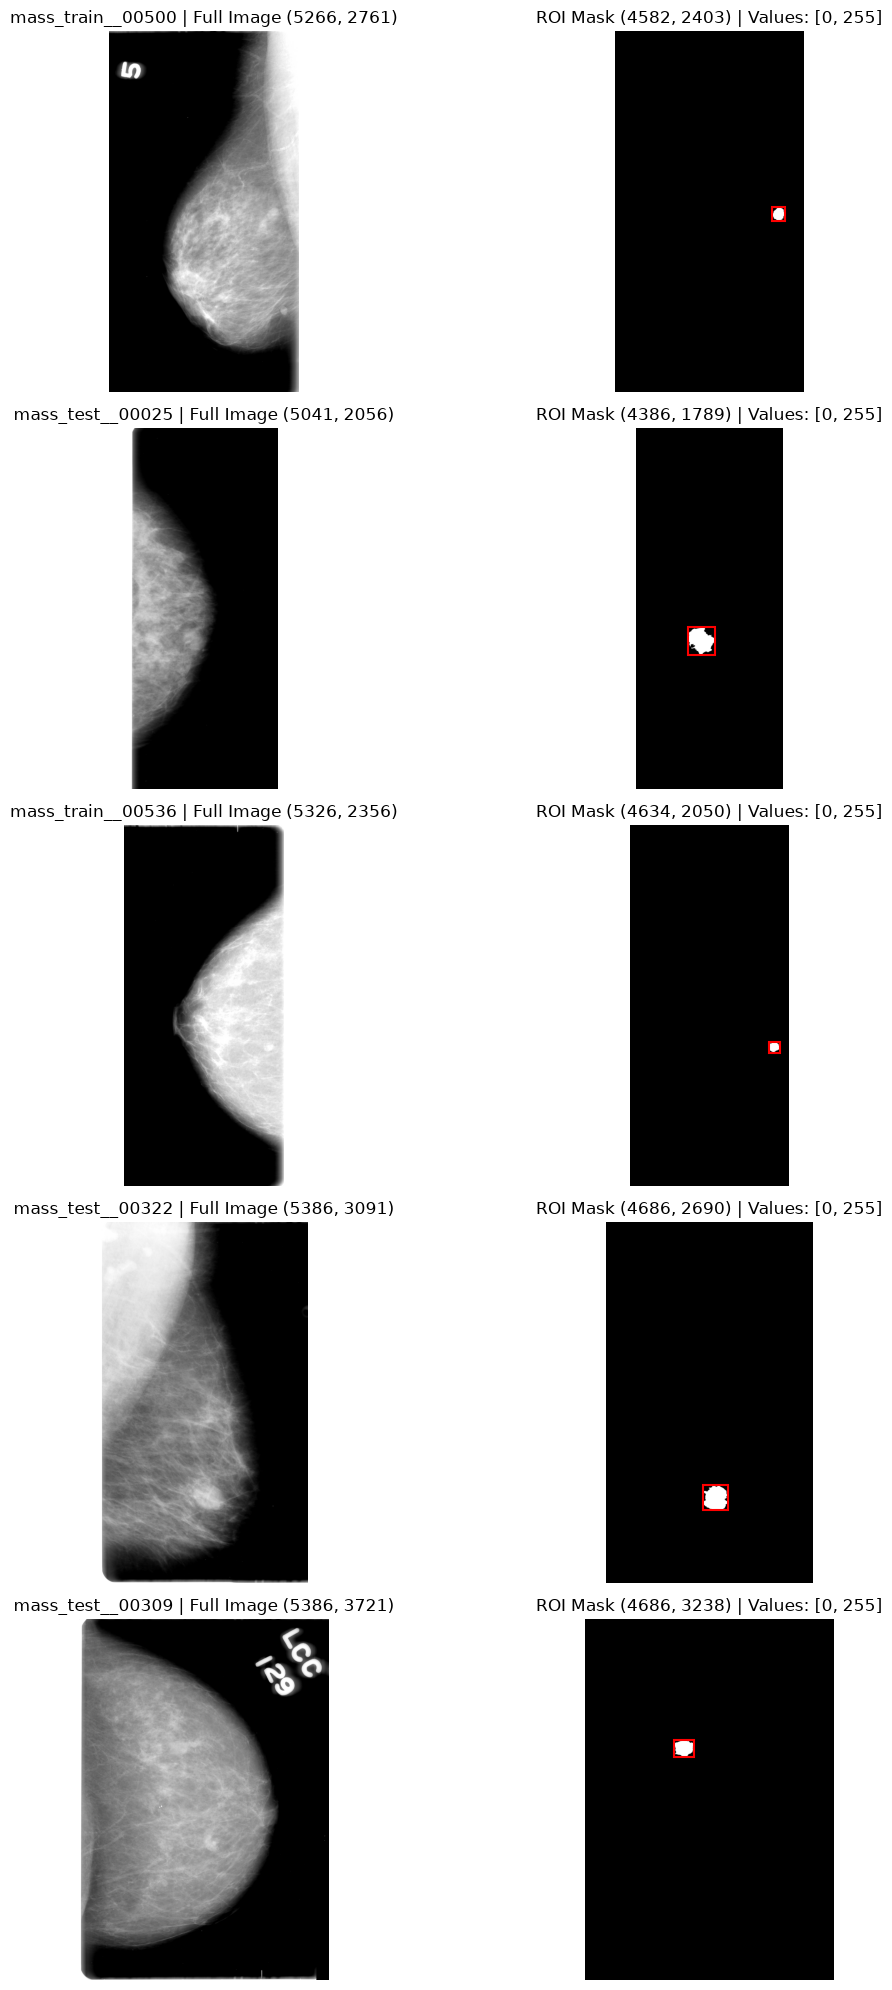

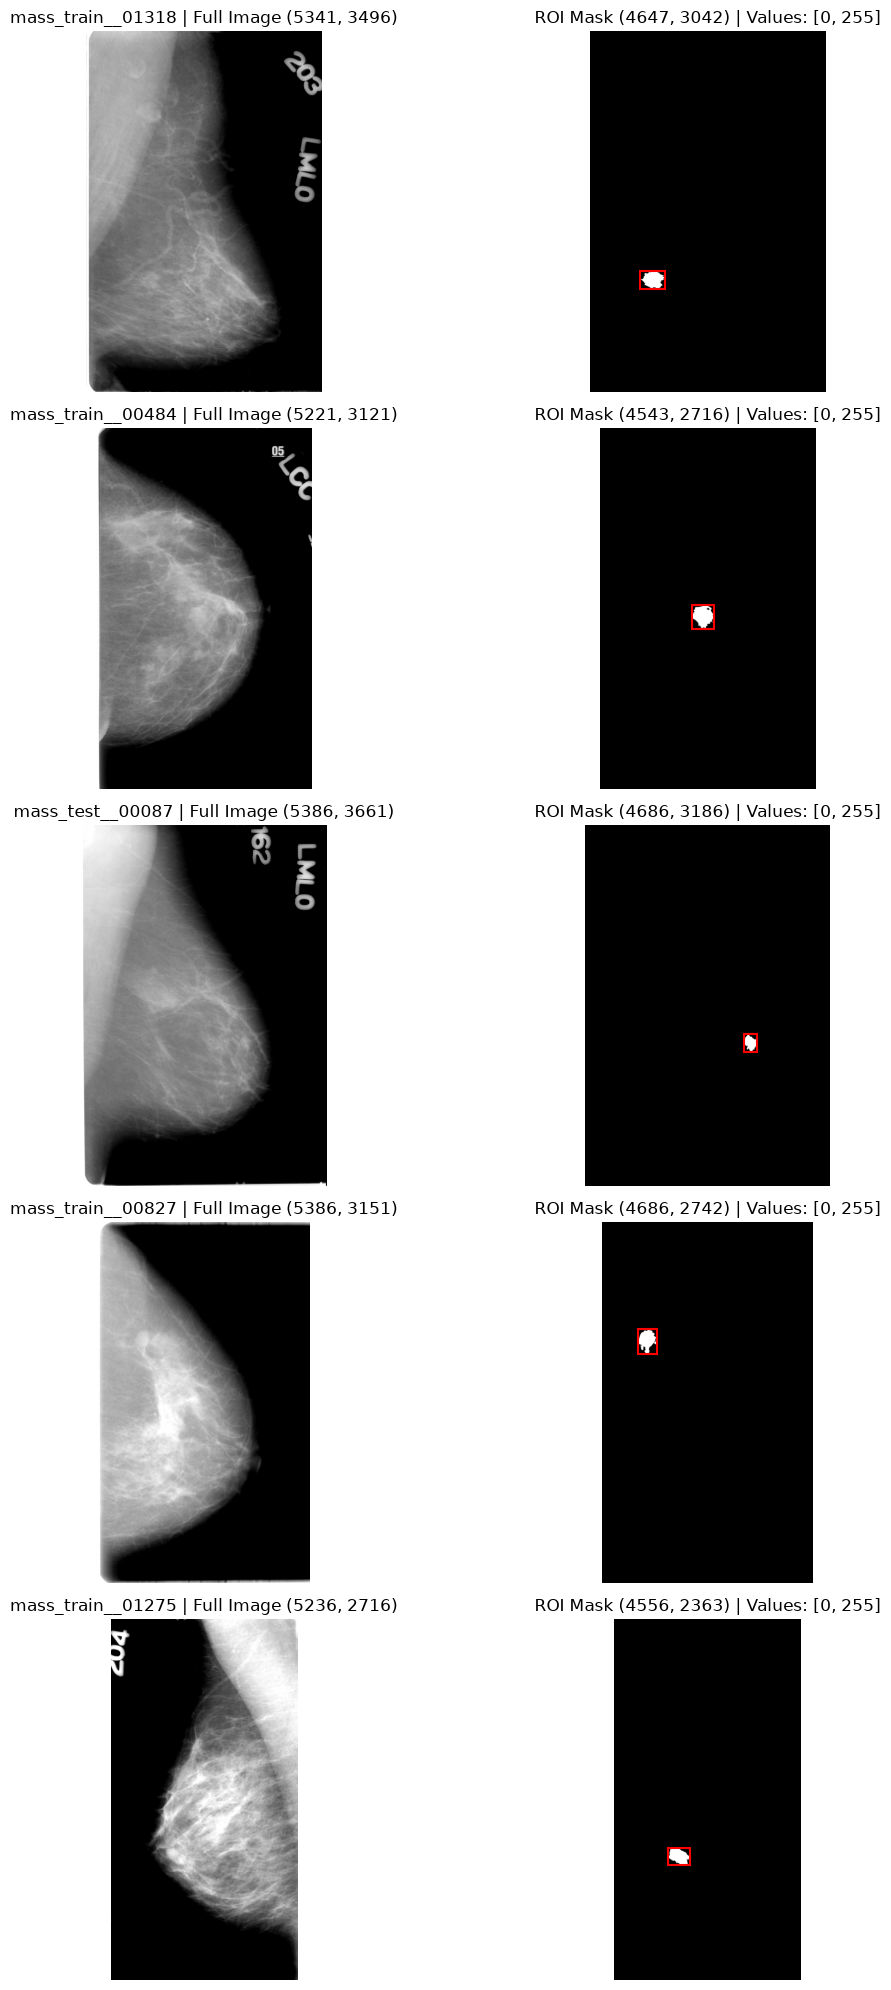


Đã xuất kết quả: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_7_6_mismatch_sample_review.csv


In [31]:
# 05.7.7 — Kiểm tra 10 trường hợp khác kích thước
from pathlib import Path
import pandas as pd
import numpy as np
import pydicom
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
OUTPUT_DIR = PROJECT_ROOT / "Data" / "processed" / "nb05_mass_annotation_dataset"

MAPPING_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "supplementary_image_role_audit_20261105_002929_370953"
)

AUDIT_PATH = OUTPUT_DIR / "nb05_7_roi_full_spatial_audit.csv"
FULL_MAPPING_PATH = MAPPING_DIR / "visual_image_mapping.csv"
ROI_MAPPING_PATH = MAPPING_DIR / "visual_roi_mapping.csv"

# 05.7.6.1 — Kiểm tra và đọc dữ liệu

for path in [AUDIT_PATH, FULL_MAPPING_PATH, ROI_MAPPING_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy file: {path}")

audit_df = pd.read_csv(AUDIT_PATH)
full_mapping_df = pd.read_csv(FULL_MAPPING_PATH)
roi_mapping_df = pd.read_csv(ROI_MAPPING_PATH)

required_audit_cols = {"annotation_id", "shape_match"}
required_full_cols = {"annotation_id", "image_role", "_image_path"}
required_roi_cols = {"annotation_id", "_image_path"}

if not required_audit_cols.issubset(audit_df.columns):
    raise ValueError(
        f"Audit thiếu cột: {required_audit_cols - set(audit_df.columns)}"
    )

if not required_full_cols.issubset(full_mapping_df.columns):
    raise ValueError(
        f"Full mapping thiếu cột: {required_full_cols - set(full_mapping_df.columns)}"
    )

if not required_roi_cols.issubset(roi_mapping_df.columns):
    raise ValueError(
        f"ROI mapping thiếu cột: {required_roi_cols - set(roi_mapping_df.columns)}"
    )

shape_match_value = (
    audit_df["shape_match"]
    .astype(str)
    .str.strip()
    .str.lower()
)

mismatch_df = audit_df.loc[
    shape_match_value.isin(["false", "0", "no"])
].copy()

print("Tổng số Mass annotation:", len(audit_df))
print("Số trường hợp khác kích thước:", len(mismatch_df))

if len(mismatch_df) < 10:
    raise ValueError("Không đủ 10 trường hợp để lấy mẫu kiểm tra.")

# 05.7.6.2 — Chọn ngẫu nhiên 10 annotation

sample_df = (
    mismatch_df
    .sample(n=10, random_state=42)
    .reset_index(drop=True)
)

sample_ids = sample_df["annotation_id"].astype(str).tolist()

print("\n10 annotation được chọn:")
display(
    sample_df[
        [
            col for col in [
                "annotation_id",
                "full_image_shape",
                "roi_mask_shape",
                "shape_match"
            ]
            if col in sample_df.columns
        ]
    ]
)

# 05.7.6.3 — Tra cứu đường dẫn ảnh

full_mapping_df["annotation_id"] = (
    full_mapping_df["annotation_id"].astype(str)
)

roi_mapping_df["annotation_id"] = (
    roi_mapping_df["annotation_id"].astype(str)
)

full_mapping_df["_image_path"] = (
    full_mapping_df["_image_path"].astype(str)
)

roi_mapping_df["_image_path"] = (
    roi_mapping_df["_image_path"].astype(str)
)

full_mapping_df = full_mapping_df[
    full_mapping_df["image_role"].astype(str).str.lower() == "full_image"
]

full_path_lookup = (
    full_mapping_df
    .drop_duplicates("annotation_id")
    .set_index("annotation_id")["_image_path"]
    .to_dict()
)

roi_path_lookup = (
    roi_mapping_df
    .drop_duplicates("annotation_id")
    .set_index("annotation_id")["_image_path"]
    .to_dict()
)

# 05.7.6.4 — Hàm đọc DICOM và metadata

def read_dicom_for_review(file_path):
    file_path = Path(file_path)

    if not file_path.exists():
        raise FileNotFoundError(f"Không tìm thấy DICOM: {file_path}")

    ds = pydicom.dcmread(str(file_path))
    arr = ds.pixel_array

    metadata = {
        "path": str(file_path),
        "shape": arr.shape,
        "rows": getattr(ds, "Rows", None),
        "columns": getattr(ds, "Columns", None),
        "pixel_spacing": getattr(ds, "PixelSpacing", None),
        "image_position": getattr(ds, "ImagePositionPatient", None),
        "image_orientation": getattr(ds, "ImageOrientationPatient", None),
        "frame_of_reference_uid": getattr(ds, "FrameOfReferenceUID", None),
        "study_instance_uid": getattr(ds, "StudyInstanceUID", None),
        "series_instance_uid": getattr(ds, "SeriesInstanceUID", None),
        "sop_instance_uid": getattr(ds, "SOPInstanceUID", None),
        "photometric_interpretation": getattr(ds, "PhotometricInterpretation", None),
        "samples_per_pixel": getattr(ds, "SamplesPerPixel", None),
    }

    return arr, metadata


def normalize_for_display(arr):
    arr = np.asarray(arr).astype(np.float32)

    low, high = np.percentile(arr, [1, 99])

    if high <= low:
        return np.zeros_like(arr)

    return np.clip((arr - low) / (high - low), 0, 1)


# 05.7.6.5 — Đọc 10 cặp ảnh và tổng hợp metadata

review_records = []
review_images = []

for annotation_id in sample_ids:
    full_path = full_path_lookup.get(annotation_id)
    roi_path = roi_path_lookup.get(annotation_id)

    if not full_path or not roi_path:
        print(f"Thiếu đường dẫn: {annotation_id}")
        continue

    full_arr, full_meta = read_dicom_for_review(full_path)
    roi_arr, roi_meta = read_dicom_for_review(roi_path)

    foreground = roi_arr > 0

    if foreground.any():
        y_coords, x_coords = np.where(foreground)

        bbox = {
            "x_min": int(x_coords.min()),
            "y_min": int(y_coords.min()),
            "x_max": int(x_coords.max()),
            "y_max": int(y_coords.max()),
        }
    else:
        bbox = {
            "x_min": None,
            "y_min": None,
            "x_max": None,
            "y_max": None,
        }

    review_records.append({
        "annotation_id": annotation_id,
        "full_image_shape": str(full_arr.shape),
        "roi_mask_shape": str(roi_arr.shape),
        "foreground_pixels": int(foreground.sum()),
        "full_rows": full_meta["rows"],
        "full_columns": full_meta["columns"],
        "roi_rows": roi_meta["rows"],
        "roi_columns": roi_meta["columns"],
        "full_pixel_spacing": str(full_meta["pixel_spacing"]),
        "roi_pixel_spacing": str(roi_meta["pixel_spacing"]),
        "full_image_position": str(full_meta["image_position"]),
        "roi_image_position": str(roi_meta["image_position"]),
        "full_image_orientation": str(full_meta["image_orientation"]),
        "roi_image_orientation": str(roi_meta["image_orientation"]),
        "full_frame_uid": str(full_meta["frame_of_reference_uid"]),
        "roi_frame_uid": str(roi_meta["frame_of_reference_uid"]),
        "study_uid_match": (
            full_meta["study_instance_uid"] == roi_meta["study_instance_uid"]
        ),
        "series_uid_match": (
            full_meta["series_instance_uid"] == roi_meta["series_instance_uid"]
        ),
        "bbox_x_min": bbox["x_min"],
        "bbox_y_min": bbox["y_min"],
        "bbox_x_max": bbox["x_max"],
        "bbox_y_max": bbox["y_max"],
    })

    review_images.append({
        "annotation_id": annotation_id,
        "full_image": normalize_for_display(full_arr),
        "roi_mask": foreground,
        "full_shape": full_arr.shape,
        "roi_shape": roi_arr.shape,
        "bbox": bbox,
        "unique_mask_values": np.unique(roi_arr)[:10].tolist(),
    })

review_df = pd.DataFrame(review_records)

print("\nKẾT QUẢ ĐỌC ẢNH")
print("Số cặp ảnh đọc thành công:", len(review_df))
display(review_df)

# 05.7.6.6 — Hiển thị Full Image và ROI Mask cạnh nhau

for start in range(0, len(review_images), 5):
    batch = review_images[start:start + 5]

    fig, axes = plt.subplots(
        len(batch), 2,
        figsize=(13, 4 * len(batch))
    )

    if len(batch) == 1:
        axes = np.array([axes])

    for row, item in enumerate(batch):
        ax_full = axes[row, 0]
        ax_mask = axes[row, 1]

        ax_full.imshow(item["full_image"], cmap="gray")
        ax_full.set_title(
            f'{item["annotation_id"]} | Full Image {item["full_shape"]}'
        )
        ax_full.axis("off")

        ax_mask.imshow(item["roi_mask"], cmap="gray")

        bbox = item["bbox"]

        if bbox["x_min"] is not None:
            width = bbox["x_max"] - bbox["x_min"] + 1
            height = bbox["y_max"] - bbox["y_min"] + 1

            rect = Rectangle(
                (bbox["x_min"], bbox["y_min"]),
                width,
                height,
                linewidth=1.5,
                edgecolor="red",
                facecolor="none"
            )

            ax_mask.add_patch(rect)

        ax_mask.set_title(
            f'ROI Mask {item["roi_shape"]} | '
            f'Values: {item["unique_mask_values"]}'
        )
        ax_mask.axis("off")

    plt.tight_layout()
    plt.show()

# 05.7.6.7 — Xuất kết quả kiểm tra

review_output = OUTPUT_DIR / "nb05_7_6_mismatch_sample_review.csv"

review_df.to_csv(
    review_output,
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã xuất kết quả:", review_output)


Tổng Mass annotation: 1696
Số trường hợp khác kích thước: 78

20 annotation được chọn:


,annotation_id,full_rows,full_columns,shape_match
0,mass_train__00500,5266,2761,False
1,mass_test__00025,5041,2056,False
2,mass_train__00536,5326,2356,False
3,mass_test__00322,5386,3091,False
4,mass_test__00309,5386,3721,False
5,mass_train__01318,5341,3496,False
6,mass_train__00484,5221,3121,False
7,mass_test__00087,5386,3661,False
8,mass_train__00827,5386,3151,False
9,mass_train__01275,5236,2716,False



Danh sách annotation ID:
01. mass_train__00500
02. mass_test__00025
03. mass_train__00536
04. mass_test__00322
05. mass_test__00309
06. mass_train__01318
07. mass_train__00484
08. mass_test__00087
09. mass_train__00827
10. mass_train__01275
11. mass_train__01197
12. mass_train__00313
13. mass_train__01313
14. mass_train__00953
15. mass_train__00205
16. mass_train__00662
17. mass_train__00485
18. mass_train__01036
19. mass_test__00284
20. mass_test__00161

Số cặp ảnh đọc và xử lý thành công: 20


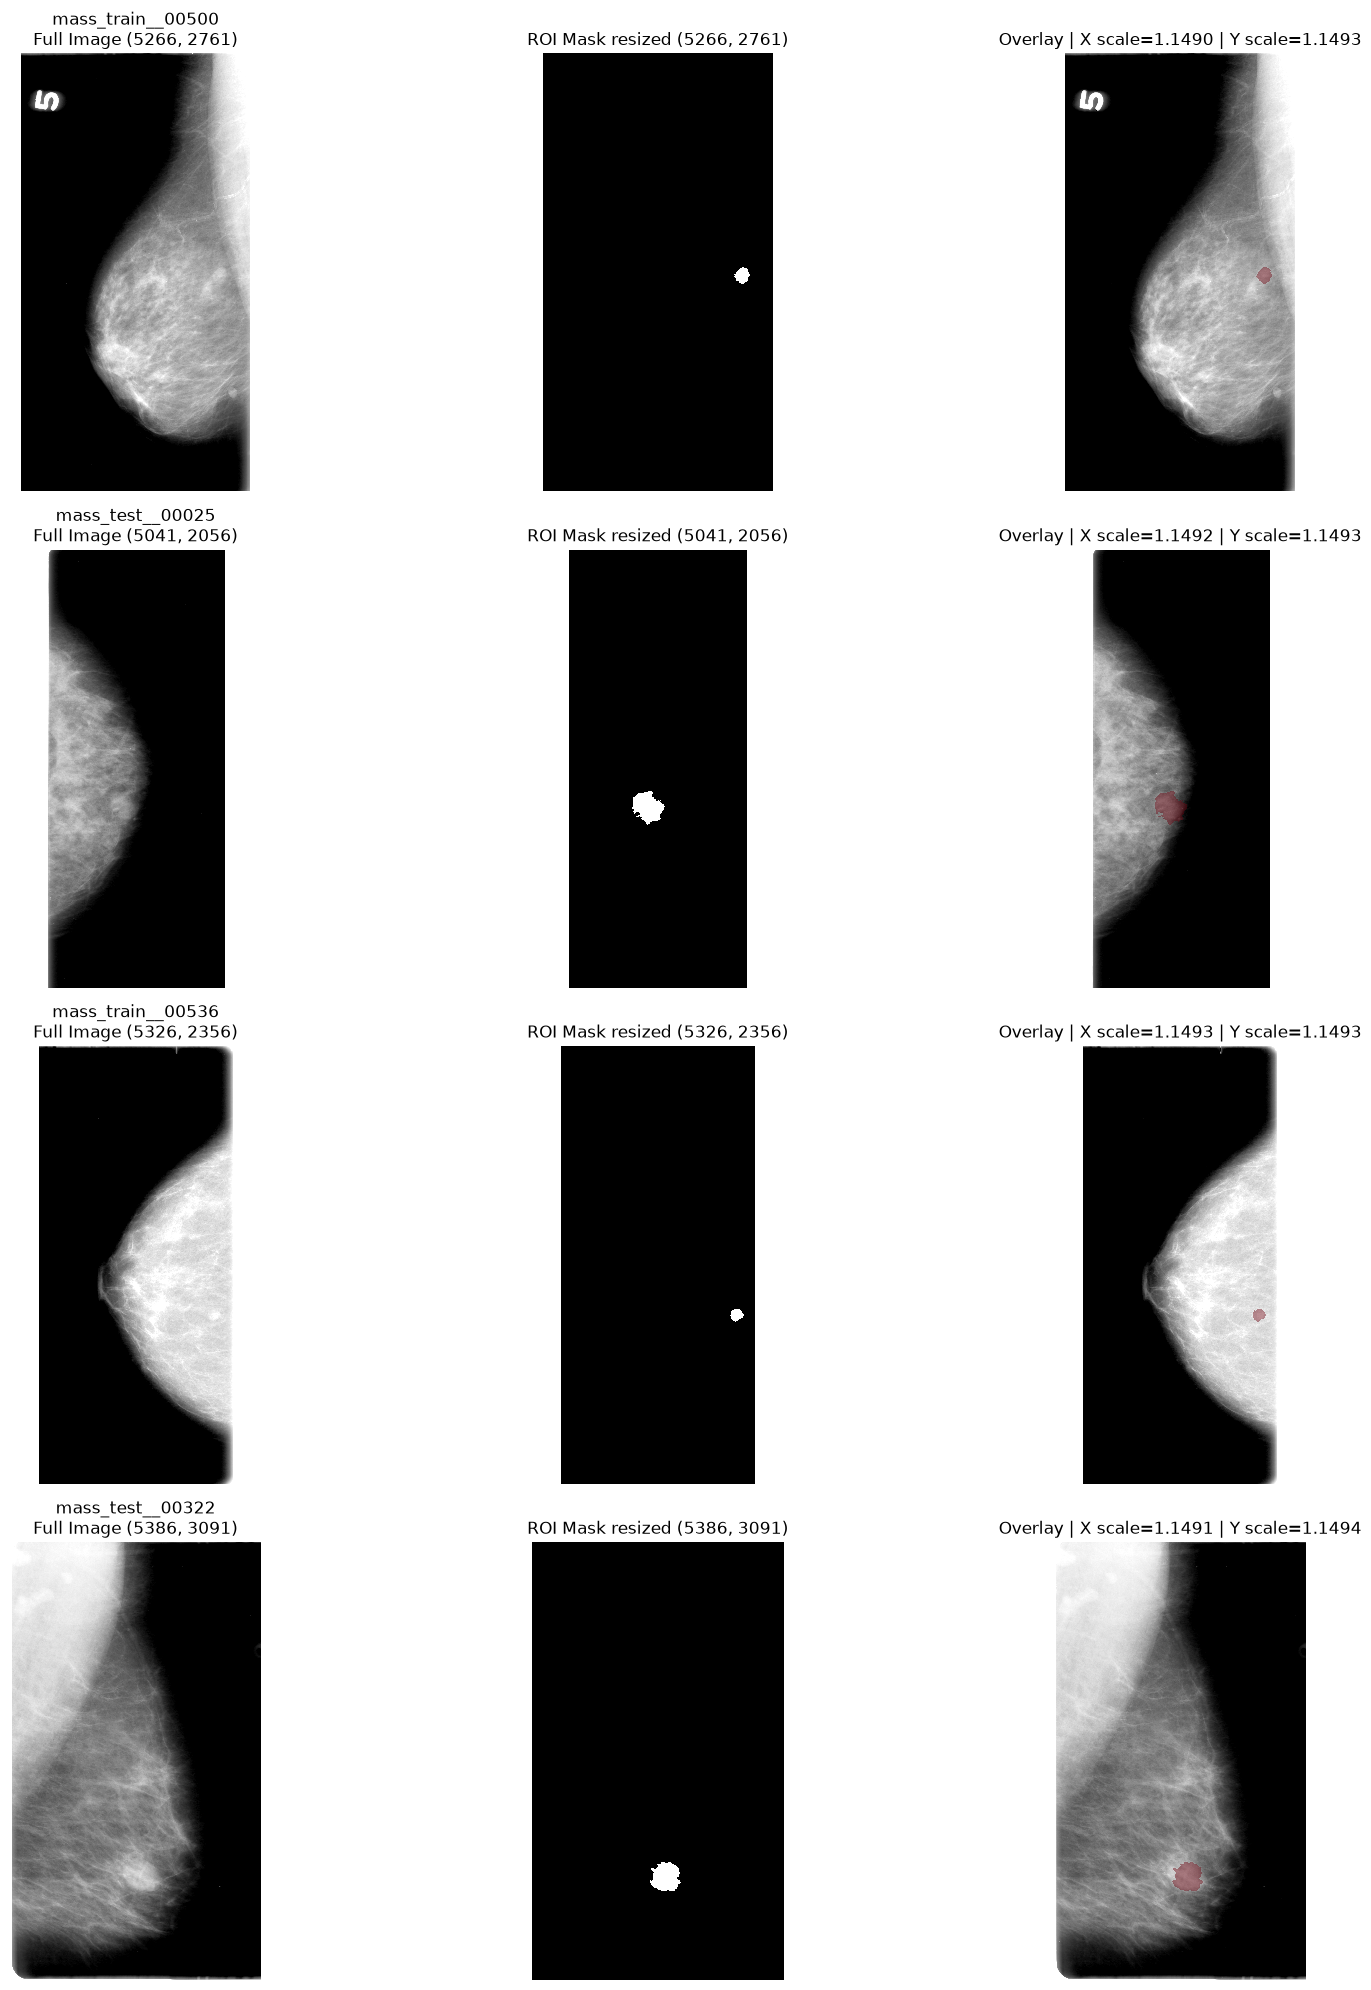

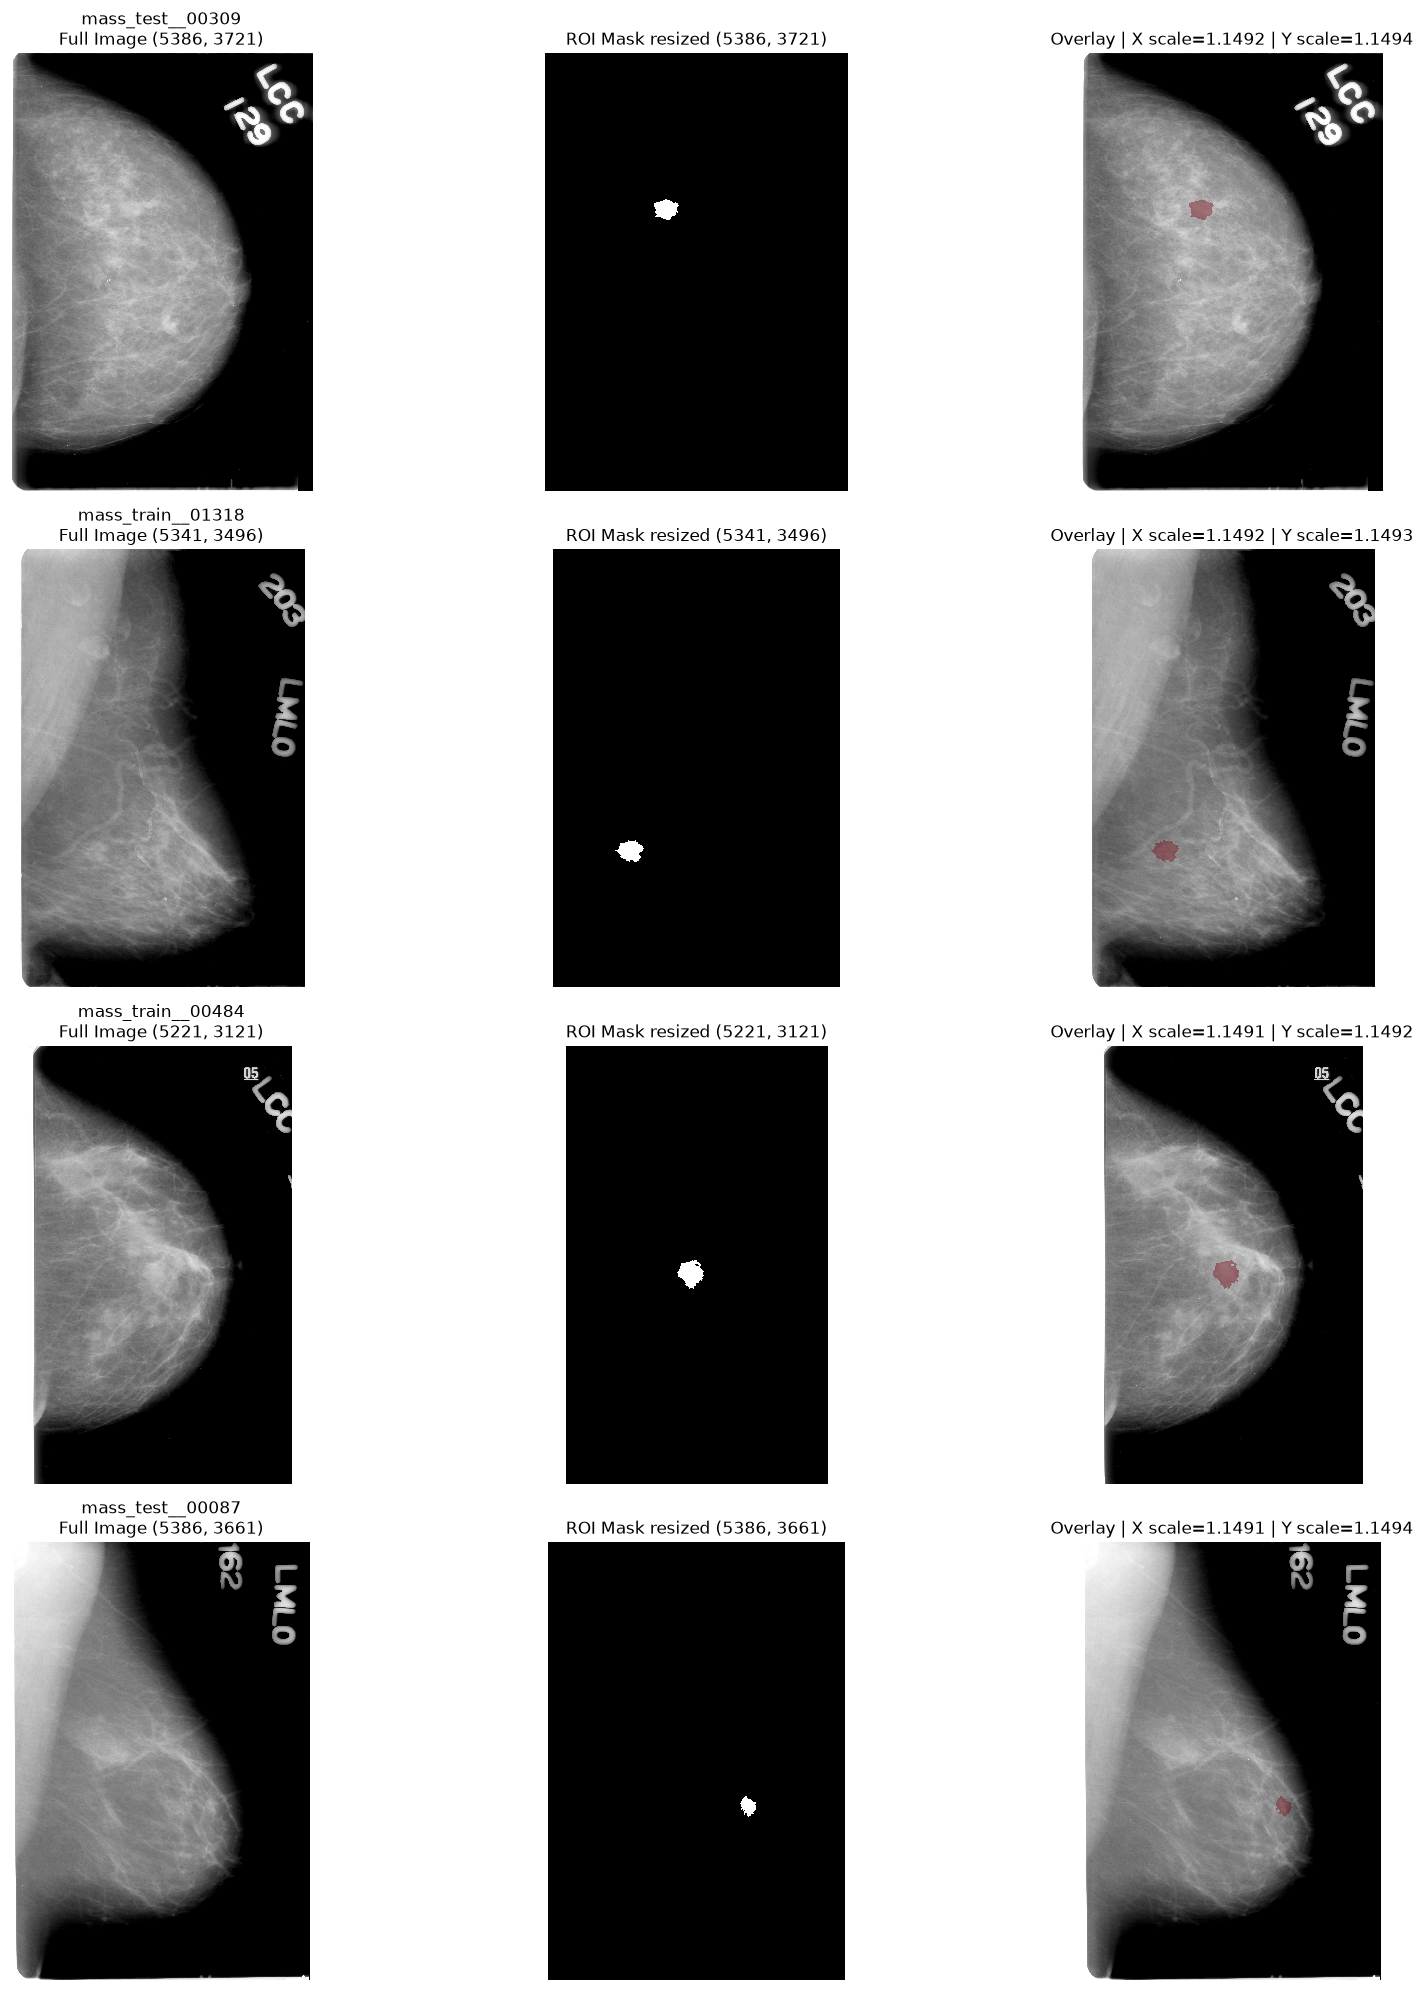

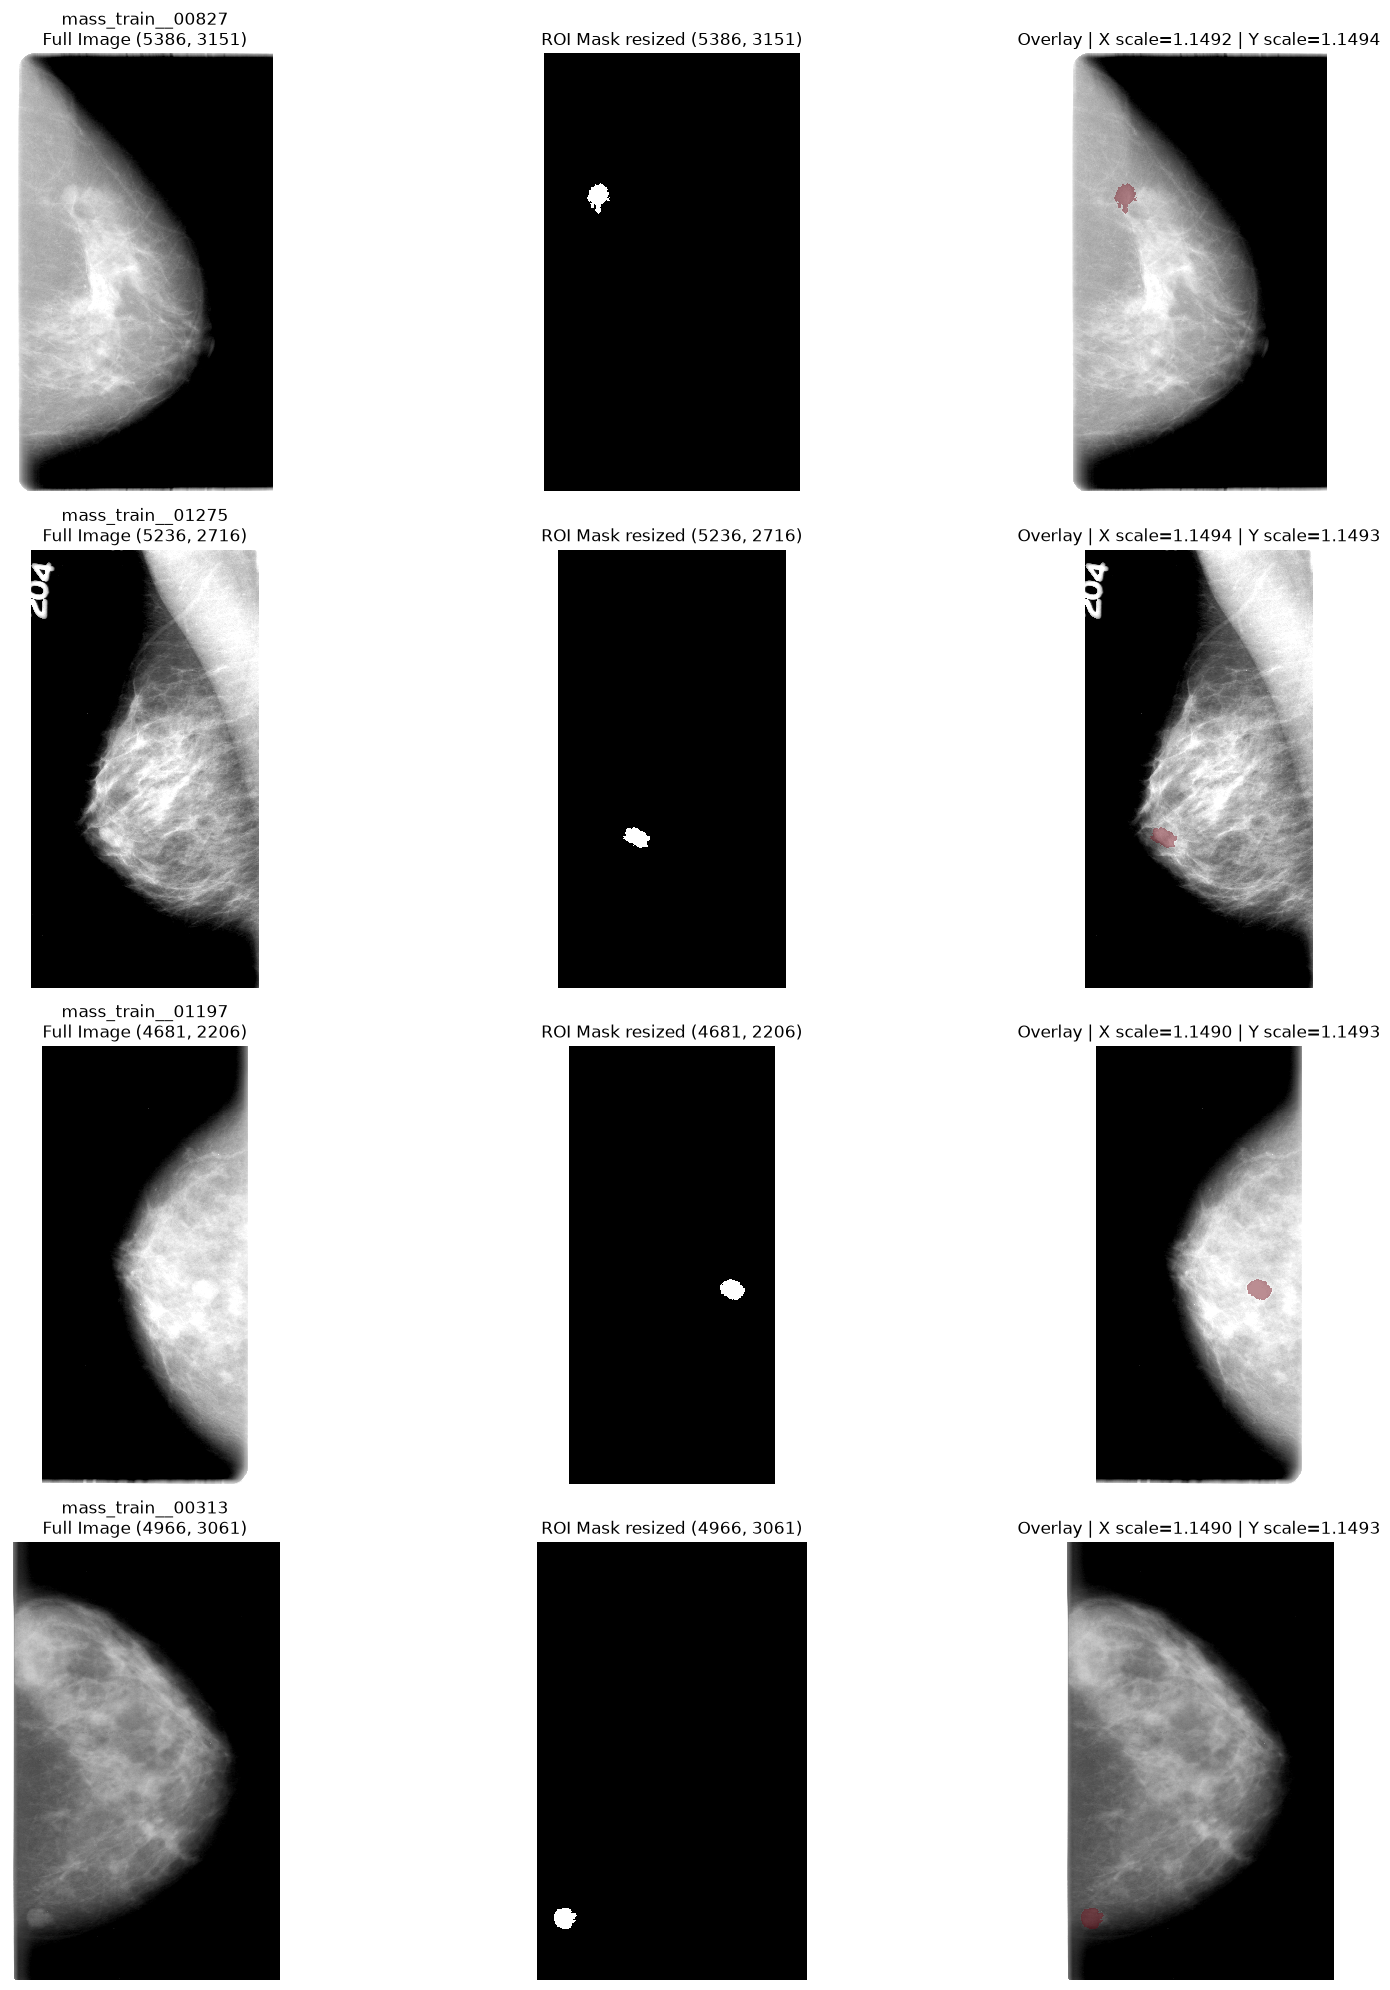

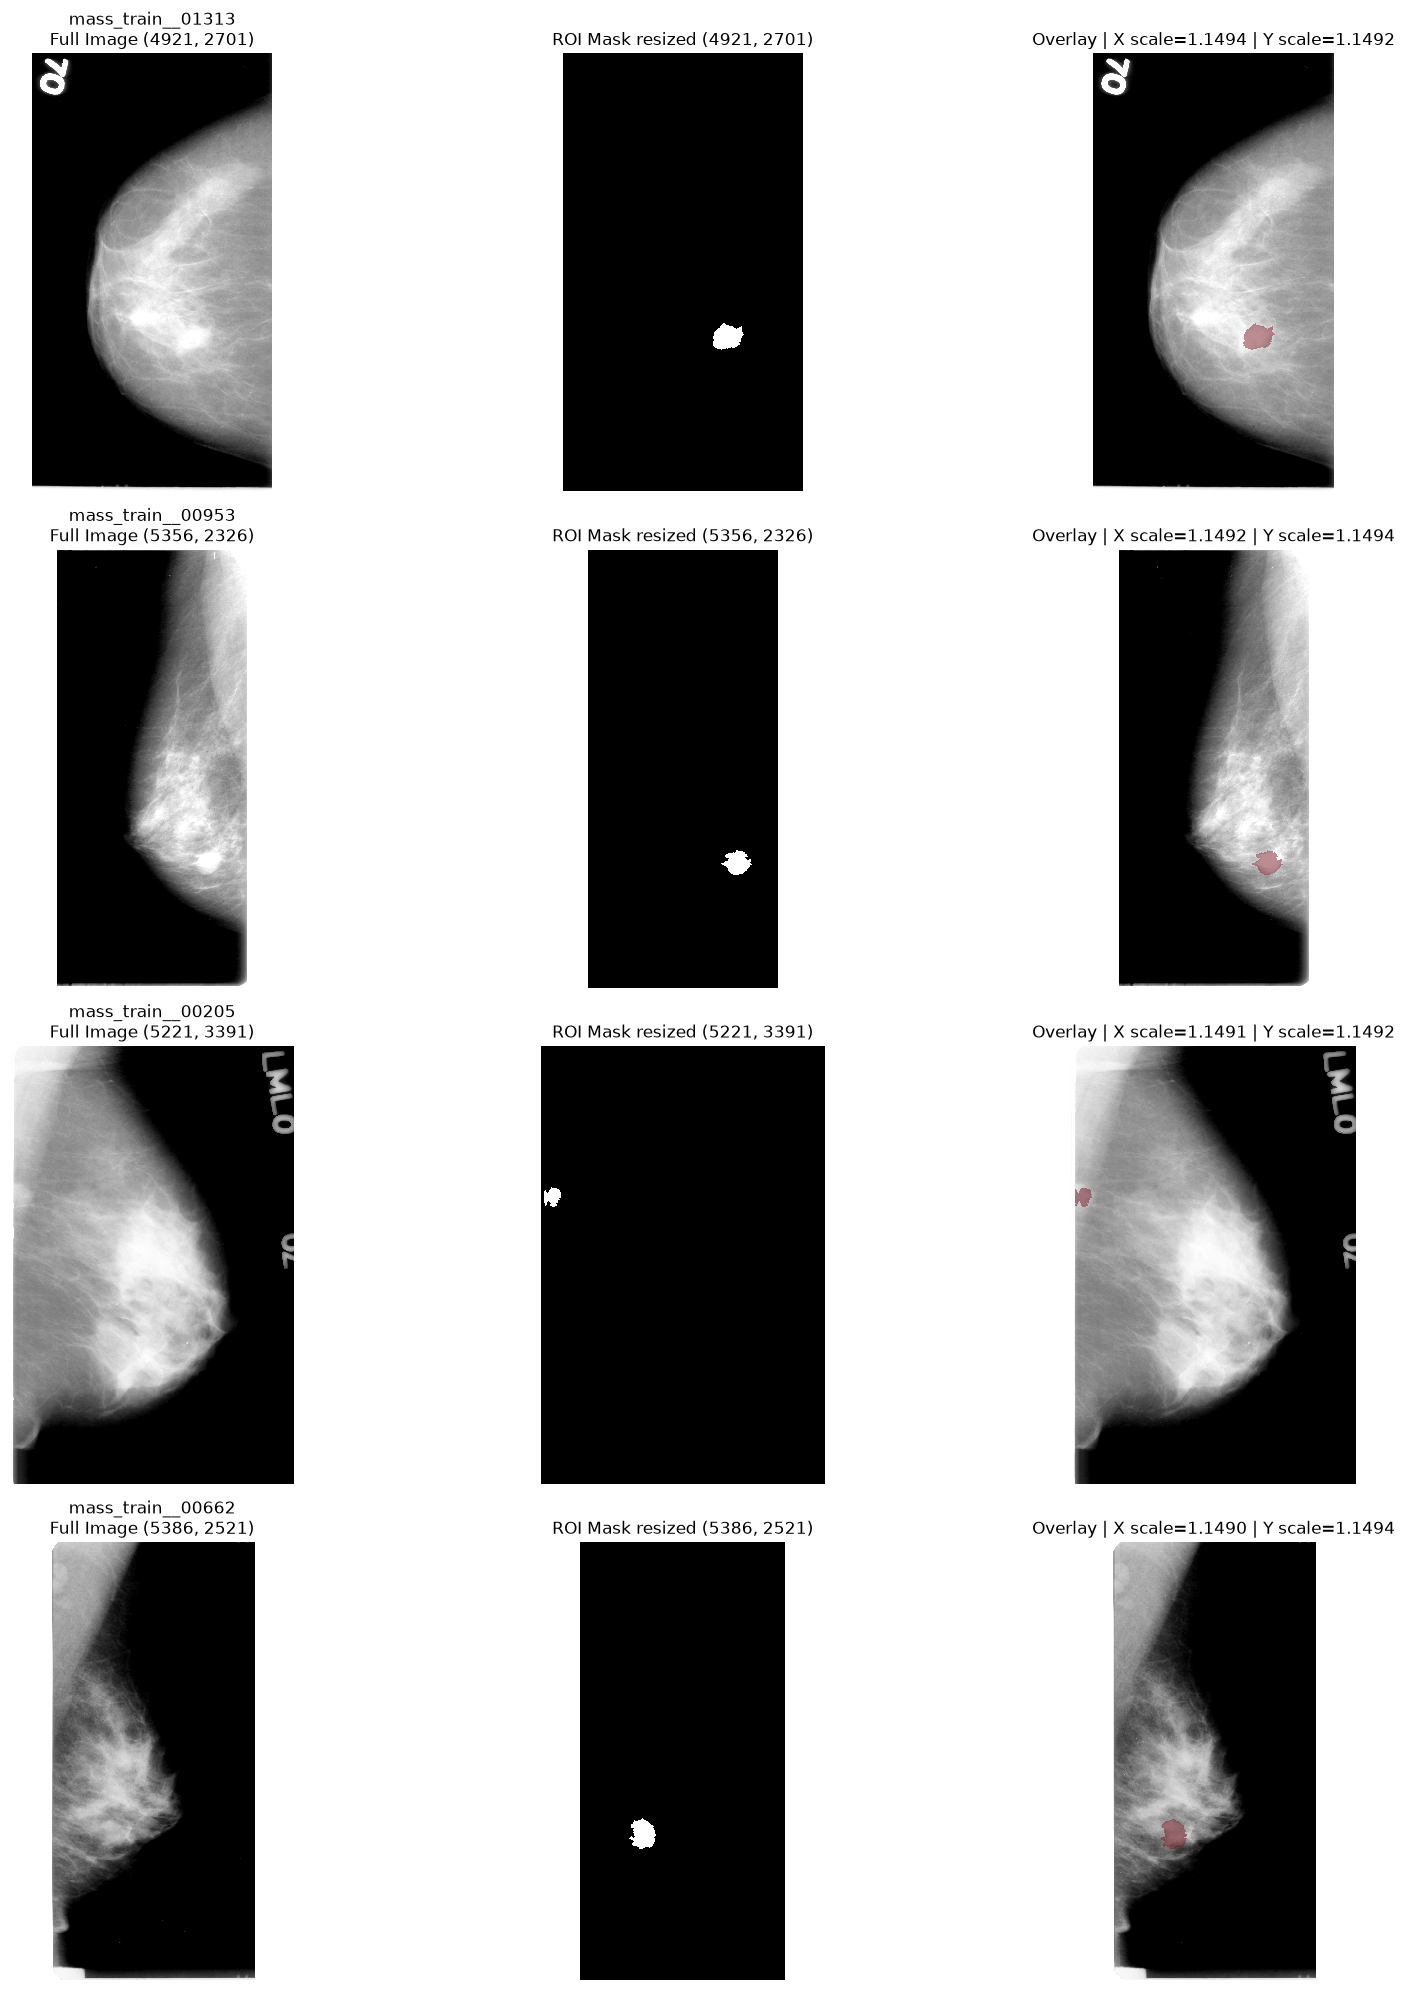

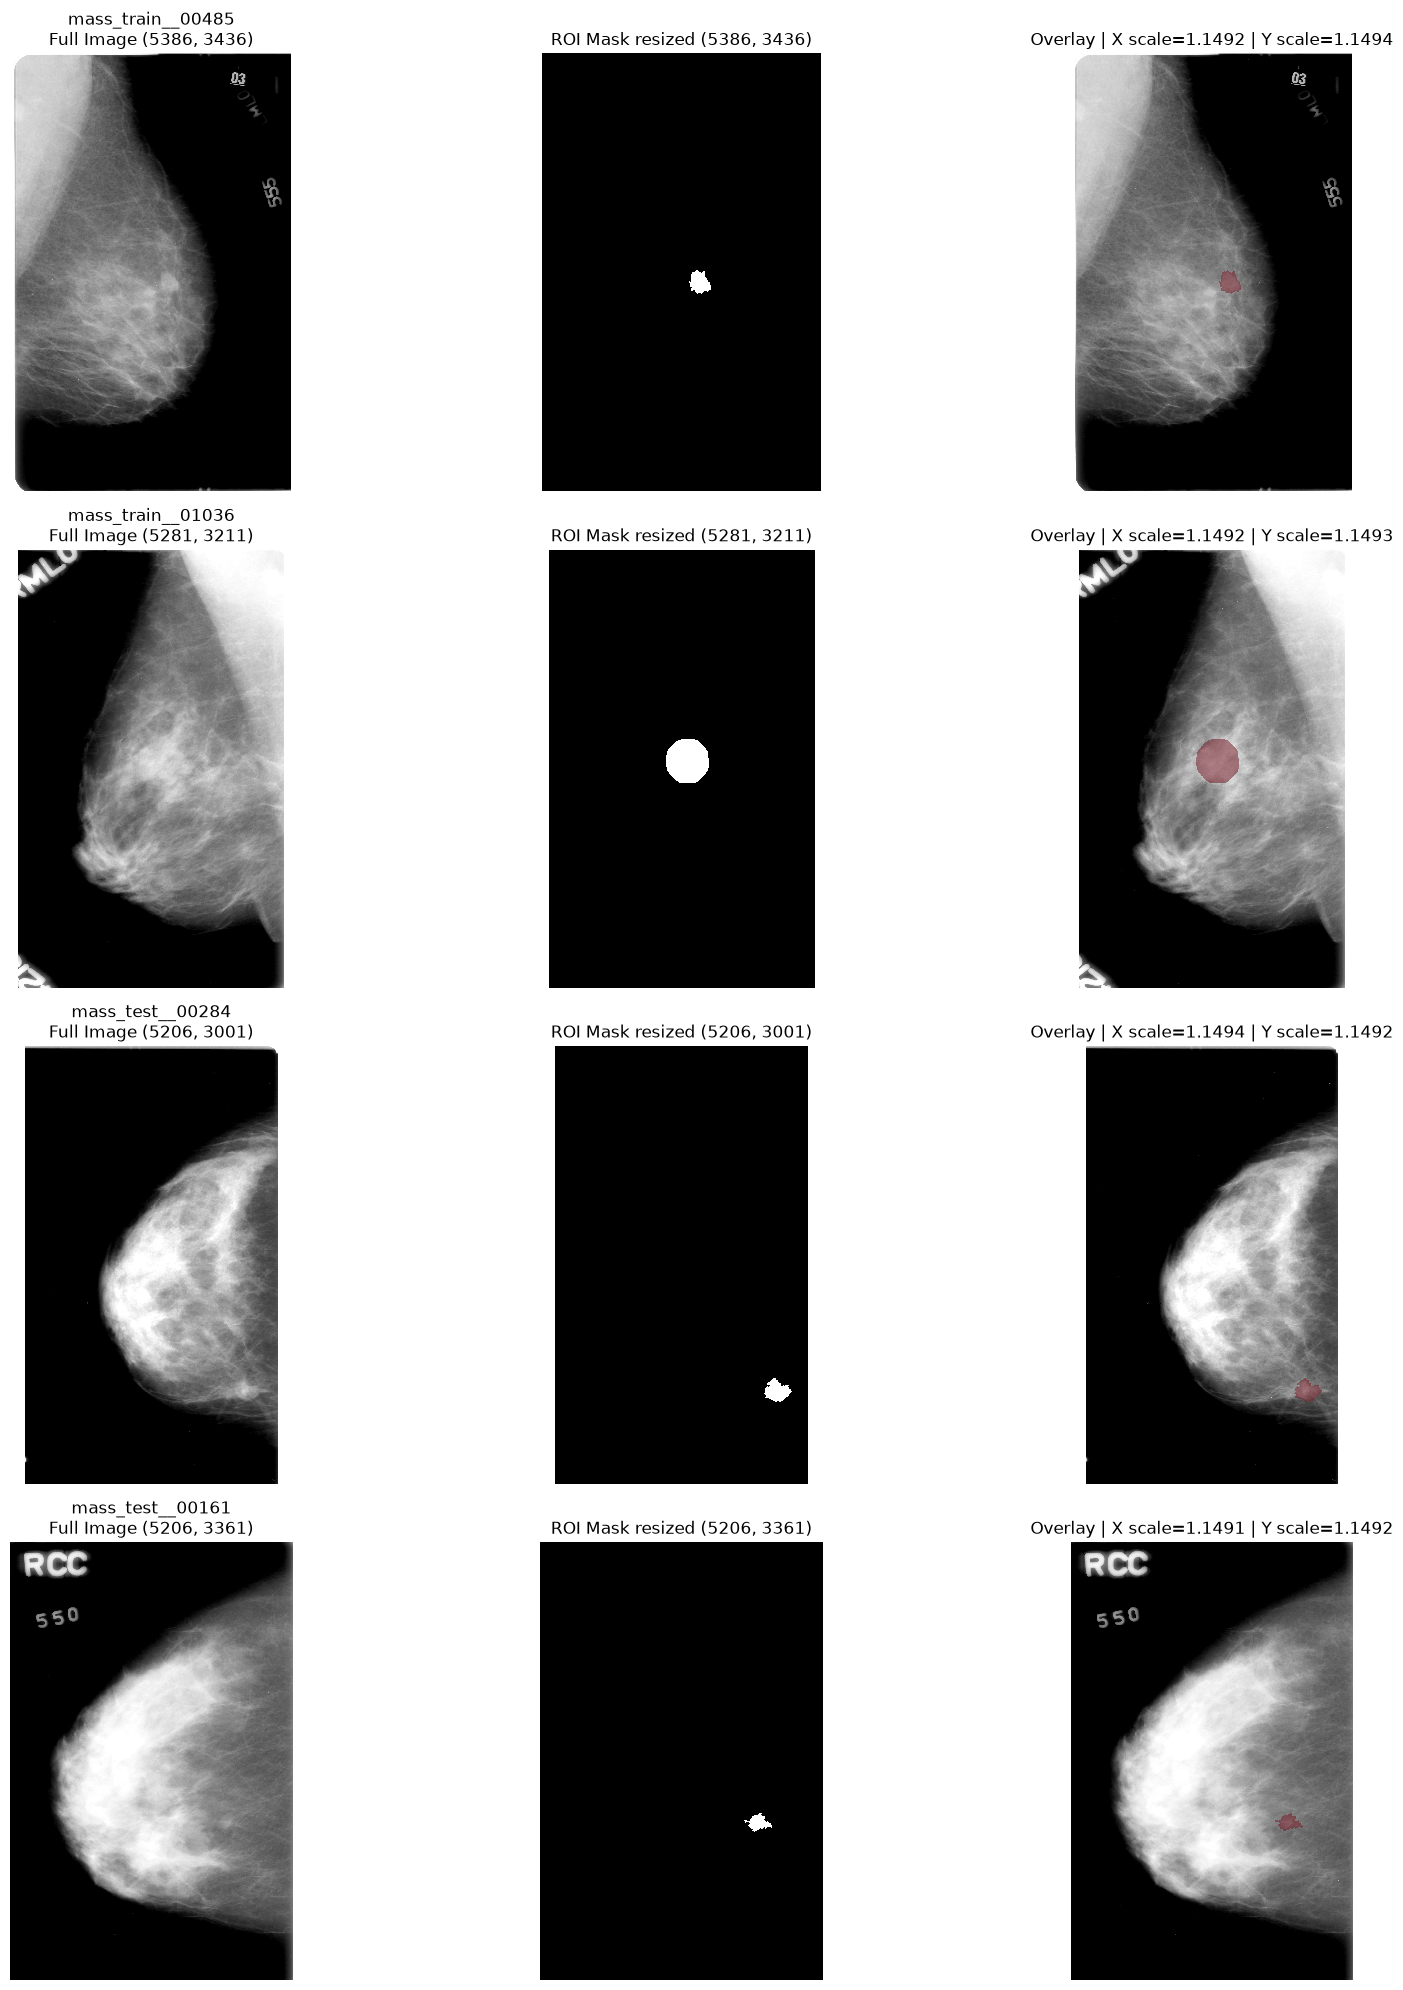


THỐNG KÊ TỶ LỆ RESIZE


,annotation_id,scale_x,scale_y,scale_difference,full_aspect_ratio,roi_aspect_ratio,aspect_ratio_difference,original_mask_foreground,resized_mask_foreground
0,mass_train__00500,1.148980,1.149280,0.000299,0.524307,0.524443,0.000137,19336,25551
1,mass_test__00025,1.149245,1.149339,0.000093,0.407856,0.407889,0.000033,69541,91886
2,mass_train__00536,1.149268,1.149331,0.000063,0.442358,0.442382,0.000024,13502,17846
3,mass_test__00322,1.149071,1.149381,0.000311,0.573895,0.574050,0.000155,76734,101362
4,mass_test__00309,1.149166,1.149381,0.000215,0.690865,0.690994,0.000129,41385,54706
5,mass_train__01318,1.149244,1.149344,0.000100,0.654559,0.654616,0.000057,45163,59660
6,mass_train__00484,1.149116,1.149241,0.000124,0.597778,0.597843,0.000065,53432,70569
7,mass_test__00087,1.149090,1.149381,0.000291,0.679725,0.679898,0.000172,23486,31009
8,mass_train__00827,1.149161,1.149381,0.000220,0.585035,0.585147,0.000112,45250,59780
9,mass_train__01275,1.149386,1.149254,0.000133,0.518717,0.518657,0.000060,38346,50664



THỐNG KÊ SCALE


,scale_x,scale_y,scale_difference
count,20.000000,20.000000,20.000000
mean,1.149163,1.149310,0.000187
std,0.000127,0.000061,0.000090
min,1.148958,1.149227,0.000044
25%,1.149068,1.149250,0.000130
50%,1.149163,1.149312,0.000157
75%,1.149246,1.149381,0.000258
max,1.149386,1.149381,0.000338



Đã xuất kết quả: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_7_7_resize_overlay_review.csv


In [ ]:
# 05.7.8 — Thử nghiệm resize và overlay 20 trường hợp
import pydicom
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from PIL import Image

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
OUTPUT_DIR = PROJECT_ROOT / "Data" / "processed" / "nb05_mass_annotation_dataset"

MAPPING_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "supplementary_image_role_audit_20261105_002929_370953"
)

AUDIT_PATH = OUTPUT_DIR / "nb05_7_roi_full_spatial_audit.csv"
FULL_MAPPING_PATH = MAPPING_DIR / "visual_image_mapping.csv"
ROI_MAPPING_PATH = MAPPING_DIR / "visual_roi_mapping.csv"

# 05.7.7.1 — Đọc dữ liệu và xác định nhóm khác kích thước

audit_df = pd.read_csv(AUDIT_PATH)
full_mapping_df = pd.read_csv(FULL_MAPPING_PATH)
roi_mapping_df = pd.read_csv(ROI_MAPPING_PATH)

shape_match_value = (
    audit_df["shape_match"]
    .astype(str)
    .str.strip()
    .str.lower()
)

mismatch_df = audit_df.loc[
    shape_match_value.isin(["false", "0", "no"])
].copy()

print("Tổng Mass annotation:", len(audit_df))
print("Số trường hợp khác kích thước:", len(mismatch_df))

if len(mismatch_df) < 20:
    raise ValueError("Không đủ 20 trường hợp khác kích thước.")


# 05.7.7.2 — Lấy mẫu ngẫu nhiên 20 trường hợp

sample_df = (
    mismatch_df
    .sample(n=20, random_state=42)
    .reset_index(drop=True)
)

sample_ids = sample_df["annotation_id"].astype(str).tolist()

display_cols = [
    col for col in [
        "annotation_id",
        "full_image_shape",
        "roi_mask_shape",
        "full_rows",
        "full_columns",
        "roi_rows",
        "roi_columns",
        "shape_match"
    ]
    if col in sample_df.columns
]

print("\n20 annotation được chọn:")
display(sample_df[display_cols])

print("\nDanh sách annotation ID:")
for i, annotation_id in enumerate(sample_ids, 1):
    print(f"{i:02d}. {annotation_id}")

# 05.7.7.3 — Tra cứu đường dẫn DICOM

full_mapping_df["annotation_id"] = (
    full_mapping_df["annotation_id"].astype(str)
)

roi_mapping_df["annotation_id"] = (
    roi_mapping_df["annotation_id"].astype(str)
)

full_mapping_df = full_mapping_df[
    full_mapping_df["image_role"].astype(str).str.lower() == "full_image"
]

full_path_lookup = (
    full_mapping_df
    .drop_duplicates("annotation_id")
    .set_index("annotation_id")["_image_path"]
    .to_dict()
)

roi_path_lookup = (
    roi_mapping_df
    .drop_duplicates("annotation_id")
    .set_index("annotation_id")["_image_path"]
    .to_dict()
)

# 05.7.7.4 — Hàm đọc và chuẩn hóa ảnh

def read_dicom_array(file_path):
    file_path = Path(file_path)

    if not file_path.exists():
        raise FileNotFoundError(f"Không tìm thấy file: {file_path}")

    ds = pydicom.dcmread(str(file_path))
    arr = np.asarray(ds.pixel_array)

    arr = np.squeeze(arr)

    if arr.ndim != 2:
        raise ValueError(
            f"Ảnh không phải ma trận 2D: {file_path}, shape={arr.shape}"
        )

    return arr, ds


def normalize_for_display(arr, photometric=None):
    arr = np.asarray(arr).astype(np.float32)

    low, high = np.percentile(arr, [1, 99])

    if high <= low:
        result = np.zeros_like(arr)
    else:
        result = np.clip((arr - low) / (high - low), 0, 1)

    if photometric == "MONOCHROME1":
        result = 1 - result

    return result


def resize_binary_mask(mask, target_shape):
    target_rows, target_cols = target_shape

    binary_mask = (np.asarray(mask) > 0).astype(np.uint8)

    mask_image = Image.fromarray(binary_mask * 255)

    resized_image = mask_image.resize(
        (target_cols, target_rows),
        resample=Image.Resampling.NEAREST
    )

    resized_mask = np.asarray(resized_image) > 0

    return resized_mask


# 05.7.7.5 — Resize ROI Mask và tính tỷ lệ

review_images = []
review_records = []

for annotation_id in sample_ids:

    full_path = full_path_lookup.get(annotation_id)
    roi_path = roi_path_lookup.get(annotation_id)

    if not full_path or not roi_path:
        print(f"Thiếu đường dẫn: {annotation_id}")
        continue

    full_arr, full_ds = read_dicom_array(full_path)
    roi_arr, roi_ds = read_dicom_array(roi_path)

    full_rows, full_cols = full_arr.shape
    roi_rows, roi_cols = roi_arr.shape

    full_display = normalize_for_display(
        full_arr,
        getattr(full_ds, "PhotometricInterpretation", None)
    )

    original_mask = roi_arr > 0

    resized_mask = resize_binary_mask(
        original_mask,
        full_arr.shape
    )

    scale_y = full_rows / roi_rows
    scale_x = full_cols / roi_cols

    scale_difference = abs(scale_x - scale_y)

    full_aspect_ratio = full_cols / full_rows
    roi_aspect_ratio = roi_cols / roi_rows

    review_records.append({
        "annotation_id": annotation_id,
        "full_rows": full_rows,
        "full_columns": full_cols,
        "roi_rows": roi_rows,
        "roi_columns": roi_cols,
        "scale_x": scale_x,
        "scale_y": scale_y,
        "scale_difference": scale_difference,
        "full_aspect_ratio": full_aspect_ratio,
        "roi_aspect_ratio": roi_aspect_ratio,
        "aspect_ratio_difference": abs(
            full_aspect_ratio - roi_aspect_ratio
        ),
        "original_mask_foreground": int(original_mask.sum()),
        "resized_mask_foreground": int(resized_mask.sum()),
        "original_mask_values": str(np.unique(roi_arr)[:10].tolist()),
        "review_status": "pending_visual_review"
    })

    review_images.append({
        "annotation_id": annotation_id,
        "full_image": full_display,
        "original_mask": original_mask,
        "resized_mask": resized_mask,
        "full_shape": full_arr.shape,
        "roi_shape": roi_arr.shape,
        "scale_x": scale_x,
        "scale_y": scale_y
    })

print("\nSố cặp ảnh đọc và xử lý thành công:", len(review_images))

# 05.7.7.6 — Hiển thị Full Image, ROI Mask và Overlay

for start in range(0, len(review_images), 4):

    batch = review_images[start:start + 4]

    fig, axes = plt.subplots(
        len(batch),
        3,
        figsize=(18, 5 * len(batch))
    )

    if len(batch) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, item in enumerate(batch):

        annotation_id = item["annotation_id"]

        ax_full = axes[row, 0]
        ax_mask = axes[row, 1]
        ax_overlay = axes[row, 2]

        ax_full.imshow(
            item["full_image"],
            cmap="gray",
            interpolation="nearest"
        )
        ax_full.set_title(
            f'{annotation_id}\nFull Image {item["full_shape"]}'
        )
        ax_full.axis("off")

        ax_mask.imshow(
            item["resized_mask"],
            cmap="gray",
            interpolation="nearest"
        )
        ax_mask.set_title(
            f'ROI Mask resized {item["full_shape"]}'
        )
        ax_mask.axis("off")

        ax_overlay.imshow(
            item["full_image"],
            cmap="gray",
            interpolation="nearest"
        )

        overlay_mask = np.ma.masked_where(
            ~item["resized_mask"],
            item["resized_mask"]
        )

        ax_overlay.imshow(
            overlay_mask,
            cmap="Reds",
            alpha=0.45,
            vmin=0,
            vmax=1,
            interpolation="nearest"
        )

        ax_overlay.set_title(
            f'Overlay | X scale={item["scale_x"]:.4f} '
            f'| Y scale={item["scale_y"]:.4f}'
        )
        ax_overlay.axis("off")

    plt.tight_layout()
    plt.show()

# 05.7.7.7 — Tổng hợp và xuất kết quả

review_df = pd.DataFrame(review_records)

print("\nTHỐNG KÊ TỶ LỆ RESIZE")
display(
    review_df[
        [
            "annotation_id",
            "scale_x",
            "scale_y",
            "scale_difference",
            "full_aspect_ratio",
            "roi_aspect_ratio",
            "aspect_ratio_difference",
            "original_mask_foreground",
            "resized_mask_foreground"
        ]
    ]
)

print("\nTHỐNG KÊ SCALE")
display(
    review_df[
        ["scale_x", "scale_y", "scale_difference"]
    ].describe()
)

review_output = OUTPUT_DIR / "nb05_7_7_resize_overlay_review.csv"

review_df.to_csv(
    review_output,
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã xuất kết quả:", review_output)


In [ ]:
# 05.7.8.1 — Kiểm tra cấu trúc dữ liệu đầu vào

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

NB05_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "nb05_mass_annotation_dataset"
)

MAPPING_DIR = (
    PROJECT_ROOT
    / "Data"
    / "processed"
    / "supplementary_image_role_audit_20261105_002929_370953"
)

audit_path = NB05_DIR / "nb05_7_roi_full_spatial_audit.csv"
full_mapping_path = MAPPING_DIR / "visual_image_mapping.csv"
roi_mapping_path = MAPPING_DIR / "visual_roi_mapping.csv"

required_files = {
    "Spatial audit": audit_path,
    "Full Image mapping": full_mapping_path,
    "ROI Mask mapping": roi_mapping_path,
}

for name, path in required_files.items():
    print(f"\n{name}")
    print(f"Path: {path}")
    print(f"Exists: {path.exists()}")

if not all(path.exists() for path in required_files.values()):
    raise FileNotFoundError(
        "Có file đầu vào không tồn tại. Kiểm tra lại đường dẫn."
    )

audit_df = pd.read_csv(audit_path)
full_mapping_df = pd.read_csv(full_mapping_path)
roi_mapping_df = pd.read_csv(roi_mapping_path)

for name, df in [
    ("SPATIAL AUDIT", audit_df),
    ("FULL IMAGE MAPPING", full_mapping_df),
    ("ROI MASK MAPPING", roi_mapping_df),
]:
    print(f"\n{name}")
    print(f"Shape: {df.shape}")
    print("Columns:")
    print(df.columns.tolist())
    print("\nSample:")
    display(df.head(3))


Spatial audit
Path: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_7_roi_full_spatial_audit.csv
Exists: True

Full Image mapping
Path: C:\Breast-Cancer-CBIS-DDSM\Data\processed\supplementary_image_role_audit_20261105_002929_370953\visual_image_mapping.csv
Exists: True

ROI Mask mapping
Path: C:\Breast-Cancer-CBIS-DDSM\Data\processed\supplementary_image_role_audit_20261105_002929_370953\visual_roi_mapping.csv
Exists: True

SPATIAL AUDIT
Shape: (1696, 29)
Columns:
['annotation_id', 'full_image_file_path', 'full_image_path_status', 'crop_image_file_path', 'crop_image_path_status', 'roi_mask_file_path', 'roi_mask_path_status', 'full_image_status', 'roi_mask_status', 'full_rows', 'full_columns', 'mask_rows', 'mask_columns', 'shape_match', 'mask_unique_value_count', 'mask_foreground_pixels', 'mask_foreground_ratio', 'mask_x_min', 'mask_y_min', 'mask_x_max', 'mask_y_max', 'mask_bbox_width', 'mask_bbox_height', 'mask_centroid_x', 'mask_centroid_y', 'direct_coordin

,annotation_id,full_image_file_path,full_image_path_status,crop_image_file_path,crop_image_path_status,roi_mask_file_path,roi_mask_path_status,full_image_status,roi_mask_status,full_rows,...,mask_x_max,mask_y_max,mask_bbox_width,mask_bbox_height,mask_centroid_x,mask_centroid_y,direct_coordinate_candidate,error,bbox_coordinate_source,bbox_full_image_status
0,mass_test__00001,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,success,success,4006,...,1685,2931,345,344,1497.888213,2755.155355,True,NaN,ROI_MASK_PIXEL_COORDINATES,candidate_requires_overlay_validation
1,mass_test__00002,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,success,success,5491,...,1911,3987,288,329,1784.821798,3820.187716,True,NaN,ROI_MASK_PIXEL_COORDINATES,candidate_requires_overlay_validation
2,mass_test__00003,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,unique_file,success,success,5904,...,405,3940,155,174,332.067993,3846.295245,True,NaN,ROI_MASK_PIXEL_COORDINATES,candidate_requires_overlay_validation



FULL IMAGE MAPPING
Shape: (7136, 20)
Columns:
['annotation_id', 'image_role', 'original_source_field', 'applied_source_field', 'original_csv_path', 'mapping_csv_path', 'path_study_uid', 'path_series_uid', 'expected_role', 'mapping_adjusted', 'study_uid', 'series_uid', 'SOPInstanceUID', 'file_path', 'SeriesDescription', 'proposed_role_final', 'final_review_status', '_image_path', '_path_exists', '_mapping_status']

Sample:


,annotation_id,image_role,original_source_field,applied_source_field,original_csv_path,mapping_csv_path,path_study_uid,path_series_uid,expected_role,mapping_adjusted,study_uid,series_uid,SOPInstanceUID,file_path,SeriesDescription,proposed_role_final,final_review_status,_image_path,_path_exists,_mapping_status
0,calc_train__00001,full_image,full_image_csv_path,full_image_csv_path,Calc-Training_P_00005_RIGHT_CC/1.3.6.1.4.1.959...,Calc-Training_P_00005_RIGHT_CC/1.3.6.1.4.1.959...,1.3.6.1.4.1.9590.100.1.2.408909860712120272633...,1.3.6.1.4.1.9590.100.1.2.474143160103683865197...,full_image_candidate,False,1.3.6.1.4.1.9590.100.1.2.408909860712120272633...,1.3.6.1.4.1.9590.100.1.2.474143160103683865197...,1.3.6.1.4.1.9590.100.1.2.378776769711002686209...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,full mammogram images,full_image_candidate,path_context_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,True,resolved
1,calc_train__00001,cropped_image,crop_image_csv_path,crop_image_csv_path,Calc-Training_P_00005_RIGHT_CC_1/1.3.6.1.4.1.9...,Calc-Training_P_00005_RIGHT_CC_1/1.3.6.1.4.1.9...,1.3.6.1.4.1.9590.100.1.2.328778919012412769218...,1.3.6.1.4.1.9590.100.1.2.393344010211719049419...,crop_candidate,False,1.3.6.1.4.1.9590.100.1.2.328778919012412769218...,1.3.6.1.4.1.9590.100.1.2.393344010211719049419...,1.3.6.1.4.1.9590.100.1.2.121857995111889780806...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,cropped images,crop_candidate,description_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,True,resolved
2,calc_train__00002,full_image,full_image_csv_path,full_image_csv_path,Calc-Training_P_00005_RIGHT_MLO/1.3.6.1.4.1.95...,Calc-Training_P_00005_RIGHT_MLO/1.3.6.1.4.1.95...,1.3.6.1.4.1.9590.100.1.2.427517897311902339923...,1.3.6.1.4.1.9590.100.1.2.250596608311207922527...,full_image_candidate,False,1.3.6.1.4.1.9590.100.1.2.427517897311902339923...,1.3.6.1.4.1.9590.100.1.2.250596608311207922527...,1.3.6.1.4.1.9590.100.1.2.344560194211255710311...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,full mammogram images,full_image_candidate,path_context_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,True,resolved



ROI MASK MAPPING
Shape: (3568, 11)
Columns:
['annotation_id', '_image_path', 'study_uid', 'series_uid', 'SOPInstanceUID', 'SeriesDescription', 'expected_role', 'final_review_status', '_path_exists', 'physical_roi_status', 'image_role']

Sample:


,annotation_id,_image_path,study_uid,series_uid,SOPInstanceUID,SeriesDescription,expected_role,final_review_status,_path_exists,physical_roi_status,image_role
0,calc_train__00001,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1.3.6.1.4.1.9590.100.1.2.328778919012412769218...,1.3.6.1.4.1.9590.100.1.2.393344010211719049419...,1.3.6.1.4.1.9590.100.1.2.338899151111305765125...,ROI mask images,roi_mask_candidate,description_supported,True,roi_role_match,roi_mask
1,calc_train__00002,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1.3.6.1.4.1.9590.100.1.2.675123622103196361081...,1.3.6.1.4.1.9590.100.1.2.296281207812130400303...,1.3.6.1.4.1.9590.100.1.2.874144947115837110169...,ROI mask images,roi_mask_candidate,description_supported,True,roi_role_match,roi_mask
2,calc_train__00003,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1.3.6.1.4.1.9590.100.1.2.241202057913673145232...,1.3.6.1.4.1.9590.100.1.2.314135871111943890422...,1.3.6.1.4.1.9590.100.1.2.410181202110469900082...,ROI mask images,roi_mask_candidate,description_supported,True,roi_role_match,roi_mask


In [35]:
# 05.7.8.2 — Thống kê kích thước và hệ số resize của 78 trường hợp

output_dir = NB05_DIR
output_dir.mkdir(parents=True, exist_ok=True)

# Chuẩn hóa trạng thái shape_match
shape_match = audit_df["shape_match"].astype(str).str.strip().str.lower()

mismatch_df = audit_df[
    shape_match.isin(["false", "0"])
].copy()

print("Số trường hợp khác kích thước:", len(mismatch_df))

if len(mismatch_df) != 78:
    raise ValueError(
        f"Kỳ vọng 78 trường hợp nhưng tìm thấy {len(mismatch_df)}. "
        "Dừng để kiểm tra dữ liệu đầu vào."
    )

# Lấy đường dẫn Full Image
full_path_df = (
    full_mapping_df[
        full_mapping_df["image_role"].eq("full_image")
    ][["annotation_id", "_image_path", "_path_exists"]]
    .rename(columns={
        "_image_path": "verified_full_image_path",
        "_path_exists": "full_image_exists"
    })
    .copy()
)

# Lấy đường dẫn ROI Mask
roi_path_df = (
    roi_mapping_df[
        roi_mapping_df["image_role"].eq("roi_mask")
    ][["annotation_id", "_image_path", "_path_exists"]]
    .rename(columns={
        "_image_path": "verified_roi_mask_path",
        "_path_exists": "roi_mask_exists"
    })
    .copy()
)

# Kiểm tra tính duy nhất của mapping
if full_path_df["annotation_id"].duplicated().any():
    raise ValueError("Full Image mapping có annotation_id trùng.")

if roi_path_df["annotation_id"].duplicated().any():
    raise ValueError("ROI Mask mapping có annotation_id trùng.")

# Ghép đường dẫn vào 78 trường hợp
review_78_df = mismatch_df.merge(
    full_path_df,
    on="annotation_id",
    how="left",
    validate="one_to_one"
).merge(
    roi_path_df,
    on="annotation_id",
    how="left",
    validate="one_to_one"
)

# Chuyển kích thước sang dạng số
dimension_columns = [
    "full_rows",
    "full_columns",
    "mask_rows",
    "mask_columns"
]

for column in dimension_columns:
    review_78_df[column] = pd.to_numeric(
        review_78_df[column],
        errors="coerce"
    )

if review_78_df[dimension_columns].isna().any().any():
    raise ValueError("Có trường hợp thiếu kích thước ảnh.")

if (review_78_df[dimension_columns] <= 0).any().any():
    raise ValueError("Có kích thước ảnh không hợp lệ.")

# Tính scale riêng cho từng trường hợp
review_78_df["scale_x"] = (
    review_78_df["full_columns"]
    / review_78_df["mask_columns"]
)

review_78_df["scale_y"] = (
    review_78_df["full_rows"]
    / review_78_df["mask_rows"]
)

review_78_df["scale_difference"] = (
    review_78_df["scale_x"]
    - review_78_df["scale_y"]
).abs()

# Tính aspect ratio
review_78_df["full_aspect_ratio"] = (
    review_78_df["full_columns"]
    / review_78_df["full_rows"]
)

review_78_df["mask_aspect_ratio"] = (
    review_78_df["mask_columns"]
    / review_78_df["mask_rows"]
)

review_78_df["aspect_ratio_difference"] = (
    review_78_df["full_aspect_ratio"]
    - review_78_df["mask_aspect_ratio"]
).abs()

# Tỷ lệ phần trăm chênh lệch giữa scale X và Y
review_78_df["scale_difference_percent"] = (
    review_78_df["scale_difference"]
    / ((review_78_df["scale_x"] + review_78_df["scale_y"]) / 2)
) * 100

# Kiểm tra đường dẫn
review_78_df["mapping_paths_available"] = (
    review_78_df["verified_full_image_path"].notna()
    & review_78_df["verified_roi_mask_path"].notna()
    & review_78_df["full_image_exists"].eq(True)
    & review_78_df["roi_mask_exists"].eq(True)
)

# Sắp xếp theo annotation_id
review_78_df = review_78_df.sort_values(
    "annotation_id"
).reset_index(drop=True)

# Thống kê tổng quan
summary_78_df = review_78_df[
    [
        "scale_x",
        "scale_y",
        "scale_difference",
        "scale_difference_percent",
        "full_aspect_ratio",
        "mask_aspect_ratio",
        "aspect_ratio_difference"
    ]
].describe().T

print("\nTHỐNG KÊ 78 TRƯỜNG HỢP")
display(summary_78_df.round(6))

print("\nKIỂM TRA ĐƯỜNG DẪN")
display(
    review_78_df["mapping_paths_available"]
    .value_counts(dropna=False)
    .rename_axis("mapping_paths_available")
    .to_frame("count")
)

print("\n20 TRƯỜNG HỢP CÓ CHÊNH LỆCH SCALE LỚN NHẤT")
display(
    review_78_df.nlargest(
        20,
        "scale_difference"
    )[
        [
            "annotation_id",
            "full_rows",
            "full_columns",
            "mask_rows",
            "mask_columns",
            "scale_x",
            "scale_y",
            "scale_difference",
            "aspect_ratio_difference"
        ]
    ].round(6)
)

# Xuất kết quả
output_path = (
    output_dir
    / "nb05_7_8_dimension_mismatch_review.csv"
)

review_78_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã xuất:", output_path)
print("Tổng số annotation:", len(review_78_df))

Số trường hợp khác kích thước: 78

THỐNG KÊ 78 TRƯỜNG HỢP


,count,mean,std,min,25%,50%,75%,max
scale_x,78.0,1.149182,0.000130,1.148926,1.149102,1.149183,1.149277,1.149407
scale_y,78.0,1.149320,0.000058,1.149174,1.149277,1.149325,1.149381,1.149405
scale_difference,78.0,0.000165,0.000103,0.000003,0.000090,0.000144,0.000231,0.000377
scale_difference_percent,78.0,0.014321,0.009005,0.000256,0.007862,0.012548,0.020137,0.032812
full_aspect_ratio,78.0,0.567368,0.078199,0.395001,0.516119,0.568687,0.632380,0.719251
mask_aspect_ratio,78.0,0.567436,0.078203,0.394995,0.516231,0.568755,0.632360,0.719271
aspect_ratio_difference,78.0,0.000080,0.000049,0.000002,0.000041,0.000075,0.000124,0.000177



KIỂM TRA ĐƯỜNG DẪN


,count
mapping_paths_available,
True,78



20 TRƯỜNG HỢP CÓ CHÊNH LỆCH SCALE LỚN NHẤT


,annotation_id,full_rows,full_columns,mask_rows,mask_columns,scale_x,scale_y,scale_difference,aspect_ratio_difference
62,mass_train__01198,5326,2746,4634,2390,1.148954,1.149331,0.000377,0.000169
1,mass_test__00026,5026,2476,4373,2155,1.148956,1.149325,0.000369,0.000158
25,mass_train__00330,5386,3061,4686,2664,1.149024,1.149381,0.000357,0.000177
44,mass_train__00662,5386,2521,4686,2194,1.149043,1.149381,0.000338,0.000138
7,mass_test__00190,5281,2476,4595,2155,1.148956,1.149293,0.000337,0.000137
8,mass_test__00191,5266,2476,4582,2155,1.148956,1.149280,0.000324,0.000133
41,mass_train__00645,5386,2806,4686,2442,1.149058,1.149381,0.000323,0.000146
61,mass_train__01197,4681,2206,4073,1920,1.148958,1.149276,0.000317,0.000130
65,mass_train__01274,5221,2461,4543,2142,1.148926,1.149241,0.000314,0.000129
12,mass_test__00322,5386,3091,4686,2690,1.149071,1.149381,0.000311,0.000155



Đã xuất: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_7_8_dimension_mismatch_review.csv
Tổng số annotation: 78


### Thống kê chỉ số Scale và Mapping

| Chỉ số | Kết quả |
| :--- | :---: |
| **Mean scale X** | 1.149182 |
| **Mean scale Y** | 1.149320 |
| **Mean chênh lệch X–Y** | 0.000165 |
| **Max chênh lệch X–Y** | 0.000377 |
| **Mean aspect ratio difference** | 0.000080 |
| **Max aspect ratio difference** | 0.000177 |
| **Mapping đường dẫn hợp lệ** | 78 / 78 |

In [ ]:
# 05.7.9 — Tạo overlay cho 78 trường hợp 

overlay_dir = NB05_DIR / "nb05_7_9_overlay_review"
overlay_dir.mkdir(parents=True, exist_ok=True)

# Cấu hình hiển thị
cases_per_sheet = 4
panel_width = 720
panel_height = 490
image_width = 340
image_height = 420

def normalize_full_image(array, photometric="MONOCHROME2"):
    array = np.asarray(array).squeeze()

    if array.ndim != 2:
        raise ValueError(
            f"Full Image không phải ảnh 2D: {array.shape}"
        )

    array = array.astype(np.float32)

    low, high = np.percentile(array, [1, 99.5])

    if high <= low:
        raise ValueError("Full Image có khoảng cường độ không hợp lệ.")

    array = np.clip(array, low, high)
    array = (array - low) / (high - low)
    array = (array * 255).astype(np.uint8)

    if photometric == "MONOCHROME1":
        array = 255 - array

    return array


def make_overlay(full_array, resized_mask):
    full_rgb = np.stack(
        [full_array] * 3,
        axis=-1
    )

    overlay = full_rgb.copy()

    foreground = resized_mask > 0

    red = np.array([255, 0, 0], dtype=np.float32)

    overlay[foreground] = (
        0.55 * full_rgb[foreground].astype(np.float32)
        + 0.45 * red
    ).astype(np.uint8)

    return Image.fromarray(overlay)


def make_case_panel(annotation_id, full_array, overlay_image):
    panel = Image.new(
        "RGB",
        (panel_width, panel_height),
        "white"
    )

    draw = ImageDraw.Draw(panel)

    draw.text(
        (12, 8),
        annotation_id,
        fill="black"
    )

    draw.text(
        (12, 32),
        "Full Image",
        fill="black"
    )

    draw.text(
        (370, 32),
        "Resized ROI Mask Overlay",
        fill="black"
    )

    full_image = Image.fromarray(full_array).convert("RGB")

    full_image.thumbnail(
        (image_width, image_height),
        Image.Resampling.LANCZOS
    )

    overlay_image = overlay_image.convert("RGB")

    overlay_image.thumbnail(
        (image_width, image_height),
        Image.Resampling.LANCZOS
    )

    full_x = 12 + (image_width - full_image.width) // 2
    full_y = 58 + (image_height - full_image.height) // 2

    overlay_x = 370 + (image_width - overlay_image.width) // 2
    overlay_y = 58 + (image_height - overlay_image.height) // 2

    panel.paste(full_image, (full_x, full_y))
    panel.paste(overlay_image, (overlay_x, overlay_y))

    return panel


# Sắp xếp annotation
review_78_df = review_78_df.sort_values(
    "annotation_id"
).reset_index(drop=True)

processed_panels = []
overlay_results = []

for index, row in review_78_df.iterrows():

    annotation_id = row["annotation_id"]

    result = {
        "annotation_id": annotation_id,
        "overlay_status": "pending",
        "full_shape_verified": False,
        "mask_resized": False,
        "mask_foreground_pixels": np.nan,
        "error": None
    }

    try:
        full_path = Path(row["verified_full_image_path"])
        mask_path = Path(row["verified_roi_mask_path"])

        if not full_path.is_file():
            raise FileNotFoundError(
                f"Không tìm thấy Full Image: {full_path}"
            )

        if not mask_path.is_file():
            raise FileNotFoundError(
                f"Không tìm thấy ROI Mask: {mask_path}"
            )

        # Đọc Full Image
        full_ds = pydicom.dcmread(str(full_path))
        full_raw = full_ds.pixel_array

        full_array = normalize_full_image(
            full_raw,
            getattr(
                full_ds,
                "PhotometricInterpretation",
                "MONOCHROME2"
            )
        )

        # Đọc ROI Mask
        mask_ds = pydicom.dcmread(str(mask_path))
        mask_raw = np.asarray(mask_ds.pixel_array).squeeze()

        if mask_raw.ndim != 2:
            raise ValueError(
                f"ROI Mask không phải ảnh 2D: {mask_raw.shape}"
            )

        mask_binary = (mask_raw > 0).astype(np.uint8)

        if mask_binary.sum() == 0:
            raise ValueError("ROI Mask không có foreground.")

        # Xác nhận kích thước Full Image
        expected_shape = (
            int(row["full_rows"]),
            int(row["full_columns"])
        )

        if full_array.shape != expected_shape:
            raise ValueError(
                f"Full Image thực tế {full_array.shape}, "
                f"khác audit {expected_shape}"
            )

        result["full_shape_verified"] = True

        # Resize mask bằng Nearest Neighbor
        mask_pil = Image.fromarray(mask_binary * 255)

        resized_mask_pil = mask_pil.resize(
            (
                int(row["full_columns"]),
                int(row["full_rows"])
            ),
            resample=Image.Resampling.NEAREST
        )

        resized_mask = np.asarray(resized_mask_pil)

        result["mask_resized"] = True
        result["mask_foreground_pixels"] = int(
            (resized_mask > 0).sum()
        )

        # Tạo overlay
        overlay_image = make_overlay(
            full_array,
            resized_mask
        )

        panel = make_case_panel(
            annotation_id,
            full_array,
            overlay_image
        )

        processed_panels.append(
            (annotation_id, panel)
        )

        result["overlay_status"] = "success"

    except Exception as error:
        result["overlay_status"] = "failed"
        result["error"] = str(error)

    overlay_results.append(result)

    if (index + 1) % 10 == 0:
        print(
            f"Đã xử lý {index + 1}/{len(review_78_df)} annotation"
        )


# Tạo contact sheet, mỗi trang 4 annotation
total_sheets = math.ceil(
    len(processed_panels) / cases_per_sheet
)

sheet_paths = []

for sheet_index in range(total_sheets):

    start = sheet_index * cases_per_sheet
    end = start + cases_per_sheet

    current_panels = processed_panels[start:end]

    sheet = Image.new(
        "RGB",
        (
            panel_width * 2,
            panel_height * 2
        ),
        "white"
    )

    for panel_index, (_, panel) in enumerate(current_panels):

        x = (panel_index % 2) * panel_width
        y = (panel_index // 2) * panel_height

        sheet.paste(panel, (x, y))

    sheet_path = (
        overlay_dir
        / f"overlay_sheet_{sheet_index + 1:02d}.png"
    )

    sheet.save(sheet_path)
    sheet_paths.append(sheet_path)


# Xuất bảng trạng thái
overlay_results_df = pd.DataFrame(overlay_results)

result_csv = (
    overlay_dir
    / "nb05_7_9_overlay_processing_results.csv"
)

overlay_results_df.to_csv(
    result_csv,
    index=False,
    encoding="utf-8-sig"
)

print("\nKẾT QUẢ XỬ LÝ OVERLAY")

display(
    overlay_results_df["overlay_status"]
    .value_counts()
    .rename_axis("overlay_status")
    .to_frame("count")
)

print("\nSố contact sheet:", len(sheet_paths))
print("Thư mục kết quả:", overlay_dir)
print("Bảng kết quả:", result_csv)

print("\nCác contact sheet:")
for path in sheet_paths:
    print(path)

Đã xử lý 10/78 annotation
Đã xử lý 20/78 annotation
Đã xử lý 30/78 annotation
Đã xử lý 40/78 annotation
Đã xử lý 50/78 annotation
Đã xử lý 60/78 annotation
Đã xử lý 70/78 annotation

KẾT QUẢ XỬ LÝ OVERLAY


,count
overlay_status,
success,78



Số contact sheet: 20
Thư mục kết quả: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_7_9_overlay_review
Bảng kết quả: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_7_9_overlay_review\nb05_7_9_overlay_processing_results.csv

Các contact sheet:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_7_9_overlay_review\overlay_sheet_01.png
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_7_9_overlay_review\overlay_sheet_02.png
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_7_9_overlay_review\overlay_sheet_03.png
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_7_9_overlay_review\overlay_sheet_04.png
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_7_9_overlay_review\overlay_sheet_05.png
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_7_9_overlay_review\overlay_sheet_06.png
C

### Kết quả kiểm tra Overlay thủ công

| Nội dung | Kết quả |
| :--- | :---: |
| **Khác kích thước ban đầu** | 78 |
| **Resize bằng Nearest Neighbor thành công** | 78 |
| **Đã kiểm tra overlay thủ công** | 78 |
| **Vị trí tổn thương được xác nhận khớp** | 78 |
| **Trường hợp cần cách ly do chưa xác minh ánh xạ** | 0 |

### Tổng hợp phương án sử dụng ROI Mask (Nhóm Mass)

| Nhóm | Số ca | Cách sử dụng ROI Mask |
| :--- | :---: | :--- |
| **Cùng kích thước** | 1.618 | Sử dụng mask gốc |
| **Khác kích thước** | 78 | Sử dụng mask dẫn xuất đã resize bằng Nearest Neighbor |
| **Tổng** | **1.696** | **Cùng không gian Full Image** |

In [38]:
# 05.7.10 — Chuẩn hóa ROI Mask về không gian Full Image

# Thư mục lưu mask dẫn xuất
normalized_mask_dir = (
    NB05_DIR
    / "nb05_7_10_normalized_roi_masks"
)

normalized_mask_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Chuẩn bị Full Image mapping
full_path_df = (
    full_mapping_df[
        full_mapping_df["image_role"].eq("full_image")
    ][["annotation_id", "_image_path", "_path_exists"]]
    .rename(columns={
        "_image_path": "verified_full_image_path",
        "_path_exists": "full_image_exists"
    })
    .copy()
)

# Chuẩn bị ROI Mask mapping
roi_path_df = (
    roi_mapping_df[
        roi_mapping_df["image_role"].eq("roi_mask")
    ][["annotation_id", "_image_path", "_path_exists"]]
    .rename(columns={
        "_image_path": "verified_roi_mask_path",
        "_path_exists": "roi_mask_exists"
    })
    .copy()
)

# Ghép mapping với spatial audit
normalization_df = (
    audit_df
    .merge(
        full_path_df,
        on="annotation_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        roi_path_df,
        on="annotation_id",
        how="left",
        validate="one_to_one"
    )
)

if len(normalization_df) != 1696:
    raise ValueError(
        f"Kỳ vọng 1696 annotation, nhận được {len(normalization_df)}."
    )

if normalization_df["annotation_id"].duplicated().any():
    raise ValueError("Có annotation_id bị trùng.")

# Kiểm tra mapping
mapping_valid = (
    normalization_df["verified_full_image_path"].notna()
    & normalization_df["verified_roi_mask_path"].notna()
    & normalization_df["full_image_exists"].eq(True)
    & normalization_df["roi_mask_exists"].eq(True)
)

if not mapping_valid.all():
    raise ValueError(
        f"Có {(~mapping_valid).sum()} annotation thiếu mapping hợp lệ."
    )

# Chuyển kích thước sang số nguyên
dimension_columns = [
    "full_rows",
    "full_columns",
    "mask_rows",
    "mask_columns"
]

for column in dimension_columns:
    normalization_df[column] = pd.to_numeric(
        normalization_df[column],
        errors="raise"
    ).astype(int)

# Xác định nhóm xử lý
normalization_df["shape_match"] = (
    normalization_df["full_rows"].eq(
        normalization_df["mask_rows"]
    )
    & normalization_df["full_columns"].eq(
        normalization_df["mask_columns"]
    )
)

normalization_df["normalization_method"] = np.where(
    normalization_df["shape_match"],
    "identity_no_resize",
    "nearest_neighbor_resize"
)

normalization_df["alignment_review_status"] = np.where(
    normalization_df["shape_match"],
    "same_shape_candidate_alignment_not_individually_verified",
    "resize_overlay_visually_reviewed_aligned"
)

normalization_records = []

# Tạo mask dẫn xuất
for index, row in normalization_df.iterrows():

    annotation_id = row["annotation_id"]

    record = {
        "annotation_id": annotation_id,
        "normalized_mask_path": None,
        "normalization_status": "pending",
        "normalization_method": row["normalization_method"],
        "alignment_review_status": row["alignment_review_status"],
        "source_mask_rows": int(row["mask_rows"]),
        "source_mask_columns": int(row["mask_columns"]),
        "target_full_rows": int(row["full_rows"]),
        "target_full_columns": int(row["full_columns"]),
        "scale_x": (
            row["full_columns"] / row["mask_columns"]
        ),
        "scale_y": (
            row["full_rows"] / row["mask_rows"]
        ),
        "foreground_pixels": np.nan,
        "foreground_ratio": np.nan,
        "error": None
    }

    try:
        mask_path = Path(row["verified_roi_mask_path"])

        if not mask_path.is_file():
            raise FileNotFoundError(str(mask_path))

        mask_ds = pydicom.dcmread(str(mask_path))
        mask_array = np.asarray(mask_ds.pixel_array).squeeze()

        if mask_array.ndim != 2:
            raise ValueError(
                f"Mask không phải ảnh 2D: {mask_array.shape}"
            )

        expected_mask_shape = (
            int(row["mask_rows"]),
            int(row["mask_columns"])
        )

        if mask_array.shape != expected_mask_shape:
            raise ValueError(
                f"Mask thực tế {mask_array.shape}, "
                f"khác spatial audit {expected_mask_shape}"
            )

        # Chuẩn hóa mask về nhị phân
        binary_mask = (mask_array > 0).astype(np.uint8)

        if binary_mask.sum() == 0:
            raise ValueError("Mask không có foreground.")

        # Resize nếu kích thước khác Full Image
        if not row["shape_match"]:

            mask_image = Image.fromarray(
                binary_mask * 255
            )

            normalized_image = mask_image.resize(
                (
                    int(row["full_columns"]),
                    int(row["full_rows"])
                ),
                resample=Image.Resampling.NEAREST
            )

            normalized_mask = (
                np.asarray(normalized_image) > 0
            ).astype(np.uint8)

        else:
            normalized_mask = binary_mask

        # Kiểm tra kích thước đầu ra
        expected_target_shape = (
            int(row["full_rows"]),
            int(row["full_columns"])
        )

        if normalized_mask.shape != expected_target_shape:
            raise ValueError(
                f"Mask đầu ra {normalized_mask.shape}, "
                f"khác kích thước đích {expected_target_shape}"
            )

        foreground_pixels = int(normalized_mask.sum())

        if foreground_pixels == 0:
            raise ValueError(
                "Mask sau chuẩn hóa không có foreground."
            )

        # Lưu mask dẫn xuất dạng PNG nhị phân
        output_path = (
            normalized_mask_dir
            / f"{annotation_id}_normalized.png"
        )

        Image.fromarray(
            normalized_mask * 255
        ).save(output_path)

        record["normalized_mask_path"] = str(output_path)
        record["normalization_status"] = "success"
        record["foreground_pixels"] = foreground_pixels
        record["foreground_ratio"] = (
            foreground_pixels / normalized_mask.size
        )

    except Exception as error:
        record["normalization_status"] = "failed"
        record["error"] = str(error)

    normalization_records.append(record)

    if (index + 1) % 100 == 0:
        print(
            f"Đã xử lý {index + 1}/"
            f"{len(normalization_df)} annotation"
        )

# Tổng hợp kết quả
normalized_mask_manifest_df = pd.DataFrame(
    normalization_records
)

print("\nKẾT QUẢ CHUẨN HÓA ROI MASK")

display(
    normalized_mask_manifest_df[
        "normalization_status"
    ].value_counts().to_frame("count")
)

print("\nPHƯƠNG PHÁP CHUẨN HÓA")

display(
    normalized_mask_manifest_df[
        ["normalization_method", "normalization_status"]
    ]
    .value_counts()
    .rename("count")
    .reset_index()
)

print("\nTRẠNG THÁI XÁC MINH ÁNH XẠ")

display(
    normalized_mask_manifest_df[
        "alignment_review_status"
    ].value_counts().to_frame("count")
)

# Xuất manifest
manifest_path = (
    NB05_DIR
    / "nb05_7_10_normalized_roi_mask_manifest.csv"
)

normalized_mask_manifest_df.to_csv(
    manifest_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nThư mục mask:", normalized_mask_dir)
print("Manifest:", manifest_path)
print(
    "Số mask chuẩn hóa thành công:",
    (normalized_mask_manifest_df["normalization_status"] == "success").sum()
)
print(
    "Số mask lỗi:",
    (normalized_mask_manifest_df["normalization_status"] == "failed").sum()
)

Đã xử lý 100/1696 annotation
Đã xử lý 200/1696 annotation
Đã xử lý 300/1696 annotation
Đã xử lý 400/1696 annotation
Đã xử lý 500/1696 annotation
Đã xử lý 600/1696 annotation
Đã xử lý 700/1696 annotation
Đã xử lý 800/1696 annotation
Đã xử lý 900/1696 annotation
Đã xử lý 1000/1696 annotation
Đã xử lý 1100/1696 annotation
Đã xử lý 1200/1696 annotation
Đã xử lý 1300/1696 annotation
Đã xử lý 1400/1696 annotation
Đã xử lý 1500/1696 annotation
Đã xử lý 1600/1696 annotation

KẾT QUẢ CHUẨN HÓA ROI MASK


,count
normalization_status,
success,1696



PHƯƠNG PHÁP CHUẨN HÓA


,normalization_method,normalization_status,count
0,identity_no_resize,success,1618
1,nearest_neighbor_resize,success,78



TRẠNG THÁI XÁC MINH ÁNH XẠ


,count
alignment_review_status,
same_shape_candidate_alignment_not_individually_verified,1618
resize_overlay_visually_reviewed_aligned,78



Thư mục mask: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_7_10_normalized_roi_masks
Manifest: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_7_10_normalized_roi_mask_manifest.csv
Số mask chuẩn hóa thành công: 1696
Số mask lỗi: 0


### Tổng kết trạng thái xử lý ROI Mask (Nhóm Mass)

* **1.618 annotation**: Kích thước ROI Mask trùng khớp với Full Image, giữ nguyên kích thước và nhị phân hóa (`identity_no_resize`).
* **78 annotation**: ROI Mask được resize bằng Nearest Neighbor; toàn bộ 78 trường hợp đã được kiểm tra overlay thủ công và xác nhận vị trí tổn thương khớp chính xác.
* **1.696 mask đầu ra**: Đều đạt trạng thái `success`, sẵn sàng cho bước tiếp theo.

- Có thể sử dụng bộ ROI Mask chuẩn hóa làm nguồn Ground Truth dạng segmentation mask cho bước xây dựng dataset Mass. Mỗi annotation có một mask đầu ra thống nhất kích thước với Full Image. Với 78 trường hợp resize, cần lưu lại thông tin phép biến đổi trong manifest để truy xuất nguồn gốc.

In [40]:
# 05.8.1 — Tạo phân chia Train / Validation / Test

from sklearn.model_selection import GroupShuffleSplit

required_columns = [
    "annotation_id",
    "_patient_key",
    "source_split"
]

missing_columns = [
    col for col in required_columns
    if col not in mass_annotation_df.columns
]

if missing_columns:
    raise KeyError(f"Thiếu cột bắt buộc: {missing_columns}")

split_df = mass_annotation_df.copy()

if split_df["annotation_id"].isna().any():
    raise ValueError("Có annotation_id bị thiếu.")

if split_df["annotation_id"].duplicated().any():
    raise ValueError("annotation_id bị trùng.")

if split_df["_patient_key"].isna().any():
    raise ValueError("Có _patient_key bị thiếu. Không thể chia theo patient-level.")

split_df["_source_split_normalized"] = (
    split_df["source_split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

split_mapping = {
    "train": "train",
    "training": "train",
    "test": "test",
    "testing": "test"
}

split_df["_source_split_normalized"] = (
    split_df["_source_split_normalized"]
    .map(split_mapping)
)

if split_df["_source_split_normalized"].isna().any():
    unknown_values = (
        mass_annotation_df.loc[
            split_df["_source_split_normalized"].isna(),
            "source_split"
        ]
        .value_counts(dropna=False)
    )
    raise ValueError(
        f"Giá trị source_split chưa được nhận diện:\n{unknown_values}"
    )

original_train_df = split_df[
    split_df["_source_split_normalized"] == "train"
].copy()

original_test_df = split_df[
    split_df["_source_split_normalized"] == "test"
].copy()

train_patient_keys = original_train_df["_patient_key"].drop_duplicates()
test_patient_keys = original_test_df["_patient_key"].drop_duplicates()

original_patient_overlap = set(train_patient_keys) & set(test_patient_keys)

if original_patient_overlap:
    raise ValueError(
        f"Phát hiện {len(original_patient_overlap)} patient key xuất hiện "
        "ở cả Train và Test gốc."
    )

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_indices, validation_indices = next(
    splitter.split(
        original_train_df,
        groups=original_train_df["_patient_key"]
    )
)

new_train_df = original_train_df.iloc[train_indices].copy()
validation_df = original_train_df.iloc[validation_indices].copy()

train_patient_set = set(new_train_df["_patient_key"])
validation_patient_set = set(validation_df["_patient_key"])
test_patient_set = set(original_test_df["_patient_key"])

if train_patient_set & validation_patient_set:
    raise AssertionError("Patient leakage giữa Train và Validation.")

if train_patient_set & test_patient_set:
    raise AssertionError("Patient leakage giữa Train và Test.")

if validation_patient_set & test_patient_set:
    raise AssertionError("Patient leakage giữa Validation và Test.")

split_df["dataset_split"] = None

split_df.loc[new_train_df.index, "dataset_split"] = "train"
split_df.loc[validation_df.index, "dataset_split"] = "validation"
split_df.loc[original_test_df.index, "dataset_split"] = "test"

if split_df["dataset_split"].isna().any():
    raise AssertionError("Có annotation chưa được gán dataset_split.")

if len(split_df) != len(mass_annotation_df):
    raise AssertionError("Tổng số annotation sau chia tập không khớp.")

patient_split_df = (
    split_df[
        ["_patient_key", "dataset_split", "_source_split_normalized"]
    ]
    .drop_duplicates()
    .sort_values(["dataset_split", "_patient_key"])
    .reset_index(drop=True)
)

if patient_split_df["_patient_key"].duplicated().any():
    raise AssertionError(
        "Một patient key được gán vào nhiều hơn một dataset split."
    )

split_summary_df = (
    split_df.groupby("dataset_split")
    .agg(
        annotation_count=("annotation_id", "nunique"),
        patient_count=("_patient_key", "nunique")
    )
    .reindex(["train", "validation", "test"])
    .fillna(0)
    .astype(int)
    .reset_index()
)

split_summary_df["annotation_ratio"] = (
    split_summary_df["annotation_count"] / len(split_df)
)

split_summary_df["patient_ratio"] = (
    split_summary_df["patient_count"]
    / split_summary_df["patient_count"].sum()
)

NB05_DIR = Path(NB05_DIR)

patient_split_path = (
    NB05_DIR / "nb05_8_1_patient_level_split.csv"
)

dataset_split_path = (
    NB05_DIR / "nb05_8_1_mass_dataset_with_split.csv"
)

summary_path = (
    NB05_DIR / "nb05_8_1_split_summary.csv"
)

patient_split_df.to_csv(
    patient_split_path,
    index=False,
    encoding="utf-8-sig"
)

split_df.to_csv(
    dataset_split_path,
    index=False,
    encoding="utf-8-sig"
)

split_summary_df.to_csv(
    summary_path,
    index=False,
    encoding="utf-8-sig"
)

print("KẾT QUẢ CHIA DATASET MASS")
print(split_summary_df.to_string(index=False))

print("\nKIỂM TRA PATIENT-LEVEL")
print(f"Train / Validation overlap: {len(train_patient_set & validation_patient_set)}")
print(f"Train / Test overlap: {len(train_patient_set & test_patient_set)}")
print(f"Validation / Test overlap: {len(validation_patient_set & test_patient_set)}")

print("\nKIỂM TRA TỔNG SỐ")
print(f"Tổng annotation: {len(split_df)}")
print(f"Tổng patient: {split_df['_patient_key'].nunique()}")
print(f"Annotation chưa được gán tập: {split_df['dataset_split'].isna().sum()}")

print("\nFILE ĐÃ LƯU")
print(f"Patient split: {patient_split_path}")
print(f"Dataset có split: {dataset_split_path}")
print(f"Split summary: {summary_path}")


KẾT QUẢ CHIA DATASET MASS
dataset_split  annotation_count  patient_count  annotation_ratio  patient_ratio
        train              1061            552          0.625590       0.618834
   validation               257            139          0.151533       0.155830
         test               378            201          0.222877       0.225336

KIỂM TRA PATIENT-LEVEL
Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0

KIỂM TRA TỔNG SỐ
Tổng annotation: 1696
Tổng patient: 892
Annotation chưa được gán tập: 0

FILE ĐÃ LƯU
Patient split: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_8_1_patient_level_split.csv
Dataset có split: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_8_1_mass_dataset_with_split.csv
Split summary: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_8_1_split_summary.csv


In [42]:
print("PHÂN BỐ SOURCE_SPLIT BAN ĐẦU")

print(
    mass_annotation_df["source_split"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nSỐ ANNOTATION VÀ PATIENT THEO SOURCE_SPLIT")

source_split_audit_df = (
    mass_annotation_df
    .groupby("source_split", dropna=False)
    .agg(
        annotation_count=("annotation_id", "nunique"),
        patient_count=("_patient_key", "nunique")
    )
    .reset_index()
)

print(source_split_audit_df.to_string(index=False))

print("\nĐỐI CHIẾU SAU KHI CHIA")

print(
    split_df.groupby(
        ["_source_split_normalized", "dataset_split"],
        dropna=False
    )
    .agg(
        annotation_count=("annotation_id", "nunique"),
        patient_count=("_patient_key", "nunique")
    )
    .to_string()
)

PHÂN BỐ SOURCE_SPLIT BAN ĐẦU
source_split
train    1318
test      378

SỐ ANNOTATION VÀ PATIENT THEO SOURCE_SPLIT
source_split  annotation_count  patient_count
        test               378            201
       train              1318            691

ĐỐI CHIẾU SAU KHI CHIA
                                        annotation_count  patient_count
_source_split_normalized dataset_split                                 
test                     test                        378            201
train                    train                      1061            552
                         validation                  257            139


In [43]:
# 05.8.2 — Kiểm tra phân bố Pathology

pathology_distribution_df = (
    split_df
    .groupby(
        ["dataset_split", "pathology"],
        dropna=False
    )
    .agg(
        annotation_count=("annotation_id", "nunique"),
        patient_count=("_patient_key", "nunique")
    )
    .reset_index()
)

pathology_distribution_df["annotation_ratio"] = (
    pathology_distribution_df["annotation_count"]
    / pathology_distribution_df.groupby("dataset_split")[
        "annotation_count"
    ].transform("sum")
)

print("PHÂN BỐ PATHOLOGY THEO DATASET SPLIT")
print(pathology_distribution_df.to_string(index=False))

print("\nBẢNG TỶ LỆ PATHOLOGY")

pathology_ratio_df = (
    pathology_distribution_df
    .pivot(
        index="dataset_split",
        columns="pathology",
        values="annotation_ratio"
    )
    .fillna(0)
)

print(
    (pathology_ratio_df * 100)
    .round(2)
    .to_string()
)

PHÂN BỐ PATHOLOGY THEO DATASET SPLIT
dataset_split               pathology  annotation_count  patient_count  annotation_ratio
         test                  BENIGN               194            101          0.513228
         test BENIGN_WITHOUT_CALLBACK                37             20          0.097884
         test               MALIGNANT               147             85          0.388889
        train                  BENIGN               474            253          0.446748
        train BENIGN_WITHOUT_CALLBACK                94             47          0.088596
        train               MALIGNANT               493            264          0.464656
   validation                  BENIGN               103             51          0.400778
   validation BENIGN_WITHOUT_CALLBACK                10              7          0.038911
   validation               MALIGNANT               144             82          0.560311

BẢNG TỶ LỆ PATHOLOGY
pathology      BENIGN  BENIGN_WITHOUT_CALLBACK  MAL

### Đánh giá phân bố Pathology

| Pathology | Train | Validation | Test |
| :--- | :---: | :---: | :---: |
| **BENIGN** | 44,67% | 40,08% | 51,32% |
| **BENIGN_WITHOUT_CALLBACK** | 8,86% | 3,89% | 9,79% |
| **MALIGNANT** | 46,47% | 56,03% | 38,89% |

#### Điểm cần lưu ý:
* **Validation** có tỷ lệ `MALIGNANT` cao nhất: **56,03%**.
* **Validation** chỉ có 10 annotation `BENIGN_WITHOUT_CALLBACK`, tương đương **3,89%**.
* **Test** có tỷ lệ `BENIGN` cao hơn Train khoảng **6,65 điểm phần trăm**.
* Cả ba tập đều có đủ ba nhãn `Pathology`.

In [45]:
# Kiểm tra mức độ đa nhãn theo bệnh nhân trước khi chia tập
patient_pathology_audit_df = (
    split_df
    .groupby(["_patient_key", "dataset_split"])
    .agg(
        annotation_count=("annotation_id", "nunique"),
        pathology_count=("pathology", "nunique"),
        pathology_labels=(
            "pathology",
            lambda x: " | ".join(sorted(x.dropna().unique()))
        )
    )
    .reset_index()
)

print("PHÂN BỐ SỐ LOẠI PATHOLOGY TRÊN MỖI PATIENT")

print(
    patient_pathology_audit_df["pathology_count"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nPATIENT CÓ NHIỀU LOẠI PATHOLOGY")

print(
    patient_pathology_audit_df[
        patient_pathology_audit_df["pathology_count"] > 1
    ]
    .groupby("dataset_split")
    .size()
    .rename("patient_count")
    .to_string()
)

print("\nCHI TIẾT PATIENT CÓ NHIỀU LOẠI PATHOLOGY")

print(
    patient_pathology_audit_df[
        patient_pathology_audit_df["pathology_count"] > 1
    ]
    .head(20)
    .to_string(index=False)
)

PHÂN BỐ SỐ LOẠI PATHOLOGY TRÊN MỖI PATIENT
pathology_count
1    874
2     18

PATIENT CÓ NHIỀU LOẠI PATHOLOGY
dataset_split
test           5
train         12
validation     1

CHI TIẾT PATIENT CÓ NHIỀU LOẠI PATHOLOGY
_patient_key dataset_split  annotation_count  pathology_count                    pathology_labels
     P_00160         train                 4                2                  BENIGN | MALIGNANT
     P_00328         train                 5                2 BENIGN_WITHOUT_CALLBACK | MALIGNANT
     P_00419    validation                 6                2                  BENIGN | MALIGNANT
     P_00596         train                 4                2                  BENIGN | MALIGNANT
     P_00634         train                 5                2                  BENIGN | MALIGNANT
     P_00711         train                 4                2                  BENIGN | MALIGNANT
     P_00797         train                 6                2                  BENIGN | MALIGNANT

In [46]:
# 05.8.3 — Tối ưu phân chia Train / Validation theo Pathology
from sklearn.model_selection import GroupShuffleSplit

# 05.8.3 — Tối ưu chia Train và Validation theo Pathology

RANDOM_STATE = 42
N_CANDIDATES = 3000
VALIDATION_RATIO = 0.20

PATHOLOGY_LABELS = [
    "BENIGN",
    "BENIGN_WITHOUT_CALLBACK",
    "MALIGNANT"
]

required_columns = [
    "annotation_id",
    "_patient_key",
    "source_split",
    "pathology"
]

missing_columns = [
    col for col in required_columns
    if col not in mass_annotation_df.columns
]

if missing_columns:
    raise KeyError(f"Thiếu cột: {missing_columns}")

source_df = mass_annotation_df.copy()

source_df["_source_split_normalized"] = (
    source_df["source_split"]
    .astype(str)
    .str.strip()
    .str.lower()
)

original_train_df = source_df[
    source_df["_source_split_normalized"] == "train"
].copy()

original_test_df = source_df[
    source_df["_source_split_normalized"] == "test"
].copy()

if source_df["annotation_id"].isna().any():
    raise ValueError("Có annotation_id bị thiếu.")

if source_df["annotation_id"].duplicated().any():
    raise ValueError("annotation_id bị trùng.")

if source_df["_patient_key"].isna().any():
    raise ValueError("_patient_key bị thiếu.")

if source_df["pathology"].isna().any():
    raise ValueError("Có pathology bị thiếu.")

unknown_pathology = (
    set(source_df["pathology"].unique())
    - set(PATHOLOGY_LABELS)
)

if unknown_pathology:
    raise ValueError(
        f"Phát hiện nhãn Pathology chưa được xử lý: {unknown_pathology}"
    )

train_patients = set(original_train_df["_patient_key"])
test_patients = set(original_test_df["_patient_key"])

if train_patients & test_patients:
    raise ValueError("Patient overlap giữa Train và Test gốc.")

# Thống kê mục tiêu từ Train gốc

total_train_annotations = len(original_train_df)
total_train_patients = original_train_df["_patient_key"].nunique()

source_pathology_counts = (
    original_train_df["pathology"]
    .value_counts()
    .reindex(PATHOLOGY_LABELS, fill_value=0)
)

if (source_pathology_counts == 0).any():
    raise ValueError("Có Pathology không xuất hiện trong Train gốc.")

# Tìm phương án chia tốt nhất

splitter = GroupShuffleSplit(
    n_splits=N_CANDIDATES,
    test_size=VALIDATION_RATIO,
    random_state=RANDOM_STATE
)

candidate_results = []
best_score = float("inf")
best_train_indices = None
best_validation_indices = None

for candidate_number, (train_indices, validation_indices) in enumerate(
    splitter.split(
        original_train_df,
        groups=original_train_df["_patient_key"]
    ),
    start=1
):
    candidate_train = original_train_df.iloc[train_indices]
    candidate_validation = original_train_df.iloc[validation_indices]

    validation_annotation_ratio = (
        len(candidate_validation) / total_train_annotations
    )

    validation_patient_ratio = (
        candidate_validation["_patient_key"].nunique()
        / total_train_patients
    )

    validation_pathology_counts = (
        candidate_validation["pathology"]
        .value_counts()
        .reindex(PATHOLOGY_LABELS, fill_value=0)
    )

    pathology_ratios = (
        validation_pathology_counts / source_pathology_counts
    )

    pathology_error = np.mean(
        np.abs(pathology_ratios.values - VALIDATION_RATIO)
    )

    annotation_error = abs(
        validation_annotation_ratio - VALIDATION_RATIO
    )

    patient_error = abs(
        validation_patient_ratio - VALIDATION_RATIO
    )

    # Ưu tiên cân bằng Pathology, sau đó đến tỷ lệ annotation và patient

    score = (
        0.70 * pathology_error
        + 0.20 * annotation_error
        + 0.10 * patient_error
    )

    candidate_results.append({
        "candidate": candidate_number,
        "score": score,
        "annotation_ratio": validation_annotation_ratio,
        "patient_ratio": validation_patient_ratio,
        "pathology_error": pathology_error,
        "annotation_error": annotation_error,
        "patient_error": patient_error
    })

    if score < best_score:
        best_score = score
        best_train_indices = train_indices.copy()
        best_validation_indices = validation_indices.copy()

if best_train_indices is None:
    raise RuntimeError("Không tìm được phương án chia hợp lệ.")

# Tạo hai tập mới

balanced_train_df = (
    original_train_df.iloc[best_train_indices].copy()
)

balanced_validation_df = (
    original_train_df.iloc[best_validation_indices].copy()
)

# Kiểm tra patient-level

balanced_train_patients = set(
    balanced_train_df["_patient_key"]
)

balanced_validation_patients = set(
    balanced_validation_df["_patient_key"]
)

if balanced_train_patients & balanced_validation_patients:
    raise AssertionError("Patient overlap giữa Train và Validation.")

if balanced_train_patients & test_patients:
    raise AssertionError("Patient overlap giữa Train và Test.")

if balanced_validation_patients & test_patients:
    raise AssertionError("Patient overlap giữa Validation và Test.")

# Ghép lại với Test gốc

balanced_train_df["dataset_split"] = "train"
balanced_validation_df["dataset_split"] = "validation"
original_test_df["dataset_split"] = "test"

balanced_split_df = pd.concat(
    [
        balanced_train_df,
        balanced_validation_df,
        original_test_df
    ],
    ignore_index=True
)

if balanced_split_df["annotation_id"].nunique() != len(source_df):
    raise AssertionError("Số annotation sau chia không khớp.")

if set(balanced_split_df["annotation_id"]) != set(source_df["annotation_id"]):
    raise AssertionError("Annotation bị thiếu hoặc phát sinh ngoài nguồn.")

# Thống kê phân chia

balanced_summary_df = (
    balanced_split_df
    .groupby("dataset_split")
    .agg(
        annotation_count=("annotation_id", "nunique"),
        patient_count=("_patient_key", "nunique")
    )
    .reindex(["train", "validation", "test"])
    .reset_index()
)

balanced_summary_df["annotation_ratio"] = (
    balanced_summary_df["annotation_count"]
    / len(balanced_split_df)
)

balanced_summary_df["patient_ratio"] = (
    balanced_summary_df["patient_count"]
    / balanced_summary_df["patient_count"].sum()
)

# Thống kê Pathology

balanced_pathology_df = (
    balanced_split_df
    .groupby(["dataset_split", "pathology"])
    .agg(
        annotation_count=("annotation_id", "nunique"),
        patient_count=("_patient_key", "nunique")
    )
    .reset_index()
)

balanced_pathology_df["annotation_ratio"] = (
    balanced_pathology_df["annotation_count"]
    / balanced_pathology_df.groupby("dataset_split")[
        "annotation_count"
    ].transform("sum")
)

# Bảng đánh giá riêng Train và Validation

balanced_pathology_ratio_df = (
    balanced_pathology_df[
        balanced_pathology_df["dataset_split"].isin(
            ["train", "validation"]
        )
    ]
    .pivot(
        index="dataset_split",
        columns="pathology",
        values="annotation_ratio"
    )
    .reindex(
        index=["train", "validation"],
        columns=PATHOLOGY_LABELS
    )
    .fillna(0)
)

# Lưu kết quả vào file mới

NB05_DIR = Path(NB05_DIR)

balanced_split_path = (
    NB05_DIR / "nb05_8_3_mass_dataset_balanced_split.csv"
)

balanced_summary_path = (
    NB05_DIR / "nb05_8_3_balanced_split_summary.csv"
)

balanced_pathology_path = (
    NB05_DIR / "nb05_8_3_balanced_pathology_distribution.csv"
)

candidate_scores_path = (
    NB05_DIR / "nb05_8_3_split_candidate_scores.csv"
)

candidate_scores_df = (
    pd.DataFrame(candidate_results)
    .sort_values("score")
    .reset_index(drop=True)
)

balanced_split_df.to_csv(
    balanced_split_path,
    index=False,
    encoding="utf-8-sig"
)

balanced_summary_df.to_csv(
    balanced_summary_path,
    index=False,
    encoding="utf-8-sig"
)

balanced_pathology_df.to_csv(
    balanced_pathology_path,
    index=False,
    encoding="utf-8-sig"
)

candidate_scores_df.to_csv(
    candidate_scores_path,
    index=False,
    encoding="utf-8-sig"
)

# Kết quả

print("KẾT QUẢ PHÂN CHIA DATASET MASS")
print(balanced_summary_df.to_string(index=False))

print("\nPHÂN BỐ PATHOLOGY")
print(balanced_pathology_df.to_string(index=False))

print("\nTỶ LỆ PATHOLOGY TRAIN / VALIDATION (%)")
print((balanced_pathology_ratio_df * 100).round(2).to_string())

print("\nKIỂM TRA PATIENT-LEVEL")
print(
    "Train / Validation overlap:",
    len(balanced_train_patients & balanced_validation_patients)
)
print(
    "Train / Test overlap:",
    len(balanced_train_patients & test_patients)
)
print(
    "Validation / Test overlap:",
    len(balanced_validation_patients & test_patients)
)

print("\nPHƯƠNG ÁN TỐT NHẤT")
print(candidate_scores_df.head(1).to_string(index=False))

print("\nTOP 10 PHƯƠNG ÁN")
print(candidate_scores_df.head(10).to_string(index=False))

print("\nKIỂM TRA TỔNG")
print("Tổng annotation:", len(balanced_split_df))
print("Tổng patient:", balanced_split_df["_patient_key"].nunique())
print("Số candidate đã đánh giá:", len(candidate_scores_df))

print("\nFILE ĐÃ LƯU")
print(balanced_split_path)
print(balanced_summary_path)
print(balanced_pathology_path)
print(candidate_scores_path)

KẾT QUẢ PHÂN CHIA DATASET MASS
dataset_split  annotation_count  patient_count  annotation_ratio  patient_ratio
        train              1054            552          0.621462       0.618834
   validation               264            139          0.155660       0.155830
         test               378            201          0.222877       0.225336

PHÂN BỐ PATHOLOGY
dataset_split               pathology  annotation_count  patient_count  annotation_ratio
         test                  BENIGN               194            101          0.513228
         test BENIGN_WITHOUT_CALLBACK                37             20          0.097884
         test               MALIGNANT               147             85          0.388889
        train                  BENIGN               463            243          0.439279
        train BENIGN_WITHOUT_CALLBACK                83             43          0.078748
        train               MALIGNANT               508            278          0.481973
   vali

### 05.8.3 — Điều chỉnh phân chia Train / Validation theo Pathology

**Lý do điều chỉnh:**

Sau lần phân chia ban đầu bằng `GroupShuffleSplit`, mặc dù không xuất hiện patient leakage, phân bố Pathology giữa Train và Validation còn chênh lệch:

- Train: BENIGN 44,67%; BENIGN_WITHOUT_CALLBACK 8,86%; MALIGNANT 46,47%.
- Validation: BENIGN 40,08%; BENIGN_WITHOUT_CALLBACK 3,89%; MALIGNANT 56,03%.

Đặc biệt, Validation có tỷ lệ MALIGNANT cao hơn Train và tỷ lệ BENIGN_WITHOUT_CALLBACK thấp hơn đáng kể.

**Phương pháp điều chỉnh:**

Sử dụng nhiều phương án `GroupShuffleSplit` với `random_state` cố định để tìm phương án có phân bố Pathology gần với tập Train gốc nhất.

Tiêu chí đánh giá:
- Duy trì tỷ lệ phân chia Validation khoảng 20%.
- Cân bằng tỷ lệ ba nhóm Pathology giữa Train và Validation.
- Đảm bảo các annotation thuộc cùng một bệnh nhân luôn nằm trong cùng một tập.
- Giữ nguyên Test theo phân chia nguồn ban đầu.

**Nguyên tắc:** Chỉ điều chỉnh Train/Validation; không chia lại Test và không làm thay đổi dữ liệu annotation gốc.

### So sánh phân bố Pathology trước và sau khi điều chỉnh phân chia dữ liệu

#### 1. So sánh tỷ lệ Pathology giữa Train và Validation

| Pathology | Train ban đầu | Validation ban đầu | Train sau điều chỉnh | Validation sau điều chỉnh |
| :--- | :---: | :---: | :---: | :---: |
| **BENIGN** | 44,67% | 40,08% | 43,93% | 43,18% |
| **BENIGN_WITHOUT_CALLBACK** | 8,86% | 3,89% | 7,87% | 7,95% |
| **MALIGNANT** | 46,47% | 56,03% | 48,20% | 48,86% |

---

#### 2. So sánh mức chênh lệch tỷ lệ Pathology
*(Chênh lệch được tính bằng giá trị tuyệt đối giữa tỷ lệ Train và Validation)*

| Pathology | Chênh lệch ban đầu | Chênh lệch sau điều chỉnh | Mức cải thiện |
| :--- | :---: | :---: | :---: |
| **BENIGN** | 4,59 điểm % | 0,75 điểm % | 3,84 điểm % |
| **BENIGN_WITHOUT_CALLBACK** | 4,97 điểm % | 0,08 điểm % | 4,89 điểm % |
| **MALIGNANT** | 9,56 điểm % | 0,66 điểm % | 8,90 điểm % |

---

#### 3. So sánh quy mô các tập dữ liệu

| Dataset split | Annotation ban đầu | Annotation sau điều chỉnh | Patient sau điều chỉnh |
| :--- | :---: | :---: | :---: |
| **Train** | 1.061 | 1.054 | 552 |
| **Validation** | 257 | 264 | 139 |
| **Test** | 378 | 378 | 201 |
| **Tổng** | **1.696** | **1.696** | **892** |

---

#### 4. Kết luận

* Sau khi điều chỉnh phương pháp phân chia, phân bố ba nhóm `Pathology` giữa Train và Validation đã trở nên **tương đồng hơn rõ rệt**. 
* **Điểm nhấn cải thiện**: 
  * Chênh lệch tỷ lệ `MALIGNANT` giảm mạnh từ **9,56** xuống còn **0,66 điểm phần trăm**.
  * Chênh lệch tỷ lệ `BENIGN_WITHOUT_CALLBACK` giảm từ **4,97** xuống còn **0,08 điểm phần trăm**.
* **Tính toàn vẹn của dữ liệu**: Phương án mới bảo toàn toàn bộ **1.696 annotation** và **892 bệnh nhân**, đồng thời **giữ nguyên tập Test ban đầu** để đảm bảo tính khách quan khi đánh giá cuối cùng.
* **Kiểm tra Patient-level**: Xác nhận hoàn toàn không có hiện tượng trùng lặp bệnh nhân (data leakage) giữa Train, Validation và Test; toàn bộ annotation được phân tách độc lập vào đúng một tập dữ liệu duy nhất.
* **Quyết định**: Phương án sau điều chỉnh chính thức được lựa chọn làm **phân chia chính thức (official split)** cho *Mass Experimental Dataset*.

In [49]:
# 05.9.1 — Kiểm tra cấu trúc dữ liệu đầu vào

required_objects = [
    "balanced_split_df",
    "full_mapping_df",
    "normalized_mask_manifest_df"
]

for object_name in required_objects:
    if object_name not in globals():
        raise NameError(
            f"Không tìm thấy biến {object_name}. "
            "Hãy kiểm tra các cell trước đó."
        )

print("BALANCED SPLIT")
print("Shape:", balanced_split_df.shape)
print("Columns:")
print(balanced_split_df.columns.tolist())
display(balanced_split_df.head(3))

print("\nFULL IMAGE MAPPING")
print("Shape:", full_mapping_df.shape)
print("Columns:")
print(full_mapping_df.columns.tolist())
display(full_mapping_df.head(3))

print("\nNORMALIZED ROI MASK MANIFEST")
print("Shape:", normalized_mask_manifest_df.shape)
print("Columns:")
print(normalized_mask_manifest_df.columns.tolist())
display(normalized_mask_manifest_df.head(3))

BALANCED SPLIT
Shape: (1696, 55)
Columns:
['patient_id', 'breast_density', 'laterality', 'image_view', 'abnormality_id', 'abnormality_type', 'calc_type', 'calc_distribution', 'assessment', 'pathology', 'subtlety', 'full_image_csv_path', 'crop_image_csv_path', 'roi_mask_csv_path', 'raw__patient_id', 'raw__breast density', 'raw__left or right breast', 'raw__image view', 'raw__abnormality id', 'raw__abnormality type', 'raw__calc type', 'raw__calc distribution', 'raw__assessment', 'raw__pathology', 'raw__subtlety', 'raw__image file path', 'raw__cropped image file path', 'raw__ROI mask file path', 'source_split', 'lesion_type', 'source_table', 'source_csv', 'source_row_index', 'source_row_number', 'mass_shape', 'mass_margins', 'raw__breast_density', 'raw__mass shape', 'raw__mass margins', '_patient_key', '_laterality_key', '_lesion_type_key', '_image_view_key', '_abnormality_id_key', '_pathology_key', '_descriptor_signature', '_so_dac_trung_thieu', 'lesion_candidate_id', 'review_group_id', 

,patient_id,breast_density,laterality,image_view,abnormality_id,abnormality_type,calc_type,calc_distribution,assessment,pathology,...,_descriptor_signature,_so_dac_trung_thieu,lesion_candidate_id,review_group_id,annotation_id,annotation_link_status,_lesion_type_normalized,lesion_type_normalized,_source_split_normalized,dataset_split
0,P_00001,3,LEFT,CC,1,mass,NaN,NaN,4,MALIGNANT,...,"(('assessment', '4'), ('subtlety', '4'), ('mas...",0,LCAND_000001,NaN,mass_train__00001,Co_ma_ung_vien,mass,mass,train,train
1,P_00001,3,LEFT,MLO,1,mass,NaN,NaN,4,MALIGNANT,...,"(('assessment', '4'), ('subtlety', '4'), ('mas...",0,LCAND_000001,NaN,mass_train__00002,Co_ma_ung_vien,mass,mass,train,train
2,P_00004,3,LEFT,CC,1,mass,NaN,NaN,4,BENIGN,...,"(('assessment', '4'), ('subtlety', '3'), ('mas...",0,LCAND_000002,NaN,mass_train__00003,Co_ma_ung_vien,mass,mass,train,train



FULL IMAGE MAPPING
Shape: (7136, 20)
Columns:
['annotation_id', 'image_role', 'original_source_field', 'applied_source_field', 'original_csv_path', 'mapping_csv_path', 'path_study_uid', 'path_series_uid', 'expected_role', 'mapping_adjusted', 'study_uid', 'series_uid', 'SOPInstanceUID', 'file_path', 'SeriesDescription', 'proposed_role_final', 'final_review_status', '_image_path', '_path_exists', '_mapping_status']


,annotation_id,image_role,original_source_field,applied_source_field,original_csv_path,mapping_csv_path,path_study_uid,path_series_uid,expected_role,mapping_adjusted,study_uid,series_uid,SOPInstanceUID,file_path,SeriesDescription,proposed_role_final,final_review_status,_image_path,_path_exists,_mapping_status
0,calc_train__00001,full_image,full_image_csv_path,full_image_csv_path,Calc-Training_P_00005_RIGHT_CC/1.3.6.1.4.1.959...,Calc-Training_P_00005_RIGHT_CC/1.3.6.1.4.1.959...,1.3.6.1.4.1.9590.100.1.2.408909860712120272633...,1.3.6.1.4.1.9590.100.1.2.474143160103683865197...,full_image_candidate,False,1.3.6.1.4.1.9590.100.1.2.408909860712120272633...,1.3.6.1.4.1.9590.100.1.2.474143160103683865197...,1.3.6.1.4.1.9590.100.1.2.378776769711002686209...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,full mammogram images,full_image_candidate,path_context_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,True,resolved
1,calc_train__00001,cropped_image,crop_image_csv_path,crop_image_csv_path,Calc-Training_P_00005_RIGHT_CC_1/1.3.6.1.4.1.9...,Calc-Training_P_00005_RIGHT_CC_1/1.3.6.1.4.1.9...,1.3.6.1.4.1.9590.100.1.2.328778919012412769218...,1.3.6.1.4.1.9590.100.1.2.393344010211719049419...,crop_candidate,False,1.3.6.1.4.1.9590.100.1.2.328778919012412769218...,1.3.6.1.4.1.9590.100.1.2.393344010211719049419...,1.3.6.1.4.1.9590.100.1.2.121857995111889780806...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,cropped images,crop_candidate,description_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,True,resolved
2,calc_train__00002,full_image,full_image_csv_path,full_image_csv_path,Calc-Training_P_00005_RIGHT_MLO/1.3.6.1.4.1.95...,Calc-Training_P_00005_RIGHT_MLO/1.3.6.1.4.1.95...,1.3.6.1.4.1.9590.100.1.2.427517897311902339923...,1.3.6.1.4.1.9590.100.1.2.250596608311207922527...,full_image_candidate,False,1.3.6.1.4.1.9590.100.1.2.427517897311902339923...,1.3.6.1.4.1.9590.100.1.2.250596608311207922527...,1.3.6.1.4.1.9590.100.1.2.344560194211255710311...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,full mammogram images,full_image_candidate,path_context_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,True,resolved



NORMALIZED ROI MASK MANIFEST
Shape: (1696, 14)
Columns:
['annotation_id', 'normalized_mask_path', 'normalization_status', 'normalization_method', 'alignment_review_status', 'source_mask_rows', 'source_mask_columns', 'target_full_rows', 'target_full_columns', 'scale_x', 'scale_y', 'foreground_pixels', 'foreground_ratio', 'error']


,annotation_id,normalized_mask_path,normalization_status,normalization_method,alignment_review_status,source_mask_rows,source_mask_columns,target_full_rows,target_full_columns,scale_x,scale_y,foreground_pixels,foreground_ratio,error
0,mass_test__00001,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05...,success,identity_no_resize,same_shape_candidate_alignment_not_individuall...,4006,1846,4006,1846,1.0,1.0,74597,0.010087,None
1,mass_test__00002,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05...,success,identity_no_resize,same_shape_candidate_alignment_not_individuall...,5491,2011,5491,2011,1.0,1.0,54023,0.004892,None
2,mass_test__00003,C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05...,success,identity_no_resize,same_shape_candidate_alignment_not_individuall...,5904,3200,5904,3200,1.0,1.0,18046,0.000955,None


In [50]:
# 05.9.2 — Xây dựng Mass Experimental Dataset

import os
import pandas as pd

# Kiểm tra các cột bắt buộc
required_split_columns = [
    "annotation_id",
    "patient_id",
    "pathology",
    "source_split",
    "dataset_split"
]

required_full_columns = [
    "annotation_id",
    "image_role",
    "_image_path",
    "_path_exists"
]

required_mask_columns = [
    "annotation_id",
    "normalized_mask_path",
    "normalization_status",
    "normalization_method",
    "alignment_review_status"
]

for column in required_split_columns:
    if column not in balanced_split_df.columns:
        raise KeyError(f"Thiếu cột trong balanced_split_df: {column}")

for column in required_full_columns:
    if column not in full_mapping_df.columns:
        raise KeyError(f"Thiếu cột trong full_mapping_df: {column}")

for column in required_mask_columns:
    if column not in normalized_mask_manifest_df.columns:
        raise KeyError(
            f"Thiếu cột trong normalized_mask_manifest_df: {column}"
        )

# Kiểm tra Annotation ID
if balanced_split_df["annotation_id"].duplicated().any():
    raise ValueError("balanced_split_df có Annotation ID bị trùng.")

if normalized_mask_manifest_df["annotation_id"].duplicated().any():
    raise ValueError("Normalized Mask Manifest có Annotation ID bị trùng.")

# Chọn thông tin Annotation cần giữ lại
annotation_columns = [
    "annotation_id",
    "patient_id",
    "_patient_key",
    "laterality",
    "image_view",
    "breast_density",
    "abnormality_id",
    "abnormality_type",
    "pathology",
    "assessment",
    "subtlety",
    "mass_shape",
    "mass_margins",
    "lesion_candidate_id",
    "review_group_id",
    "annotation_link_status",
    "lesion_type",
    "lesion_type_normalized",
    "source_split",
    "source_table",
    "source_csv",
    "source_row_index",
    "source_row_number",
    "_source_split_normalized",
    "dataset_split"
]

annotation_columns = [
    column
    for column in annotation_columns
    if column in balanced_split_df.columns
]

annotation_source_df = balanced_split_df[
    annotation_columns
].copy()

# Lọc Full Image
full_image_source_df = full_mapping_df.loc[
    full_mapping_df["image_role"].eq("full_image")
].copy()

full_image_columns = [
    "annotation_id",
    "_image_path",
    "_path_exists",
    "study_uid",
    "series_uid",
    "SOPInstanceUID",
    "final_review_status",
    "_mapping_status"
]

full_image_columns = [
    column
    for column in full_image_columns
    if column in full_image_source_df.columns
]

full_image_source_df = full_image_source_df[
    full_image_columns
].copy()

full_image_source_df = full_image_source_df.rename(
    columns={
        "_image_path": "full_image_path",
        "_path_exists": "full_image_mapping_path_exists",
        "study_uid": "full_image_study_uid",
        "series_uid": "full_image_series_uid",
        "SOPInstanceUID": "full_image_sop_instance_uid",
        "final_review_status": "full_image_review_status",
        "_mapping_status": "full_image_mapping_status"
    }
)

# Kiểm tra số lượng Full Image theo Annotation
full_image_duplicate_count = (
    full_image_source_df["annotation_id"]
    .duplicated()
    .sum()
)

if full_image_duplicate_count > 0:
    raise ValueError(
        f"Có {full_image_duplicate_count} Annotation ID "
        "bị trùng trong Full Image Mapping."
    )

# Chọn thông tin Normalized ROI Mask
mask_columns = [
    "annotation_id",
    "normalized_mask_path",
    "normalization_status",
    "normalization_method",
    "alignment_review_status",
    "source_mask_rows",
    "source_mask_columns",
    "target_full_rows",
    "target_full_columns",
    "scale_x",
    "scale_y",
    "foreground_pixels",
    "foreground_ratio",
    "error"
]

mask_columns = [
    column
    for column in mask_columns
    if column in normalized_mask_manifest_df.columns
]

mask_source_df = normalized_mask_manifest_df[
    mask_columns
].copy()

# Ghép Annotation với Full Image
mass_experimental_dataset_df = annotation_source_df.merge(
    full_image_source_df,
    on="annotation_id",
    how="left",
    validate="one_to_one",
    indicator="_full_image_merge_status"
)

# Ghép tiếp với Normalized ROI Mask
mass_experimental_dataset_df = mass_experimental_dataset_df.merge(
    mask_source_df,
    on="annotation_id",
    how="left",
    validate="one_to_one",
    indicator="_normalized_mask_merge_status"
)

# Sắp xếp theo Dataset Split và Annotation ID
split_order = {
    "train": 0,
    "validation": 1,
    "test": 2
}

mass_experimental_dataset_df["_split_order"] = (
    mass_experimental_dataset_df["dataset_split"]
    .map(split_order)
)

mass_experimental_dataset_df = (
    mass_experimental_dataset_df
    .sort_values(
        ["_split_order", "annotation_id"],
        kind="stable"
    )
    .drop(columns="_split_order")
    .reset_index(drop=True)
)

# Kết quả
print("MASS EXPERIMENTAL DATASET")
print("Shape:", mass_experimental_dataset_df.shape)

print("\nDATASET SPLIT")
display(
    mass_experimental_dataset_df["dataset_split"]
    .value_counts(dropna=False)
    .rename_axis("dataset_split")
    .reset_index(name="annotation_count")
)

print("\nMERGE STATUS")
display(
    mass_experimental_dataset_df[
        [
            "_full_image_merge_status",
            "_normalized_mask_merge_status"
        ]
    ]
    .value_counts(dropna=False)
    .reset_index(name="annotation_count")
)

print("\nDATA PREVIEW")
display(mass_experimental_dataset_df.head(5))

print("\nCOLUMNS")
print(mass_experimental_dataset_df.columns.tolist())

MASS EXPERIMENTAL DATASET
Shape: (1696, 47)

DATASET SPLIT


,dataset_split,annotation_count
0,train,1054
1,test,378
2,validation,264



MERGE STATUS


,_full_image_merge_status,_normalized_mask_merge_status,annotation_count
0,both,both,1696
1,both,left_only,0
2,both,right_only,0
3,left_only,both,0
4,left_only,left_only,0
5,left_only,right_only,0
6,right_only,both,0
7,right_only,left_only,0
8,right_only,right_only,0



DATA PREVIEW


,annotation_id,patient_id,_patient_key,laterality,image_view,breast_density,abnormality_id,abnormality_type,pathology,assessment,...,source_mask_rows,source_mask_columns,target_full_rows,target_full_columns,scale_x,scale_y,foreground_pixels,foreground_ratio,error,_normalized_mask_merge_status
0,mass_train__00001,P_00001,P_00001,LEFT,CC,3,1,mass,MALIGNANT,4,...,4808,3024,4808,3024,1.0,1.0,120561,0.008292,None,both
1,mass_train__00002,P_00001,P_00001,LEFT,MLO,3,1,mass,MALIGNANT,4,...,4800,2656,4800,2656,1.0,1.0,32198,0.002526,None,both
2,mass_train__00003,P_00004,P_00004,LEFT,CC,3,1,mass,BENIGN,4,...,5491,2986,5491,2986,1.0,1.0,113289,0.006909,None,both
3,mass_train__00004,P_00004,P_00004,LEFT,MLO,3,1,mass,BENIGN,4,...,5491,3046,5491,3046,1.0,1.0,89475,0.005350,None,both
4,mass_train__00005,P_00004,P_00004,RIGHT,MLO,3,1,mass,BENIGN,4,...,5491,2911,5491,2911,1.0,1.0,91758,0.005741,None,both



COLUMNS
['annotation_id', 'patient_id', '_patient_key', 'laterality', 'image_view', 'breast_density', 'abnormality_id', 'abnormality_type', 'pathology', 'assessment', 'subtlety', 'mass_shape', 'mass_margins', 'lesion_candidate_id', 'review_group_id', 'annotation_link_status', 'lesion_type', 'lesion_type_normalized', 'source_split', 'source_table', 'source_csv', 'source_row_index', 'source_row_number', '_source_split_normalized', 'dataset_split', 'full_image_path', 'full_image_mapping_path_exists', 'full_image_study_uid', 'full_image_series_uid', 'full_image_sop_instance_uid', 'full_image_review_status', 'full_image_mapping_status', '_full_image_merge_status', 'normalized_mask_path', 'normalization_status', 'normalization_method', 'alignment_review_status', 'source_mask_rows', 'source_mask_columns', 'target_full_rows', 'target_full_columns', 'scale_x', 'scale_y', 'foreground_pixels', 'foreground_ratio', 'error', '_normalized_mask_merge_status']


### Tổng hợp trạng thái hoàn thiện Experimental Dataset

| Thành phần | Kết quả | Trạng thái |
| :--- | :---: | :--- |
| **Mass Annotations** | 1.696 | Hoàn tất |
| **Full Image ghép thành công** | 1.696 | Đạt 100% |
| **Normalized ROI Mask ghép thành công** | 1.696 | Đạt 100% |
| **Annotation bị thiếu Full Image** | 0 | Không có |
| **Annotation bị thiếu ROI Mask** | 0 | Không có |
| **Tổng số cột Experimental Dataset** | **47** | Đầy đủ thuộc tính |

---

#### Phân chia dataset chính thức (Official Split)
* **Train**: 1.054 annotations
* **Validation**: 264 annotations
* **Test**: 378 annotations
*(Giữ nguyên phân chia chuẩn, đảm bảo tính độc lập ở cấp độ bệnh nhân và cân bằng phân bố pathology)*

In [52]:
# 05.9.3 — Kiểm tra tính toàn vẹn Mass Experimental Dataset

import os
import pandas as pd

df = mass_experimental_dataset_df.copy()

# 1. Kiểm tra Annotation ID

annotation_check_df = pd.DataFrame([{
    "total_annotations": len(df),
    "unique_annotation_ids": df["annotation_id"].nunique(),
    "duplicate_annotation_ids": df["annotation_id"].duplicated().sum(),
    "missing_annotation_ids": df["annotation_id"].isna().sum()
}])

print("ANNOTATION INTEGRITY")
display(annotation_check_df)


# 2. Kiểm tra đường dẫn và tệp ảnh thực tế

df["full_image_exists"] = df["full_image_path"].apply(
    lambda x: isinstance(x, str) and os.path.isfile(x)
)

df["normalized_mask_exists"] = df["normalized_mask_path"].apply(
    lambda x: isinstance(x, str) and os.path.isfile(x)
)

path_integrity_df = pd.DataFrame([
    {
        "file_role": "Full Image",
        "total": len(df),
        "missing_path": df["full_image_path"].isna().sum(),
        "existing_file": df["full_image_exists"].sum(),
        "file_not_found": (~df["full_image_exists"]).sum()
    },
    {
        "file_role": "Normalized ROI Mask",
        "total": len(df),
        "missing_path": df["normalized_mask_path"].isna().sum(),
        "existing_file": df["normalized_mask_exists"].sum(),
        "file_not_found": (~df["normalized_mask_exists"]).sum()
    }
])

print("\nFILE PATH INTEGRITY")
display(path_integrity_df)


# 3. Kiểm tra trạng thái chuẩn hóa

normalization_status_df = (
    df.groupby(
        [
            "normalization_status",
            "normalization_method",
            "alignment_review_status"
        ],
        dropna=False
    )
    .size()
    .reset_index(name="annotation_count")
)

print("\nNORMALIZATION STATUS")
display(normalization_status_df)


# 4. Kiểm tra kích thước nguồn mask và kích thước đích

df["source_target_shape_match"] = (
    df["source_mask_rows"].eq(df["target_full_rows"])
    & df["source_mask_columns"].eq(df["target_full_columns"])
)

dimension_integrity_df = pd.DataFrame([
    {
        "check": "Source mask vs target Full Image",
        "matched": df["source_target_shape_match"].sum(),
        "not_matched": (~df["source_target_shape_match"]).sum()
    }
])

print("\nDIMENSION INTEGRITY")
display(dimension_integrity_df)


# 5. Kiểm tra ROI Mask foreground

df["foreground_pixels"] = pd.to_numeric(
    df["foreground_pixels"],
    errors="coerce"
)

mask_quality_df = pd.DataFrame([{
    "total_annotations": len(df),
    "missing_foreground_pixels": df["foreground_pixels"].isna().sum(),
    "empty_masks": df["foreground_pixels"].eq(0).sum(),
    "nonempty_masks": df["foreground_pixels"].gt(0).sum(),
    "negative_foreground_pixels": df["foreground_pixels"].lt(0).sum()
}])

print("\nROI MASK QUALITY")
display(mask_quality_df)


# 6. Kiểm tra Patient-level leakage

split_patients = {
    split: set(
        df.loc[
            df["dataset_split"].eq(split),
            "patient_id"
        ].dropna()
    )
    for split in ["train", "validation", "test"]
}

patient_overlap_df = pd.DataFrame([
    {
        "split_pair": "Train - Validation",
        "overlap_count": len(
            split_patients["train"] & split_patients["validation"]
        )
    },
    {
        "split_pair": "Train - Test",
        "overlap_count": len(
            split_patients["train"] & split_patients["test"]
        )
    },
    {
        "split_pair": "Validation - Test",
        "overlap_count": len(
            split_patients["validation"] & split_patients["test"]
        )
    }
])

print("\nPATIENT-LEVEL LEAKAGE")
display(patient_overlap_df)


# 7. Thống kê theo Dataset Split

split_summary_df = (
    df.groupby("dataset_split")
    .agg(
        annotation_count=("annotation_id", "nunique"),
        patient_count=("patient_id", "nunique"),
        full_image_available=("full_image_exists", "sum"),
        normalized_mask_available=("normalized_mask_exists", "sum")
    )
    .reset_index()
)

print("\nFINAL SPLIT SUMMARY")
display(split_summary_df)


# 8. Tổng hợp kiểm tra

integrity_summary_df = pd.DataFrame([{
    "total_annotations": len(df),
    "unique_annotations": df["annotation_id"].nunique(),
    "duplicate_annotations": df["annotation_id"].duplicated().sum(),
    "full_image_missing": (~df["full_image_exists"]).sum(),
    "normalized_mask_missing": (~df["normalized_mask_exists"]).sum(),
    "normalization_failed": df["normalization_status"].ne("success").sum(),
    "dimension_mismatch": (~df["source_target_shape_match"]).sum(),
    "empty_masks": df["foreground_pixels"].eq(0).sum(),
    "patient_overlap_total": patient_overlap_df["overlap_count"].sum()
}])

print("\nOVERALL INTEGRITY SUMMARY")
display(integrity_summary_df)

ANNOTATION INTEGRITY


,total_annotations,unique_annotation_ids,duplicate_annotation_ids,missing_annotation_ids
0,1696,1696,0,0



FILE PATH INTEGRITY


,file_role,total,missing_path,existing_file,file_not_found
0,Full Image,1696,0,1696,0
1,Normalized ROI Mask,1696,0,1696,0



NORMALIZATION STATUS


,normalization_status,normalization_method,alignment_review_status,annotation_count
0,success,identity_no_resize,same_shape_candidate_alignment_not_individuall...,1618
1,success,nearest_neighbor_resize,resize_overlay_visually_reviewed_aligned,78


... (6 outputs left out)


FINAL SPLIT SUMMARY


,dataset_split,annotation_count,patient_count,full_image_available,normalized_mask_available
0,test,378,201,378,378
1,train,1054,552,1054,1054
2,validation,264,139,264,264



OVERALL INTEGRITY SUMMARY


,total_annotations,unique_annotations,duplicate_annotations,full_image_missing,normalized_mask_missing,normalization_failed,dimension_mismatch,empty_masks,patient_overlap_total
0,1696,1696,0,0,0,0,78,0,0


In [53]:
# 05.9.4 — Kiểm tra cuối và xuất Mass Experimental Dataset

import os
from pathlib import Path
from datetime import datetime
import pandas as pd

df = mass_experimental_dataset_df.copy()

# 1. Kiểm tra Annotation ID
assert len(df) == 1696, "Tổng số Annotation không bằng 1696."
assert df["annotation_id"].nunique() == 1696, "Annotation ID bị trùng."
assert df["annotation_id"].isna().sum() == 0, "Có Annotation ID bị thiếu."

# 2. Kiểm tra kết quả ghép dữ liệu
assert df["_full_image_merge_status"].eq("both").all(), (
    "Có Annotation chưa ghép được Full Image."
)

assert df["_normalized_mask_merge_status"].eq("both").all(), (
    "Có Annotation chưa ghép được Normalized ROI Mask."
)

# 3. Kiểm tra đường dẫn thực tế
full_image_exists = df["full_image_path"].apply(
    lambda x: isinstance(x, str) and os.path.isfile(x)
)

mask_exists = df["normalized_mask_path"].apply(
    lambda x: isinstance(x, str) and os.path.isfile(x)
)

assert full_image_exists.all(), "Có Full Image không tồn tại."
assert mask_exists.all(), "Có Normalized ROI Mask không tồn tại."

# 4. Kiểm tra trạng thái chuẩn hóa
assert df["normalization_status"].eq("success").all(), (
    "Có ROI Mask chuẩn hóa thất bại."
)

assert df["error"].isna().all(), (
    "Có lỗi được ghi nhận trong Normalized Mask Manifest."
)

# 5. Kiểm tra kích thước sau chuẩn hóa
source_shape_match = (
    df["source_mask_rows"].eq(df["target_full_rows"])
    & df["source_mask_columns"].eq(df["target_full_columns"])
)

resize_mask = df["normalization_method"].eq(
    "nearest_neighbor_resize"
)

identity_mask = df["normalization_method"].eq(
    "identity_no_resize"
)

assert source_shape_match.sum() == identity_mask.sum(), (
    "Số mask giữ nguyên kích thước không khớp."
)

assert (~source_shape_match).sum() == resize_mask.sum(), (
    "Các trường hợp khác kích thước không khớp với số mask resize."
)

assert (identity_mask | resize_mask).all(), (
    "Xuất hiện phương pháp chuẩn hóa chưa được xác định."
)

assert (
    df["target_full_rows"].gt(0)
    & df["target_full_columns"].gt(0)
).all(), "Có kích thước đích không hợp lệ."

# 6. Kiểm tra ROI Mask foreground
foreground_pixels = pd.to_numeric(
    df["foreground_pixels"],
    errors="coerce"
)

assert foreground_pixels.notna().all(), (
    "Có thiếu thông tin foreground_pixels."
)

assert foreground_pixels.gt(0).all(), (
    "Có ROI Mask rỗng hoặc không hợp lệ."
)

# 7. Kiểm tra số lượng từng tập
expected_split_counts = {
    "train": 1054,
    "validation": 264,
    "test": 378
}

actual_split_counts = (
    df["dataset_split"]
    .value_counts()
    .to_dict()
)

assert actual_split_counts == expected_split_counts, (
    f"Số lượng split không đúng: {actual_split_counts}"
)

# 8. Kiểm tra Patient-level leakage
patient_sets = {
    split: set(
        df.loc[
            df["dataset_split"].eq(split),
            "patient_id"
        ].dropna()
    )
    for split in expected_split_counts
}

assert not (
    patient_sets["train"] & patient_sets["validation"]
), "Patient leakage giữa Train và Validation."

assert not (
    patient_sets["train"] & patient_sets["test"]
), "Patient leakage giữa Train và Test."

assert not (
    patient_sets["validation"] & patient_sets["test"]
), "Patient leakage giữa Validation và Test."

# 9. Xác nhận Test giữ nguyên dữ liệu nguồn
original_test_ids = set(
    df.loc[
        df["source_split"].astype(str).str.lower().eq("test"),
        "annotation_id"
    ]
)

final_test_ids = set(
    df.loc[
        df["dataset_split"].eq("test"),
        "annotation_id"
    ]
)

assert len(original_test_ids) == 378, (
    "Số Annotation Test ban đầu không bằng 378."
)

assert original_test_ids == final_test_ids, (
    "Test hiện tại không giữ nguyên Annotation ban đầu."
)

# 10. Tạo bảng thống kê Dataset Split
split_summary_export_df = (
    df.groupby("dataset_split")
    .agg(
        annotation_count=("annotation_id", "nunique"),
        patient_count=("patient_id", "nunique"),
        full_image_count=("full_image_path", "count"),
        normalized_mask_count=("normalized_mask_path", "count")
    )
    .reindex(["train", "validation", "test"])
    .reset_index()
)

# 11. Tạo bảng phân bố Pathology
pathology_distribution_export_df = (
    df.groupby(
        ["dataset_split", "pathology"],
        dropna=False
    )
    .agg(
        annotation_count=("annotation_id", "nunique"),
        patient_count=("patient_id", "nunique")
    )
    .reset_index()
)

pathology_distribution_export_df["annotation_ratio"] = (
    pathology_distribution_export_df["annotation_count"]
    / pathology_distribution_export_df
        .groupby("dataset_split")["annotation_count"]
        .transform("sum")
)

# 12. Tạo báo cáo kiểm tra cuối
integrity_report_df = pd.DataFrame([
    {
        "check": "Annotation count",
        "status": "PASS",
        "observed": len(df),
        "expected": 1696,
        "note": "Tổng số Annotation"
    },
    {
        "check": "Unique Annotation ID",
        "status": "PASS",
        "observed": df["annotation_id"].nunique(),
        "expected": 1696,
        "note": "Không có Annotation ID trùng"
    },
    {
        "check": "Full Image files",
        "status": "PASS",
        "observed": int(full_image_exists.sum()),
        "expected": 1696,
        "note": "Tất cả tệp Full Image tồn tại"
    },
    {
        "check": "Normalized ROI Mask files",
        "status": "PASS",
        "observed": int(mask_exists.sum()),
        "expected": 1696,
        "note": "Tất cả tệp mask tồn tại"
    },
    {
        "check": "Normalization success",
        "status": "PASS",
        "observed": int(df["normalization_status"].eq("success").sum()),
        "expected": 1696,
        "note": "Tất cả mask chuẩn hóa thành công"
    },
    {
        "check": "Identity masks",
        "status": "PASS",
        "observed": int(identity_mask.sum()),
        "expected": 1618,
        "note": "Giữ nguyên kích thước ban đầu"
    },
    {
        "check": "Resized masks",
        "status": "PASS",
        "observed": int(resize_mask.sum()),
        "expected": 78,
        "note": "Resize bằng Nearest Neighbor, đã kiểm tra overlay"
    },
    {
        "check": "Empty masks",
        "status": "PASS",
        "observed": int(foreground_pixels.eq(0).sum()),
        "expected": 0,
        "note": "Không có mask rỗng"
    },
    {
        "check": "Patient-level leakage",
        "status": "PASS",
        "observed": 0,
        "expected": 0,
        "note": "Không có Patient ID giao nhau giữa các tập"
    },
    {
        "check": "Original Test preservation",
        "status": "PASS",
        "observed": len(final_test_ids),
        "expected": 378,
        "note": "Giữ nguyên Annotation ID của Test nguồn"
    }
])

# 13. Tạo thư mục xuất mới, không ghi đè kết quả cũ
project_output_dir = Path(
    r"C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset"
)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

export_dir = (
    project_output_dir
    / f"nb05_9_mass_experimental_dataset_{timestamp}"
)

export_dir.mkdir(parents=True, exist_ok=False)

# 14. Xuất các bảng kết quả
export_files = {
    "mass_experimental_dataset.csv": df,
    "mass_split_summary.csv": split_summary_export_df,
    "mass_pathology_distribution.csv": pathology_distribution_export_df,
    "mass_integrity_report.csv": integrity_report_df
}

for file_name, data in export_files.items():
    file_path = export_dir / file_name
    data.to_csv(file_path, index=False, encoding="utf-8-sig")

# 15. Hiển thị kết quả
print("MASS EXPERIMENTAL DATASET EXPORT")
print("Export directory:", export_dir)

print("\nEXPORTED FILES")
for file_name in export_files:
    print(file_name)

print("\nFINAL SPLIT SUMMARY")
display(split_summary_export_df)

print("\nPATHOLOGY DISTRIBUTION")
display(pathology_distribution_export_df)

print("\nINTEGRITY REPORT")
display(integrity_report_df)

print("\nEXPORT COMPLETED")
print("Total annotations:", len(df))
print("Total patients:", df["patient_id"].nunique())

MASS EXPERIMENTAL DATASET EXPORT
Export directory: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb05_mass_annotation_dataset\nb05_9_mass_experimental_dataset_20261109_011240

EXPORTED FILES
mass_experimental_dataset.csv
mass_split_summary.csv
mass_pathology_distribution.csv
mass_integrity_report.csv

FINAL SPLIT SUMMARY


,dataset_split,annotation_count,patient_count,full_image_count,normalized_mask_count
0,train,1054,552,1054,1054
1,validation,264,139,264,264
2,test,378,201,378,378



PATHOLOGY DISTRIBUTION


,dataset_split,pathology,annotation_count,patient_count,annotation_ratio
0,test,BENIGN,194,101,0.513228
1,test,BENIGN_WITHOUT_CALLBACK,37,20,0.097884
2,test,MALIGNANT,147,85,0.388889
3,train,BENIGN,463,243,0.439279
4,train,BENIGN_WITHOUT_CALLBACK,83,43,0.078748
5,train,MALIGNANT,508,278,0.481973
6,validation,BENIGN,114,61,0.431818
7,validation,BENIGN_WITHOUT_CALLBACK,21,11,0.079545
8,validation,MALIGNANT,129,68,0.488636



INTEGRITY REPORT


,check,status,observed,expected,note
0,Annotation count,PASS,1696,1696,Tổng số Annotation
1,Unique Annotation ID,PASS,1696,1696,Không có Annotation ID trùng
2,Full Image files,PASS,1696,1696,Tất cả tệp Full Image tồn tại
3,Normalized ROI Mask files,PASS,1696,1696,Tất cả tệp mask tồn tại
4,Normalization success,PASS,1696,1696,Tất cả mask chuẩn hóa thành công
5,Identity masks,PASS,1618,1618,Giữ nguyên kích thước ban đầu
6,Resized masks,PASS,78,78,"Resize bằng Nearest Neighbor, đã kiểm tra overlay"
7,Empty masks,PASS,0,0,Không có mask rỗng
8,Patient-level leakage,PASS,0,0,Không có Patient ID giao nhau giữa các tập
9,Original Test preservation,PASS,378,378,Giữ nguyên Annotation ID của Test nguồn



EXPORT COMPLETED
Total annotations: 1696
Total patients: 892


### Kết luận Notebook 05: Hoàn thiện Mass Experimental Dataset

Notebook 05 đã hoàn thành xuất sắc quá trình xây dựng **Mass Experimental Dataset** từ bộ dữ liệu gốc CBIS-DDSM, đạt các mốc kiểm định kỹ thuật quan trọng sau:

* **Quy mô dữ liệu chuẩn hóa**: 
  * Tổng số **1.696 annotations** thuộc **892 Patient ID** độc lập.
  * Phân chia chính thức: **Train (1.054)**, **Validation (264)** và **Test (378)**.
* **Tính độc lập & Toàn vẹn**: 
  * Tuyệt đối không có hiện tượng trùng lặp bệnh nhân (*patient leakage*) giữa các tập dữ liệu.
  * Toàn bộ 1.696 `Full Image` và `Normalized ROI Mask` đều được truy xuất thành công, chuẩn hóa đồng nhất không gian và **đạt 100% tiêu chí kiểm tra tính toàn vẹn (PASS)**.
* **Sẵn sàng cho giai đoạn tiếp theo**: 
  * Dữ liệu đã được xuất thành công sang định dạng CSV cấu trúc đầy đủ (47 cột thuộc tính), sẵn sàng làm đầu vào trực tiếp cho giai đoạn tiền xử lý ảnh nâng cao và xây dựng mô hình học sâu phát hiện, định vị tổn thương (*Mass Detection & Localization*).